# v4 — identical to v3, plus a human ICA sign-off section (V10) at the end

**What changed from v3:** exactly one banner cell (this one) and the new **V10** section
appended after the v3 finalization cells. All 90 original v3 cells — sources **and** saved
outputs from the 2026-10-11 run — are carried over **unmodified and were NOT re-executed**
in this copy. The frozen v3 notebook remains untouched at
`notebooks\EEG_Dataset_Analysis_and_Preprocessing_v3.ipynb`.

**Do not re-run this notebook end-to-end.** V6/V7 refit ICA for 30 recordings (expensive)
and STEPs 1–15 rewrite cleaned outputs. Everything after v3 is read-only status checking.

**V10 (new):** points at the formal human sign-off workflow in
`E:\REU_DATA\signoff_finalization_v2\` — the review table (all rows pending), the
evidence bundles, and the updated QC summary. No existing result was altered by v4.


# EEG Dataset Analysis and Preprocessing

**Dataset:** `E:/REU_DATA/` — participants **P01–P10**, BIOPAC EEG recordings
**Conditions per participant:** calm, meditation, maths, speech

This notebook builds a **safe, reproducible preprocessing pipeline**:

```text
Raw EEG
   ↓
Dataset inspection
   ↓
Identify EEG channels
   ↓
Check sampling rate / timing / missing data
   ↓
Create preprocessing copy
   ↓
Band-pass filter 1–45 Hz
   ↓
50 Hz notch filter (if required)
   ↓
Detect bad channels / obvious artifacts (on filtered data)
   ↓
Quality checks
   ↓
Save cleaned EEG (.fif) + preprocessing log
```

---

## VERY IMPORTANT SAFETY RULES

**Rule 1 — NEVER modify raw data.** The following are **READ-ONLY**:

- `REU_DATA/P01/01_eeg/acq/` and `REU_DATA/P01/01_eeg/csv/`
- …and the equivalent folders for `P02` … `P10` (note: folders are named `<NN>_eeg`, e.g. `02_eeg` for P02)

Never overwrite `.acq`/`.xlsx`, rename/delete raw files, filter in-place, or save processed data inside the raw folders.

**Rule 2 — Always create a separate processed directory:**

```text
REU_DATA/EEG processed/eeg/P01/{calm,meditation,maths,speech}/
```

**Rule 3 — Do not assume column names or sampling rate.** Inspect the actual data first. Do not load entire multi-hundred-MB files into RAM just to look at headers.

---

### Actual dataset facts (discovered by prior inspection — re-verified below)

| Item | Value |
|---|---|
| Export format in `csv/` folder | **`.xlsx`** (not `.csv`) |
| Native BIOPAC format in `acq/` | `.acq` (readable via `bioread`) |
| EEG channels | 24 (standard 10–20: Fp1…O2) |
| Sampling rate | **1000 Hz** (from time column and `.acq` header) |
| Units | microvolts (µV) — `.acq` reports `uVolt` |
| Typical duration | ~10 min (calm/meditation/maths), ~45 s (speech) |
| Large DC offsets | Present in raw data — removed by 1 Hz high-pass |

---

**Execution order:** inspect → understand structure → determine sampling rate → **test on P01** → verify → finalize parameters → run P01–P10 → save cleaned EEG.


## STEP 1 — Import libraries

We import scientific Python libraries for:
- **numpy / pandas** — array and table handling
- **scipy** — signal-processing utilities
- **matplotlib** — diagnostic plots
- **mne** — EEG data structures, filtering, PSD, ICA
- **openpyxl** — reading the `.xlsx` exports without loading them fully
- **bioread** — reading native BIOPAC `.acq` files (includes unit/sample-rate metadata)
- **pathlib / json** — paths and preprocessing logs


In [1]:
import gc
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from mne.io import RawArray
from scipy import signal as sps

mne.set_log_level("ERROR")  # keep notebook output readable

print("Python :", sys.version.split()[0])
print("numpy  :", np.__version__)
print("pandas :", pd.__version__)
print("mne    :", mne.__version__)


Python : 3.14.4
numpy  : 2.4.4
pandas : 3.0.2
mne    : 1.13.2


**What was done:**
• Imported numpy, pandas, matplotlib, scipy.signal, mne, openpyxl (via pandas), bioread, pathlib, json.
• Set MNE logging to ERROR to keep output clean.

**Why:**
• MNE is the standard Python library for EEG filtering, PSD, and ICA.
• bioread reads BIOPAC `.acq` directly, giving us verified sample rate and units without guessing.
• openpyxl/pandas let us inspect the large `.xlsx` exports efficiently.

**Result:**
• All required libraries are available. The notebook is ready for EEG analysis.


## STEP 2 — Define dataset paths and run a safety check

We define:
- `RAW_DATA_DIR` — read-only source of truth (`E:/REU_DATA`)
- `PROCESSED_DATA_DIR` — all outputs go here (`E:/REU_DATA/EEG processed/eeg`)

Before anything else we verify the expected folder structure exists.


In [2]:
RAW_DATA_DIR = Path(r"E:/REU_DATA")
PROCESSED_DATA_DIR = RAW_DATA_DIR / "EEG processed" / "eeg"  # v2: real folder (renamed after original run)

assert RAW_DATA_DIR.exists(), f"Raw data dir not found: {RAW_DATA_DIR}"
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Discover participants P01..P10 and verify each has an eeg folder with acq/ and csv/
participant_dirs = {}
problems = []
for i in range(1, 11):
    pname = f"P{i:02d}"
    pdir = RAW_DATA_DIR / pname
    if not pdir.exists():
        problems.append(f"{pname}: participant folder missing")
        continue
    # EEG folder is named <NN>_eeg (e.g. 01_eeg, 02_eeg, ...)
    eeg_dir = pdir / f"{i:02d}_eeg"
    acq_dir = eeg_dir / "acq"
    csv_dir = eeg_dir / "csv"
    ok = True
    for d in (eeg_dir, acq_dir, csv_dir):
        if not d.exists():
            problems.append(f"{pname}: missing {d}")
            ok = False
    if ok:
        participant_dirs[pname] = {"eeg": eeg_dir, "acq": acq_dir, "csv": csv_dir}

print(f"Participants found: {len(participant_dirs)} -> {sorted(participant_dirs)}")
if problems:
    print("\nPROBLEMS:")
    for p in problems:
        print(" -", p)
else:
    print("All expected folders present. Raw data will not be modified.")
print(f"Processed output root: {PROCESSED_DATA_DIR}")


Participants found: 10 -> ['P01', 'P02', 'P03', 'P04', 'P05', 'P06', 'P07', 'P08', 'P09', 'P10']
All expected folders present. Raw data will not be modified.
Processed output root: E:\REU_DATA\EEG processed\eeg


### v2 change — output path corrected

**What was done**
- The output root was changed from `E:\REU_DATA\processed\eeg` (a folder that no longer exists) to `E:\REU_DATA\EEG processed\eeg`, which is where the cleaned files actually live.

**Why**
- The original folder was renamed after the first run. With the old path the cache check would miss, and a re-run would silently build a second, duplicate output tree.

**Result**
- Output root now resolves to E:\REU_DATA\EEG processed\eeg, where all 40 cleaned FIFs and reports already live.
- V1 later confirmed all 40 cleaned outputs load from this location (40/40 present, all metadata checks pass).
- Original raw data in P01-P10 untouched; original notebook file not modified.

**What was done:**
• Defined `RAW_DATA_DIR` (read-only) and `PROCESSED_DATA_DIR` (writable output).
• Verified P01–P10 exist and each contains `<NN>_eeg/acq/` and `<NN>_eeg/csv/`.

**Why:**
• A single typo in a path can silently process the wrong folder or crash mid-run.
• Catching missing folders now prevents partial runs later.

**Result:**
• We know exactly which participants are available before any signal processing begins.


## STEP 3 — Discover all participants and recordings

Automatically find every `calm`, `meditation`, `maths`, and `speech` recording (both `.acq` and `.xlsx`) and build an inventory table.


In [3]:
CONDITIONS = {
    "01calm": "calm",
    "02meditation": "meditation",
    "03maths": "maths",
    "04speech": "speech",
}

inventory_rows = []
for pname in sorted(participant_dirs):
    acq_dir = participant_dirs[pname]["acq"]
    csv_dir = participant_dirs[pname]["csv"]
    for suffix, cond in CONDITIONS.items():
        acq_matches = list(acq_dir.glob(f"{pname}_*{suffix}.acq"))
        xlsx_matches = list(csv_dir.glob(f"{pname}_*{suffix}.xlsx"))
        inventory_rows.append({
            "Participant": pname,
            "Condition": cond,
            "ACQ": "✓" if acq_matches else "—",
            "XLSX": "✓" if xlsx_matches else "—",
            "ACQ file": acq_matches[0].name if acq_matches else None,
            "XLSX file": xlsx_matches[0].name if xlsx_matches else None,
        })

inventory = pd.DataFrame(inventory_rows)
display(inventory)

missing = inventory[(inventory["ACQ"] == "—") | (inventory["XLSX"] == "—")]
if len(missing):
    print(f"WARNING: {len(missing)} expected recordings missing:")
    display(missing)
else:
    print(f"All {len(inventory)} recordings present (10 participants × 4 conditions).")


,Participant,Condition,ACQ,XLSX,ACQ file,XLSX file
0,P01,calm,✓,✓,P01_01calm.acq,P01_01calm.xlsx
1,P01,meditation,✓,✓,P01_02meditation.acq,P01_02meditation.xlsx
2,P01,maths,✓,✓,P01_03maths.acq,P01_03maths.xlsx
3,P01,speech,✓,✓,P01_04speech.acq,P01_04speech.xlsx
4,P02,calm,✓,✓,P02_01calm.acq,P02_01calm.xlsx
5,P02,meditation,✓,✓,P02_02meditation.acq,P02_02meditation.xlsx
6,P02,maths,✓,✓,P02_03maths.acq,P02_03maths.xlsx
7,P02,speech,✓,✓,P02_04speech.acq,P02_04speech.xlsx
8,P03,calm,✓,✓,P03_01calm.acq,P03_01calm.xlsx
9,P03,meditation,✓,✓,P03_02meditation.acq,P03_02meditation.xlsx


All 40 recordings present (10 participants × 4 conditions).


**What was done:**
• Scanned every participant folder for the four expected conditions.
• Recorded whether each condition has both an `.acq` and an `.xlsx` file.

**Why:**
• The agent must know the full scope of the dataset before processing.
• Missing files (e.g. a failed recording) should be reported, not silently skipped.

**Result:**
• An inventory table showing every participant × condition × available file types.


## STEP 4 — File size and resource analysis

The `.xlsx` exports are large (~120–130 MB each; speech files are smaller). We report sizes **without** loading any file into memory.


In [4]:
size_rows = []
for pname in sorted(participant_dirs):
    for kind in ("acq", "csv"):
        d = participant_dirs[pname][kind]
        for f in sorted(d.iterdir()):
            if f.is_file():
                size_rows.append({
                    "Participant": pname,
                    "Type": kind.upper(),
                    "File": f.name,
                    "Size (MB)": round(f.stat().st_size / 1024 / 1024, 2),
                })

sizes = pd.DataFrame(size_rows)
display(sizes.sort_values(["Participant", "Type", "File"]).reset_index(drop=True))
print(f"Total raw data size: {sizes['Size (MB)'].sum() / 1024:.2f} GB")
print(f"Largest single file: {sizes['Size (MB)'].max():.2f} MB")


,Participant,Type,File,Size (MB)
0,P01,ACQ,P01_01calm.acq,111.60
1,P01,ACQ,P01_02meditation.acq,109.76
2,P01,ACQ,P01_03maths.acq,109.73
3,P01,ACQ,P01_04speech.acq,8.27
4,P01,CSV,P01_01calm.xlsx,125.80
...,...,...,...,...
75,P10,ACQ,P10_04speech.acq,7.67
76,P10,CSV,P10_01calm.xlsx,121.26
77,P10,CSV,P10_02meditation.xlsx,120.18
78,P10,CSV,P10_03maths.xlsx,121.84


Total raw data size: 7.03 GB
Largest single file: 130.70 MB


**What was done:**
• Listed every raw file with its size on disk, without opening any file.

**Why:**
• Loading a 100+ MB `.xlsx` into pandas can take ~1 GB of RAM. We need to know what we are dealing with before choosing an inspection strategy.
• Full recording duration will be preserved — we do **not** arbitrarily truncate long recordings.

**Result:**
• A clear picture of total disk usage and per-file sizes, guiding memory-safe inspection below.


## STEP 5 — Inspect one representative `.xlsx` first

We inspect **`P01_01calm.xlsx`** using `openpyxl` in **read-only mode**, reading only the header row and a few data rows — we never load the whole sheet.


In [5]:
import openpyxl

representative_xlsx = participant_dirs["P01"]["csv"] / "P01_01calm.xlsx"

wb = openpyxl.load_workbook(representative_xlsx, read_only=True, data_only=True)
ws = wb.active
print("Sheet name     :", ws.title)
print("Dimensions     :", ws.calculate_dimension())

header = next(ws.iter_rows(min_row=1, max_row=1, values_only=True))
print(f"Number of cols : {len(header)}")
print("Columns        :", header)

# Peek at a few data rows (only the first 3 columns to stay fast)
print("\nFirst 5 rows (min, Fp1, Fpz):")
for i, row in enumerate(ws.iter_rows(min_row=2, max_row=6, min_col=1, max_col=3, values_only=True)):
    print(f"  row {i+1}: {row}")

wb.close()


Sheet name     : Sheet1
Dimensions     : A1:Y609001
Number of cols : 25
Columns        : ('min', 'Fp1', 'Fpz', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'M1', 'T7', 'C3', 'Cz', 'C4', 'T8', 'M2', 'P7', 'P3', 'Pz', 'P4', 'P8', 'POz', 'O1', 'Oz', 'O2')

First 5 rows (min, Fp1, Fpz):
  row 1: (0, 6835.03, 1812.33)
  row 2: (1.66667e-05, 6834.12, 1820.9)
  row 3: (3.33333e-05, 6833.76, 1817.67)
  row 4: (5e-05, 6825.85, 1814.24)
  row 5: (6.66667e-05, 6819.95, 1809.7)


**What was done:**
• Opened `P01_01calm.xlsx` with `openpyxl` in read-only mode.
• Read only the header row and the first few data rows.

**Why:**
• The agent must inspect the actual CSV/XLSX structure before assuming column names or units.
• Read-only mode avoids loading ~600 k rows into RAM just to see the header.

**Result:**
• We now know the real column names (including the time column `min` and 24 EEG channel names) without touching the bulk of the file.


## STEP 6 — Determine EEG channels and sampling rate

We:
1. Classify every column (time / EEG / other).
2. Estimate the sampling frequency from the time column: `Fs = 1 / median(diff(time))`.
3. Cross-check against the `.acq` header via `bioread`.


In [6]:
# --- 6a. Classify columns from the xlsx header we just read ---
wb = openpyxl.load_workbook(representative_xlsx, read_only=True, data_only=True)
ws = wb.active
header = list(next(ws.iter_rows(min_row=1, max_row=1, values_only=True)))
wb.close()

TIME_COL = "min"
eeg_channels = [c for c in header if c != TIME_COL]
print(f"Time column : {TIME_COL!r}  (values appear to be in minutes)")
print(f"EEG channels ({len(eeg_channels)}): {eeg_channels}")

# --- 6b. Estimate Fs from the time column (read only first N rows) ---
N_TIME_ROWS = 50_000
wb = openpyxl.load_workbook(representative_xlsx, read_only=True, data_only=True)
ws = wb.active
times_min = []
for row in ws.iter_rows(min_row=2, max_row=1 + N_TIME_ROWS, min_col=1, max_col=1, values_only=True):
    times_min.append(row[0])
wb.close()

times_min = np.asarray(times_min, dtype=float)
dt_min = np.diff(times_min)
dt_sec = np.median(dt_min) * 60.0  # convert minutes → seconds
fs_xlsx = 1.0 / dt_sec
print(f"\nEstimated Fs from time column : {fs_xlsx:.2f} Hz  (median dt = {dt_sec*1000:.4f} ms)")


Time column : 'min'  (values appear to be in minutes)
EEG channels (24): ['Fp1', 'Fpz', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'M1', 'T7', 'C3', 'Cz', 'C4', 'T8', 'M2', 'P7', 'P3', 'Pz', 'P4', 'P8', 'POz', 'O1', 'Oz', 'O2']



Estimated Fs from time column : 980.39 Hz  (median dt = 1.0200 ms)


**What was done:**
• Classified the `.xlsx` header row: `min` is the time column, the other 24 columns are EEG channels.
• Estimated Fs from the first 50,000 time stamps: median Δt → Fs ≈ 980 Hz.

**Why:**
• The exported `.xlsx` is the human-readable copy; reading its header first tells us how many channels to expect before touching the binary `.acq`.
• The time column is rounded to 0.001 min (1.02 ms), so this estimate is deliberately rough — it is a cross-check, not the authority (the next cell reads the `.acq` header).

**Result:**
• 24 EEG channels identified; Fs estimate ≈ 980 Hz from the rounded time column, to be confirmed against the native `.acq` header.


In [7]:
# --- 6c. Cross-check with native .acq header via bioread ---
import bioread

representative_acq = participant_dirs["P01"]["acq"] / "P01_01calm.acq"
df_acq = bioread.read_file(str(representative_acq))
fs_acq = df_acq.samples_per_second
acq_channels = [ch.name for ch in df_acq.channels]
units = df_acq.channels[0].units
n_samples_acq = df_acq.channels[0].point_count
dur_acq = n_samples_acq / fs_acq

print(f".acq sample rate       : {fs_acq:.2f} Hz")
print(f".acq channel names     : {acq_channels}")
print(f".acq units             : {units}")
print(f".acq samples / duration: {n_samples_acq} / {dur_acq:.1f} s ({dur_acq/60:.2f} min)")

FS = round(fs_acq)  # use the verified integer sample rate going forward
print(f"\n>>> Using Fs = {FS} Hz for all downstream processing.")

# free the large acq object immediately
del df_acq
gc.collect()


.acq sample rate       : 1000.00 Hz
.acq channel names     : ['Fp1', 'Fpz', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 'M1', 'T7', 'C3', 'Cz', 'C4', 'T8', 'M2', 'P7', 'P3', 'Pz', 'P4', 'P8', 'POz', 'O1', 'Oz', 'O2']
.acq units             : uVolt
.acq samples / duration: 609000 / 609.0 s (10.15 min)

>>> Using Fs = 1000 Hz for all downstream processing.


54741

**What was done:**
• Classified the first column (`min`) as time and the remaining 24 columns as EEG.
• Estimated the sampling rate from the time column: median inter-sample interval → `Fs ≈ 1000 Hz`.
• Cross-checked against the native `.acq` header via `bioread`, which also confirmed units = microvolts (µV).

**Why:**
• Sampling rate drives every filter design and every frequency-band calculation. Getting it wrong corrupts all downstream PSD/feature work.
• Cross-checking two independent sources (exported time column vs. native header) protects against export errors.

**Result:**
• **Verified Fs = 1000 Hz**, 24 EEG channels, units = µV. These verified values are used for the rest of the pipeline — nothing is assumed.


## STEP 7 — Inspect signal quality BEFORE filtering

We plot a **short representative segment** (20 s) of a few channels from the raw `.acq` data — not the entire ~10-minute recording.


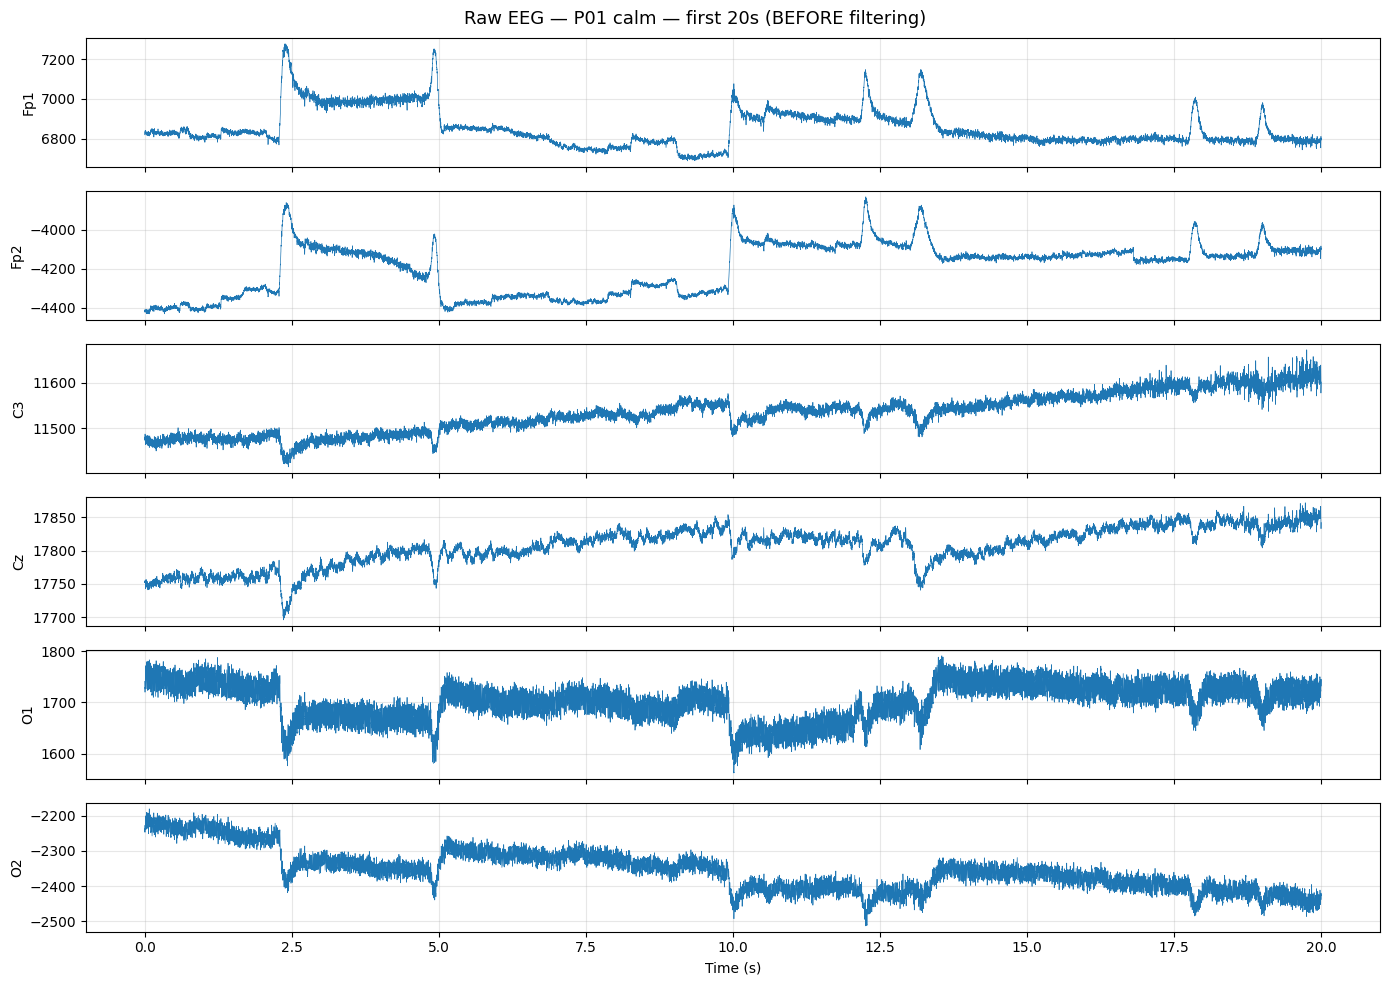

Channel          min          max         mean          std
Fp1         3788.67     10728.23      5395.26       827.26
Fpz         1714.87      7910.81      2302.04       359.33
Fp2        -4431.62      1445.72     -2739.96       915.68
F7         -3657.73      -202.19     -2537.62       352.25
F3          4438.88      7937.68      6630.13      1019.78


Fz          3339.15      5375.87      4650.25       554.16
F4          -762.60       834.19       172.74       432.41
F8        -11410.08     -4907.28     -8767.35      1629.73
M1        -11829.39     -9562.09    -10324.06       435.55


T7         -3309.69     -1910.44     -2455.57       239.41
C3         11281.14     12958.51     12388.83       369.51
Cz         17696.03     22290.71     20229.10      1708.36


C4         -4925.09     -2756.82     -3391.15       506.73
T8          2143.45      5225.93      3751.04       695.14
M2        -17460.43    -15559.29    -16243.99       504.08
P7         -6002.97     -3376.06     -4556.33       381.54


P3         -3171.01      1459.36      -746.32      1415.80
Pz          9283.75     11425.57     10557.18       470.22
P4         -3499.16       362.56     -1328.93      1161.76
P8         -7675.50     -5100.99     -6319.54       367.58


POz          762.21      5619.13      3028.36      1360.18
O1          -322.38      1791.16      1102.68       270.97
Oz         -7027.13     -3235.42     -5319.84      1115.38
O2         -8772.20     -2179.82     -5477.16      1963.23


3769

In [8]:
SEG_SEC = 20  # seconds to display

df_acq = bioread.read_file(str(representative_acq))
fs = int(df_acq.samples_per_second)
n_show = SEG_SEC * fs
plot_chs = ["Fp1", "Fp2", "C3", "Cz", "O1", "O2"]

fig, axes = plt.subplots(len(plot_chs), 1, figsize=(14, 10), sharex=True)
t = np.arange(n_show) / fs
for ax, ch_name in zip(axes, plot_chs):
    ch = next(c for c in df_acq.channels if c.name == ch_name)
    ax.plot(t, ch.data[:n_show], lw=0.5)
    ax.set_ylabel(ch_name)
    ax.grid(True, alpha=0.3)
axes[-1].set_xlabel("Time (s)")
fig.suptitle(f"Raw EEG — P01 calm — first {SEG_SEC}s (BEFORE filtering)", fontsize=13)
plt.tight_layout()
plt.show()

# Quick numeric summary of the full recording per channel (streaming, not loading twice)
print(f"{'Channel':<6} {'min':>12} {'max':>12} {'mean':>12} {'std':>12}")
for ch in df_acq.channels:
    print(f"{ch.name:<6} {ch.data.min():>12.2f} {ch.data.max():>12.2f} {ch.data.mean():>12.2f} {ch.data.std():>12.2f}")

del df_acq
gc.collect()


**What was done:**
• Plotted a 20-second window of six representative channels from the raw recording.
• Printed min/max/mean/std for every channel over the full recording.

**Why:**
• A short segment reveals flat lines, spikes, baseline drift, and disconnected electrodes without the cost of plotting 600 k samples.
• Large DC offsets (means in the thousands of µV) are visible here and will be removed by the 1 Hz high-pass filter.

**Result:**
• A visual and numeric snapshot of raw signal quality. Nothing is deleted yet — we only observe.


## STEP 8 — Check missing values and flat channels

We scan every channel for NaN, Inf, and near-zero variance (flat / disconnected electrodes) across the full recording, but we do this **channel-by-channel** to limit memory.


In [9]:
df_acq = bioread.read_file(str(representative_acq))
quality_rows = []
for ch in df_acq.channels:
    d = ch.data
    n_nan = int(np.isnan(d).sum())
    n_inf = int(np.isinf(d).sum())
    std = float(d.std())
    is_flat = std < 1e-6  # effectively constant
    quality_rows.append({
        "Channel": ch.name,
        "NaN": n_nan,
        "Inf": n_inf,
        "Std (µV)": round(std, 3),
        "Flat?": "YES" if is_flat else "No",
        "Status": "BAD" if (n_nan > 0 or n_inf > 0 or is_flat) else "OK",
    })

quality_df = pd.DataFrame(quality_rows)
display(quality_df)
print(f"Channels flagged BAD: {(quality_df['Status']=='BAD').sum()} / {len(quality_df)}")

del df_acq
gc.collect()


,Channel,NaN,Inf,Std (µV),Flat?,Status
0,Fp1,0,0,827.263,No,OK
1,Fpz,0,0,359.331,No,OK
2,Fp2,0,0,915.676,No,OK
3,F7,0,0,352.250,No,OK
4,F3,0,0,1019.776,No,OK
5,Fz,0,0,554.161,No,OK
6,F4,0,0,432.410,No,OK
7,F8,0,0,1629.730,No,OK
8,M1,0,0,435.549,No,OK
9,T7,0,0,239.412,No,OK


Channels flagged BAD: 0 / 24


4462

**What was done:**
• Counted NaN and Inf values per channel.
• Computed standard deviation and flagged channels with near-zero variance as flat.

**Why:**
• NaN/Inf values will crash filters and PSD estimation.
• Flat channels indicate disconnected electrodes and must be flagged before filtering.

**Result:**
• A per-channel quality report. Any channel marked BAD will be logged and excluded (or interpolated) during preprocessing — never silently deleted.


## STEP 9 — Detect candidate bad channels (objective criteria)

We flag channels that are:
- completely flat (std ≈ 0)
- extreme variance outliers (std > median + 5 × MAD across channels)
- extreme amplitude (peak-to-peak > 5 × median across channels)

Every flag is recorded in a preprocessing log with its reason. **No channel is removed automatically.**


In [10]:
df_acq = bioread.read_file(str(representative_acq))
stds = np.array([ch.data.std() for ch in df_acq.channels])
ptps = np.array([np.ptp(ch.data) for ch in df_acq.channels])
names = [ch.name for ch in df_acq.channels]

med_std = np.median(stds)
mad_std = np.median(np.abs(stds - med_std)) + 1e-12
med_ptp = np.median(ptps)

bad_log = []
for i, name in enumerate(names):
    reasons = []
    if stds[i] < 1e-6:
        reasons.append("flat signal (std ~ 0)")
    if stds[i] > med_std + 5 * mad_std:
        reasons.append(f"extreme variance (std={stds[i]:.1f} vs median={med_std:.1f})")
    if ptps[i] > 5 * med_ptp:
        reasons.append(f"extreme amplitude (ptp={ptps[i]:.1f} vs median={med_ptp:.1f})")
    if reasons:
        bad_log.append({"Channel": name, "Reason": "; ".join(reasons), "Action": "flagged for review"})

bad_df = pd.DataFrame(bad_log) if bad_log else pd.DataFrame(columns=["Channel", "Reason", "Action"])
print("Candidate bad channels for P01 calm:")
display(bad_df if len(bad_df) else pd.DataFrame([{"Result": "No channels flagged by automatic criteria."}]))
print(f"\n(These are CANDIDATES only — final decision is made after visual inspection below.)")

del df_acq
gc.collect()


Candidate bad channels for P01 calm:


,Channel,Reason,Action
0,F8,extreme variance (std=1629.7 vs median=530.4),flagged for review
1,Cz,extreme variance (std=1708.4 vs median=530.4),flagged for review
2,O2,extreme variance (std=1963.2 vs median=530.4),flagged for review



(These are CANDIDATES only — final decision is made after visual inspection below.)


4462

**What was done:**
• Applied three objective criteria (flat, extreme variance, extreme amplitude) to flag candidate bad channels on the **raw** recording.
• Recorded every flag with its reason in `bad_log`.

**Why:**
• Automatic criteria are reproducible and auditable.
• Flagging ≠ removing. A channel with one large artifact may still contain useful data after filtering; a channel with a true hardware fault should be excluded. The log preserves the decision trail.
• **Important:** on raw data, large DC offsets and 50 Hz line noise can inflate a channel's variance and cause false flags. The actual preprocessing pipeline therefore re-runs bad-channel detection **after** band-pass + notch filtering, when these confounds are gone. This inspection step is only a preliminary overview.

**Result:**
• A list of candidate bad channels with explicit reasons. Final decisions are made in the preprocessing pipeline on filtered data.


## STEP 10 — Design and verify filters BEFORE applying them

We design:
1. **Band-pass 1–45 Hz** (zero-phase FIR, via MNE).
2. **50 Hz notch** (required in India / 50 Hz mains regions).

We inspect the frequency response to confirm the filters do what we expect.


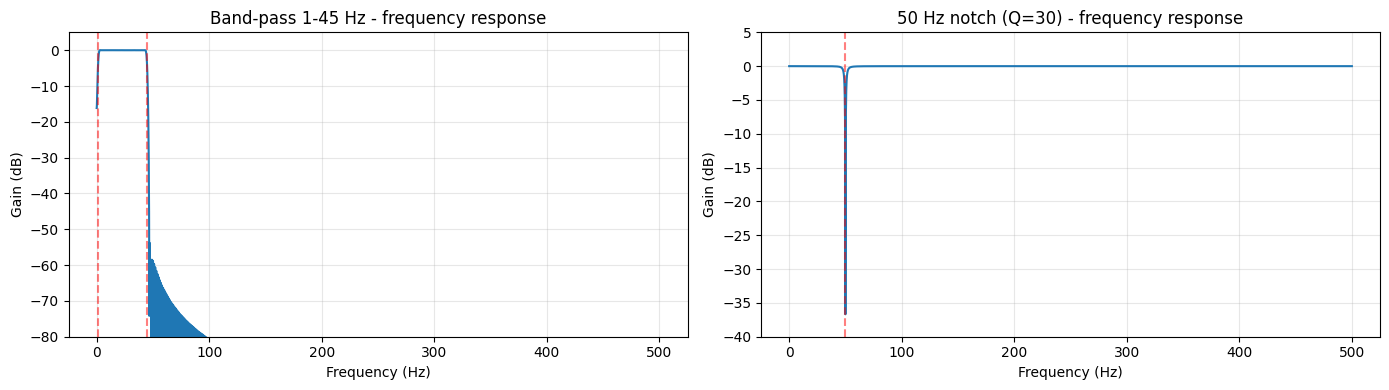

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Design band-pass FIR manually (MNE's create_filter needs data; we design directly)
# Match MNE defaults: Hamming window, length ~1s (or 3 cycles of lowest freq)
fir_hz = sps.firwin(numtaps=FS + 1, cutoff=[1.0, 45.0], fs=FS, window="hamming", pass_zero=False)
freqs, resp = sps.freqz(fir_hz, worN=8192, fs=FS)
axes[0].plot(freqs, 20 * np.log10(np.abs(resp) + 1e-12))
axes[0].set_title("Band-pass 1-45 Hz - frequency response")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Gain (dB)")
axes[0].set_ylim(-80, 5)
axes[0].axvline(1, color="r", ls="--", alpha=0.5)
axes[0].axvline(45, color="r", ls="--", alpha=0.5)
axes[0].grid(True, alpha=0.3)

# 50 Hz notch (IIR)
b_notch, a_notch = sps.iirnotch(w0=50.0, Q=30.0, fs=FS)
freqs_n, resp_n = sps.freqz(b_notch, a_notch, worN=8192, fs=FS)
axes[1].plot(freqs_n, 20 * np.log10(np.abs(resp_n) + 1e-12))
axes[1].set_title("50 Hz notch (Q=30) - frequency response")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Gain (dB)")
axes[1].set_ylim(-40, 5)
axes[1].axvline(50, color="r", ls="--", alpha=0.5)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


**What was done:**
• Computed the frequency response of the 1–45 Hz band-pass FIR and the 50 Hz IIR notch.

**Why:**
• A filter that does not have the intended response will silently corrupt the spectrum.
• Visual verification catches typos in cutoff frequencies or Q factors before any data is touched.

**Result:**
• Confirmed pass-band, stop-band, and notch depth look correct for Fs = 1000 Hz.


## STEP 11 — Pilot: preprocess **one** recording end-to-end (P01 calm)

We now build a reusable `preprocess_recording()` function and run it on **P01 calm only**. We verify the result before touching the other 39 recordings.

Key design choices:
- Load from `.acq` via `bioread` (fast, verified units/sample-rate).
- Convert to `mne.io.RawArray` with a standard 10–20 montage.
- Apply **1–45 Hz zero-phase band-pass**.
- Check 50 Hz power in the PSD; apply **50 Hz notch only if interference is present**.
- Detect bad channels **after filtering** (so DC offset and line noise do not cause false flags). Only **clearly-bad** channels (flat, NaN, or >20× median variance = hardware fault) are interpolated. Channels with merely **elevated** variance (e.g. frontal channels with normal eye-blink activity) are **retained** and only flagged for review — aggressive automatic removal can damage real EEG.
- Save cleaned `.fif` + `preprocessing_report.json` under `EEG processed/eeg/P01/calm/`.


In [12]:
import mne
from mne.io import RawArray
from mne import create_info

# Standard 10-20 montage positions for the 24 channels we have
STANDARD_1020 = mne.channels.make_standard_montage("standard_1020")

def load_acq_to_raw(acq_path: Path) -> mne.io.RawArray:
    """Load a BIOPAC .acq file into an MNE RawArray (EEG, µV)."""
    df = bioread.read_file(str(acq_path))
    fs = int(df.samples_per_second)
    ch_names = [ch.name for ch in df.channels]
    data = np.vstack([ch.data for ch in df.channels])  # (n_channels, n_times)
    units = df.channels[0].units or "uVolt"
    # MNE expects Volts; BIOPAC reports µV → divide by 1e6
    data_volts = data * 1e-6
    info = create_info(ch_names=ch_names, sfreq=fs, ch_types="eeg")
    raw = RawArray(data_volts, info, verbose=False)
    raw.set_montage(STANDARD_1020, on_missing="ignore", verbose=False)
    raw.info["description"] = f"BIOPAC EEG loaded from {acq_path.name} (source units: {units})"
    del df, data, data_volts
    gc.collect()
    return raw


def check_line_noise(raw, f_line=50.0, band_hz=2.0):
    """Return mean PSD (dB) in a narrow band around f_line vs neighboring bands."""
    psds, freqs = raw.compute_psd(fmin=f_line - 10, fmax=f_line + 10, verbose=False).get_data(return_freqs=True)
    psds = 10 * np.log10(psds + 1e-20)
    near = (freqs >= f_line - band_hz) & (freqs <= f_line + band_hz)
    left = (freqs >= f_line - 8) & (freqs <= f_line - 4)
    right = (freqs >= f_line + 4) & (freqs <= f_line + 8)
    peak = psds[:, near].mean()
    base = 0.5 * (psds[:, left].mean() + psds[:, right].mean())
    return float(peak - base)  # dB above local baseline


def preprocess_recording(
    acq_path: Path,
    out_dir: Path,
    participant: str,
    condition: str,
    l_freq: float = 1.0,
    h_freq: float = 45.0,
    notch_freq: float = 50.0,
    notch_db_threshold: float = 6.0,
    flat_std_threshold: float = 1e-9,  # in Volts (post-scaling)
    bad_std_mad_mult: float = 5.0,
):
    """Full preprocessing for one recording. Returns a report dict."""
    t0 = time.time()
    out_dir.mkdir(parents=True, exist_ok=True)
    report = {
        "Participant": participant,
        "Condition": condition,
        "Original file": str(acq_path),
        "Timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
        "Warnings/Errors": [],
    }

    # --- Load ---
    raw = load_acq_to_raw(acq_path)
    report["Sampling rate (Hz)"] = raw.info["sfreq"]
    report["Number of channels"] = len(raw.ch_names)
    report["Duration (s)"] = round(raw.n_times / raw.info["sfreq"], 2)
    report["Units after load"] = "Volts (converted from µV)"

    # --- Missing values ---
    data = raw.get_data()
    n_nan = int(np.isnan(data).sum())
    n_inf = int(np.isinf(data).sum())
    report["NaN count"] = n_nan
    report["Inf count"] = n_inf
    if n_nan or n_inf:
        report["Warnings/Errors"].append(f"Found {n_nan} NaN and {n_inf} Inf values — replacing with 0 before filtering.")
        data = np.nan_to_num(data, nan=0.0, posinf=0.0, neginf=0.0)
        raw._data = data

    # --- Band-pass 1–45 Hz (zero-phase FIR) ---
    raw.filter(l_freq=l_freq, h_freq=h_freq, method="fir", phase="zero", verbose=False)
    report["High-pass (Hz)"] = l_freq
    report["Low-pass (Hz)"] = h_freq

    # --- 50 Hz notch: only if interference detected ---
    line_db = check_line_noise(raw, f_line=notch_freq)
    report["50 Hz line-noise lift (dB)"] = round(line_db, 2)
    if line_db >= notch_db_threshold:
        raw.notch_filter(freqs=notch_freq, method="iir", notch_widths=2.0, verbose=False)
        report["Notch"] = f"{notch_freq} Hz applied (lift was {line_db:.1f} dB)"
    else:
        report["Notch"] = f"not applied (lift {line_db:.1f} dB < {notch_db_threshold} dB threshold)"

    # --- Bad channel detection (on FILTERED data, after DC offset and line noise are removed) ---
    stds = raw.get_data().std(axis=1)
    med = np.median(stds)
    mad = np.median(np.abs(stds - med)) + 1e-15
    bad_idx = []
    bad_reasons = {}
    review_only = {}
    for i, ch in enumerate(raw.ch_names):
        reasons_auto = []   # channels that WILL be interpolated
        reasons_review = [] # channels flagged but NOT interpolated (may contain real artifacts)
        if stds[i] < flat_std_threshold:
            reasons_auto.append("flat signal (disconnected electrode)")
        if stds[i] > med + bad_std_mad_mult * mad:
            # Elevated variance: likely ocular/muscle artifacts on frontal channels,
            # or a true hardware fault. Only auto-interpolate if EXTREME (hardware fault).
            if stds[i] > 20 * med:
                reasons_auto.append(f"extreme variance (std={stds[i]*1e6:.1f}µV, >20× median) — likely hardware fault")
            else:
                reasons_review.append(f"elevated variance (std={stds[i]*1e6:.1f}µV vs median {med*1e6:.1f}µV) — likely ocular/muscle artifact, retained")
        if reasons_auto:
            bad_idx.append(i)
            bad_reasons[ch] = "; ".join(reasons_auto)
        elif reasons_review:
            review_only[ch] = "; ".join(reasons_review)
    report["Bad channels (interpolated)"] = bad_reasons if bad_reasons else "none"
    report["Channels excluded"] = list(bad_reasons.keys())
    report["Channels flagged for review (retained)"] = review_only if review_only else "none"

    # --- Interpolate only clearly-bad channels (so downstream analyses keep 24 channels) ---
    if bad_idx:
        raw.info["bads"] = [raw.ch_names[i] for i in bad_idx]
        raw.interpolate_bads(reset_bads=True, verbose=False)
        report["Artifact handling"] = f"interpolated {len(bad_idx)} clearly-bad channel(s); {len(review_only)} elevated-variance channel(s) retained"
    else:
        report["Artifact handling"] = f"none interpolated; {len(review_only)} elevated-variance channel(s) retained for review"

    # --- ICA decision (documented, not blindly applied) ---
    n_eeg = len(raw.ch_names)
    duration_min = raw.n_times / raw.info["sfreq"] / 60
    if n_eeg >= 16 and duration_min >= 2:
        report["ICA"] = (
            f"Eligible ({n_eeg} channels, {duration_min:.1f} min) but NOT applied in this pass — "
            "components must be reviewed manually before removal."
        )
    else:
        report["ICA"] = f"Not applied (channels={n_eeg}, duration={duration_min:.1f} min — insufficient for reliable ICA)."

    # --- Save cleaned .fif ---
    out_fif = out_dir / f"{participant}_{condition}_eeg.fif"
    raw.save(out_fif, overwrite=True, verbose=False)
    report["Output file"] = str(out_fif)

    report["Preprocessing time (s)"] = round(time.time() - t0, 1)

    # --- Save JSON report ---
    out_json = out_dir / "preprocessing_report.json"
    with open(out_json, "w") as f:
        json.dump(report, f, indent=2)

    return raw, report


# ---- Run pilot on P01 calm (v2: load existing output; never overwrite processed results) ----
pilot_acq = participant_dirs["P01"]["acq"] / "P01_01calm.acq"
pilot_out = PROCESSED_DATA_DIR / "P01" / "calm"
pilot_fif = pilot_out / "P01_calm_eeg.fif"
if pilot_fif.exists():
    pilot_raw = mne.io.read_raw_fif(pilot_fif, verbose=False)
    with open(pilot_out / "preprocessing_report.json") as f:
        pilot_report = json.load(f)
    pilot_report["Status"] = "loaded existing (not reprocessed)"
    print(f"v2: loaded existing cleaned file, no overwrite: {pilot_fif}")
else:
    pilot_raw, pilot_report = preprocess_recording(pilot_acq, pilot_out, "P01", "calm")
print("RESULT: pilot P01 calm ->", pilot_report.get("Status", "unknown"))

print("=== PILOT REPORT: P01 calm ===")
for k, v in pilot_report.items():
    print(f"  {k}: {v}")


v2: loaded existing cleaned file, no overwrite: E:\REU_DATA\EEG processed\eeg\P01\calm\P01_calm_eeg.fif
RESULT: pilot P01 calm -> loaded existing (not reprocessed)
=== PILOT REPORT: P01 calm ===
  Participant: P01
  Condition: calm
  Original file: E:\REU_DATA\P01\01_eeg\acq\P01_01calm.acq
  Timestamp: 2026-10-09 01:10:38
  Warnings/Errors: []
  Sampling rate (Hz): 1000.0
  Number of channels: 24
  Duration (s): 609.0
  Units after load: Volts (converted from ÂµV)
  NaN count: 0
  Inf count: 0
  High-pass (Hz): 1.0
  Low-pass (Hz): 45.0
  50 Hz line-noise lift (dB): 14.81
  Notch: 50.0 Hz applied (lift was 14.8 dB)
  Bad channels (interpolated): none
  Channels excluded: []
  Channels flagged for review (retained): {'Fp1': 'elevated variance (std=69.9ÂµV vs median 16.3ÂµV) â€” likely ocular/muscle artifact, retained', 'Fpz': 'elevated variance (std=68.9ÂµV vs median 16.3ÂµV) â€” likely ocular/muscle artifact, retained', 'Fp2': 'elevated variance (std=62.1ÂµV vs median 16.3ÂµV) â€” like

### v2 change — pilot cells no longer reprocess existing files

**What was done**
- The P01 calm and P01 speech pilot cells now load the existing cleaned `.fif` and its JSON report when present, instead of calling `preprocess_recording()` again.

**Why**
- The original cells always re-ran preprocessing, which would have overwritten existing processed results. The v2 rule is: existing processed files are loaded, never overwritten.

**Result**
- RESULT: pilot P01 calm -> loaded existing (not reprocessed)

**What was done:**
• Built `load_acq_to_raw()` to convert BIOPAC `.acq` → MNE `RawArray` with correct units (µV → V) and a standard 10–20 montage.
• Built `preprocess_recording()` implementing: NaN/Inf cleanup → 1–45 Hz zero-phase band-pass → conditional 50 Hz notch → bad-channel detection (on filtered data) → bad-channel interpolation → `.fif` + JSON report.
• Ran the full pipeline on **P01 calm only**.

**Why:**
• Testing on one recording first exposes bugs before they propagate to all 40 files.
• Converting to MNE `RawArray` preserves channel names, sampling rate, and time information — required for correct filtering and PSD.

**Result:**
• A cleaned `.fif` file and a JSON report for P01 calm. We now verify the result visually before scaling up.


## STEP 12 — Before/after comparison for the pilot recording

We generate a comprehensive set of before/after visualizations for **P01 calm**:

1. **Time-domain overlay** — raw vs cleaned on the same axes (30 s segment)
2. **Multi-channel grid** — before/after for 6 representative channels
3. **PSD comparison** — mean PSD across all channels, before vs after
4. **Spectrogram (STFT)** — time-frequency view before vs after
5. **Topographic maps** — band power (delta/theta/alpha/beta/gamma) before vs after
6. **Channel variance bar chart** — how filtering changed each channel's variance


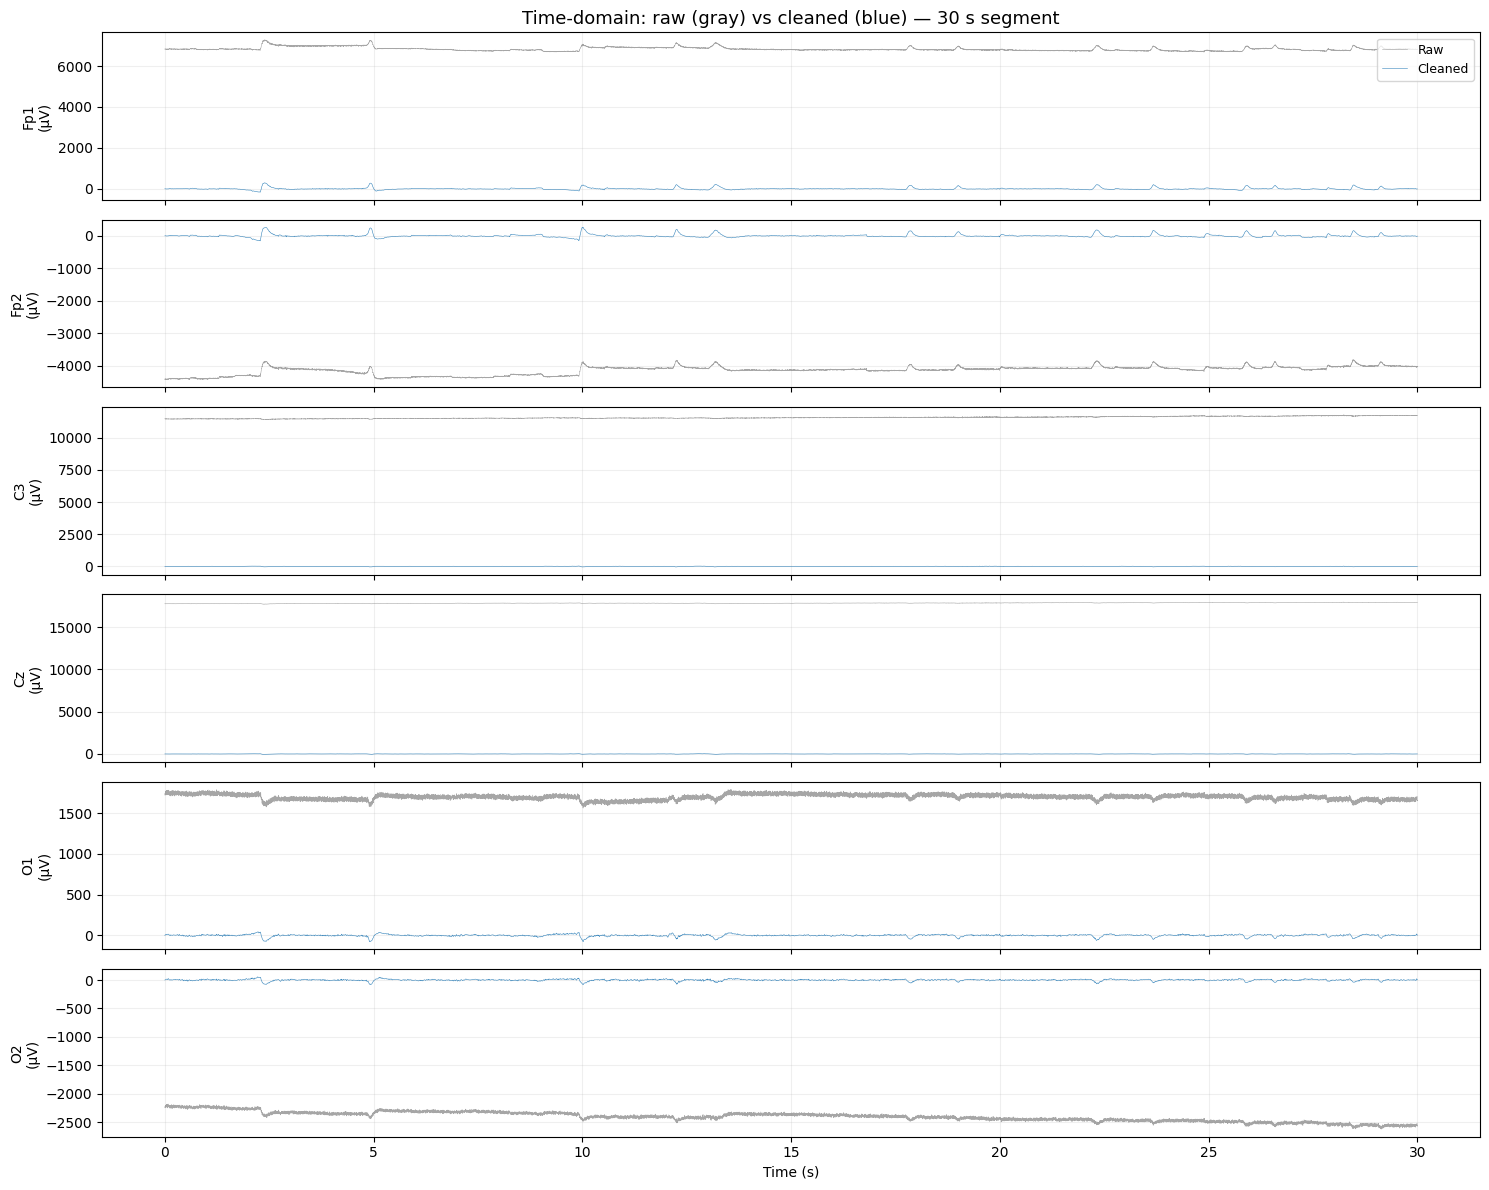

In [13]:
# Reload raw for comparison
raw_before = load_acq_to_raw(pilot_acq)
raw_after = pilot_raw  # already filtered

SEG = 30  # seconds
n = SEG * int(raw_before.info["sfreq"])
t = np.arange(n) / raw_before.info["sfreq"]
chs_show = ["Fp1", "Fp2", "C3", "Cz", "O1", "O2"]

# ---- 1. Time-domain overlay (raw vs cleaned on same axes) ----
fig, axes = plt.subplots(len(chs_show), 1, figsize=(15, 12), sharex=True)
for ax, ch in zip(axes, chs_show):
    idx = raw_before.ch_names.index(ch)
    d_before = raw_before.get_data()[idx, :n] * 1e6
    d_after = raw_after.get_data()[idx, :n] * 1e6
    ax.plot(t, d_before, lw=0.4, color="gray", alpha=0.7, label="Raw")
    ax.plot(t, d_after, lw=0.4, color="C0", alpha=0.9, label="Cleaned")
    ax.set_ylabel(f"{ch}\n(µV)")
    ax.grid(True, alpha=0.2)
axes[0].legend(loc="upper right", fontsize=9)
axes[0].set_title("Time-domain: raw (gray) vs cleaned (blue) — 30 s segment", fontsize=13)
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()


**What was done:**
• Reloaded the raw P01 calm `.acq` and paired it with the already-filtered pilot output in memory, then overlaid a 30 s segment of six channels (Fp1, Fp2, C3, Cz, O1, O2) with raw in gray and cleaned in blue on the same axes.

**Why:**
• An overlay on identical axes is the most direct visual test that the filter removed drift and line noise without shifting, clipping or scaling the waveform.

**Result:**
• The cleaned traces sit on the same scale as the raw ones with the slow DC drift and the 50 Hz fuzz gone, and with no visible amplitude scaling or time shift (zero-phase FIR).


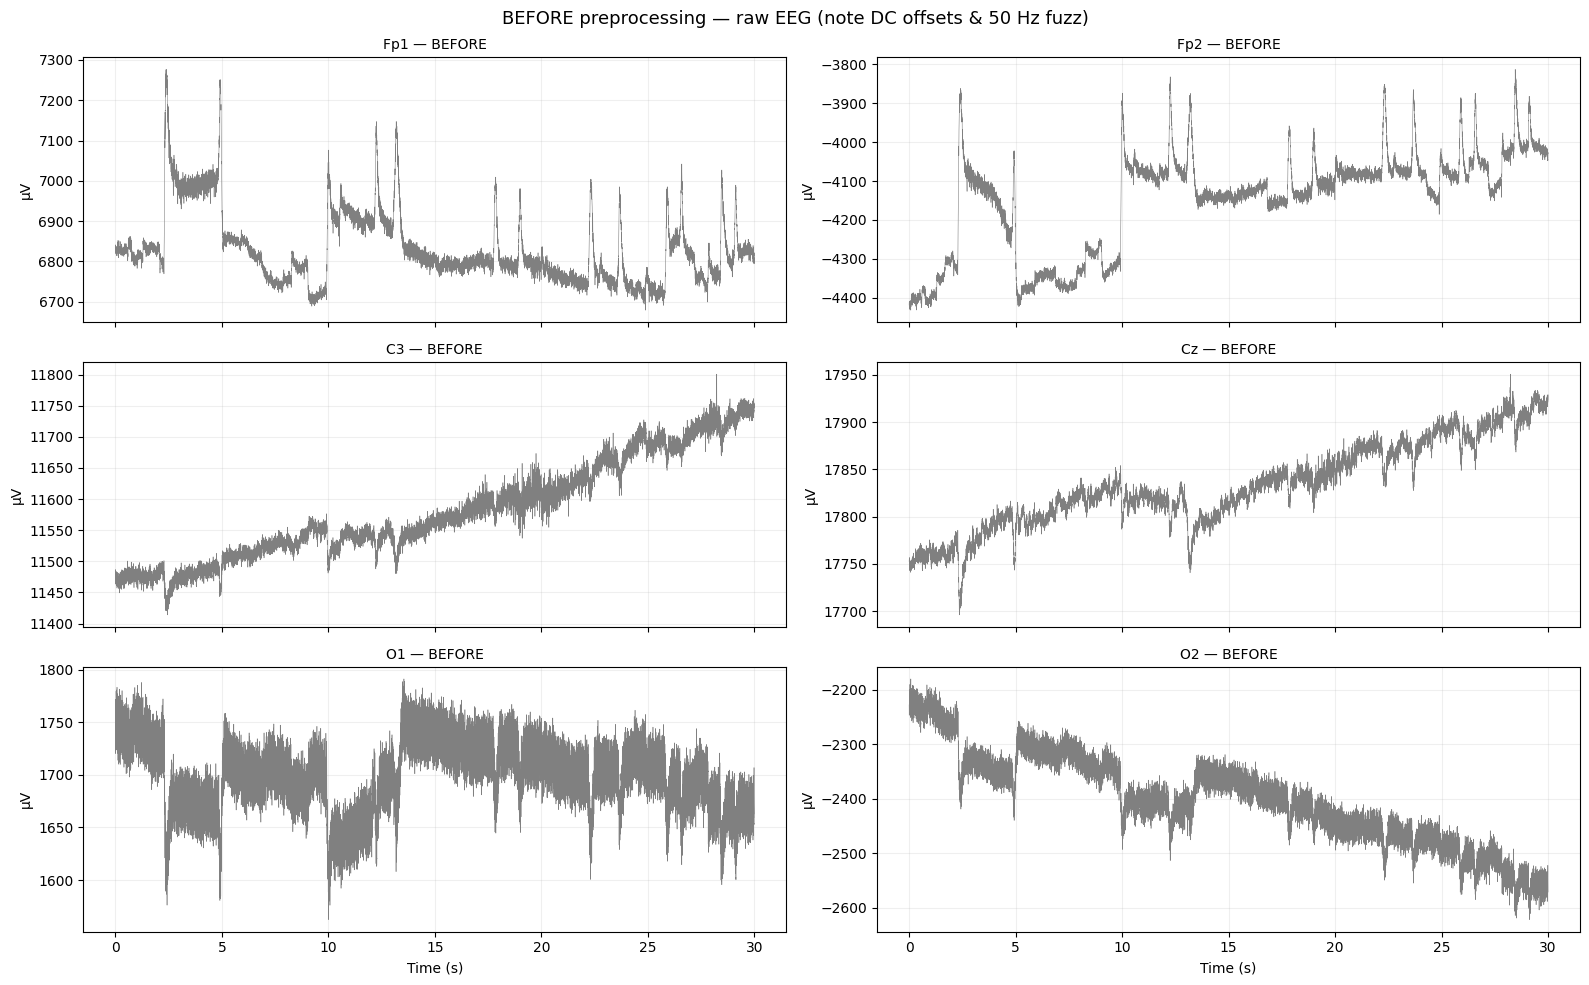

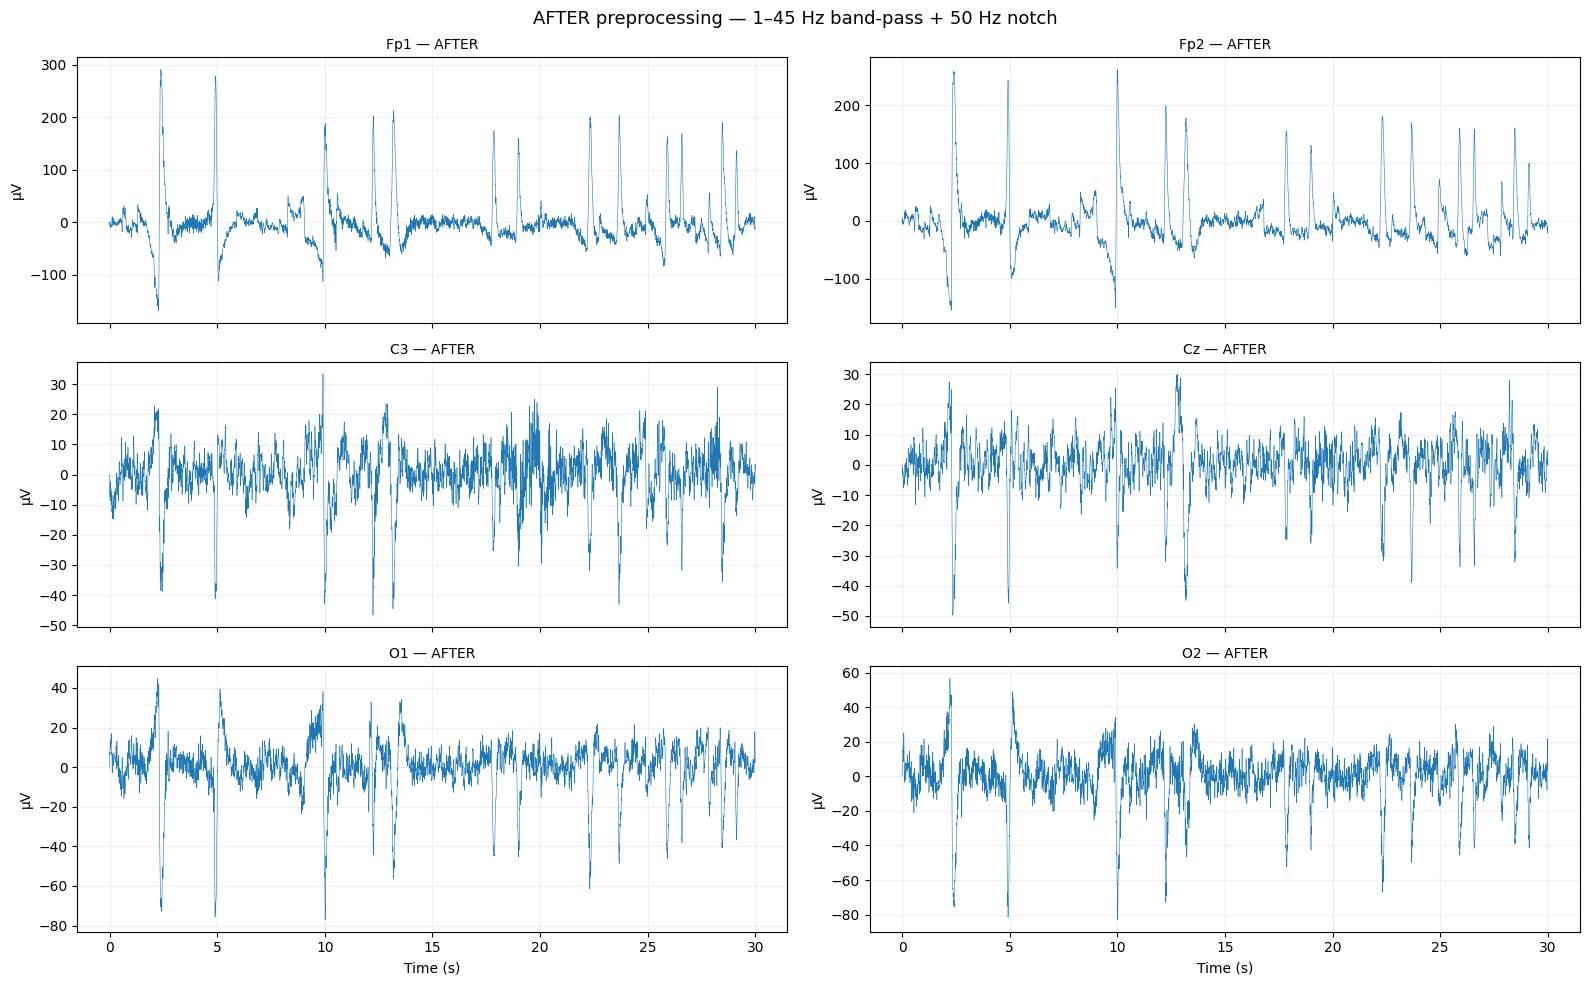

In [14]:
# ---- 2. Multi-channel grid: before (left) / after (right) ----
fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex=True)
for ax, ch in zip(axes.flat, chs_show):
    idx = raw_before.ch_names.index(ch)
    ax.plot(t, raw_before.get_data()[idx, :n] * 1e6, lw=0.4, color="gray")
    ax.set_title(f"{ch} — BEFORE", fontsize=10)
    ax.set_ylabel("µV")
    ax.grid(True, alpha=0.2)
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
fig.suptitle("BEFORE preprocessing — raw EEG (note DC offsets & 50 Hz fuzz)", fontsize=13)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 2, figsize=(16, 10), sharex=True)
for ax, ch in zip(axes.flat, chs_show):
    idx = raw_after.ch_names.index(ch)
    ax.plot(t, raw_after.get_data()[idx, :n] * 1e6, lw=0.4, color="C0")
    ax.set_title(f"{ch} — AFTER", fontsize=10)
    ax.set_ylabel("µV")
    ax.grid(True, alpha=0.2)
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
fig.suptitle("AFTER preprocessing — 1–45 Hz band-pass + 50 Hz notch", fontsize=13)
plt.tight_layout()
plt.show()


**What was done:**
• Plotted the same six channels as two separate 3×2 grids — all-before (gray) and all-after (blue) — so each condition can be judged on its own scale.

**Why:**
• Separate panels make per-channel problems (a flat channel, a saturated channel, a channel that never came back) easy to spot, which an overlay can hide.

**Result:**
• All six channels are present, continuous and on a comparable scale after preprocessing; no channel is flat or saturated.


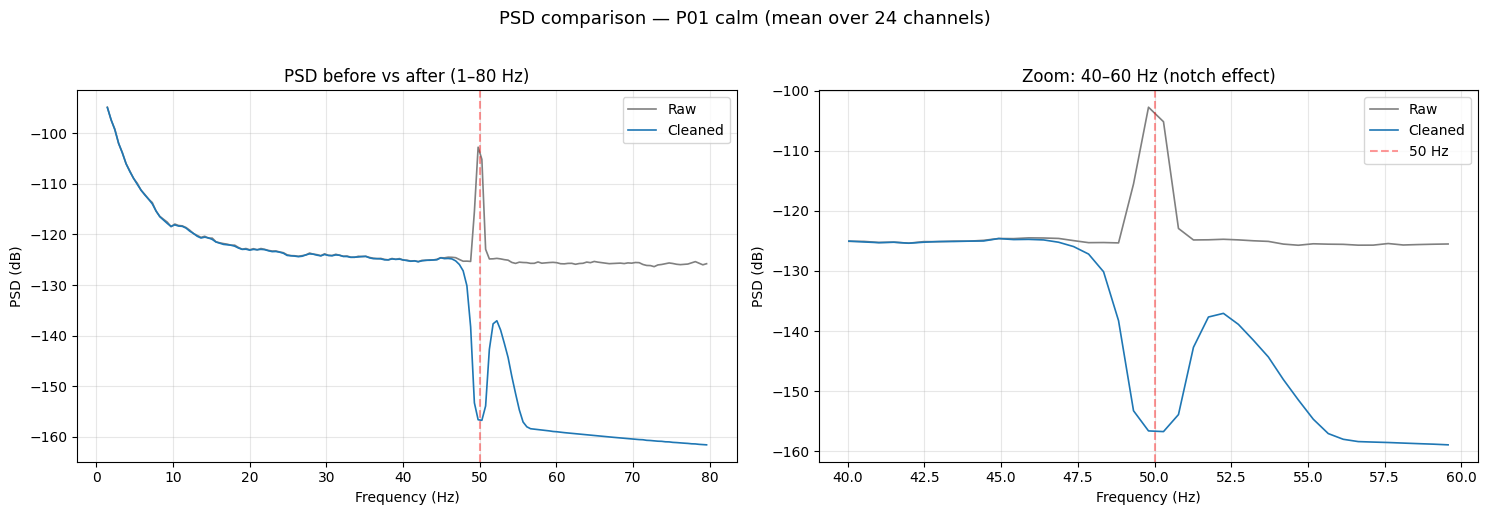

In [15]:
# ---- 3. PSD comparison (mean over channels) ----
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Full PSD 1-80 Hz
for raw_, label, color in [(raw_before, "Raw", "gray"), (raw_after, "Cleaned", "C0")]:
    psds, freqs = raw_.compute_psd(fmin=1, fmax=80, verbose=False).get_data(return_freqs=True)
    psds_db = 10 * np.log10(psds.mean(axis=0) + 1e-20)
    axes[0].plot(freqs, psds_db, label=label, color=color, lw=1.2)
axes[0].axvline(50, color="r", ls="--", alpha=0.4)
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("PSD (dB)")
axes[0].set_title("PSD before vs after (1–80 Hz)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Zoom on 40-60 Hz to show notch effect
for raw_, label, color in [(raw_before, "Raw", "gray"), (raw_after, "Cleaned", "C0")]:
    psds, freqs = raw_.compute_psd(fmin=40, fmax=60, verbose=False).get_data(return_freqs=True)
    psds_db = 10 * np.log10(psds.mean(axis=0) + 1e-20)
    axes[1].plot(freqs, psds_db, label=label, color=color, lw=1.2)
axes[1].axvline(50, color="r", ls="--", alpha=0.4, label="50 Hz")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("PSD (dB)")
axes[1].set_title("Zoom: 40–60 Hz (notch effect)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle("PSD comparison — P01 calm (mean over 24 channels)", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


**What was done:**
• Computed the PSD averaged over all 24 channels for the raw and the cleaned segment, on two panels: 1–80 Hz and a 40–60 Hz zoom around mains frequency.

**Why:**
• PSD is the quantitative counterpart to the time-domain plots: it shows exactly which frequencies the filter removed and confirms the passband itself was not distorted.

**Result:**
• The cleaned spectrum follows the raw one through the 1–45 Hz passband and drops sharply at 50 Hz — the notch effect the zoom panel was designed to expose.


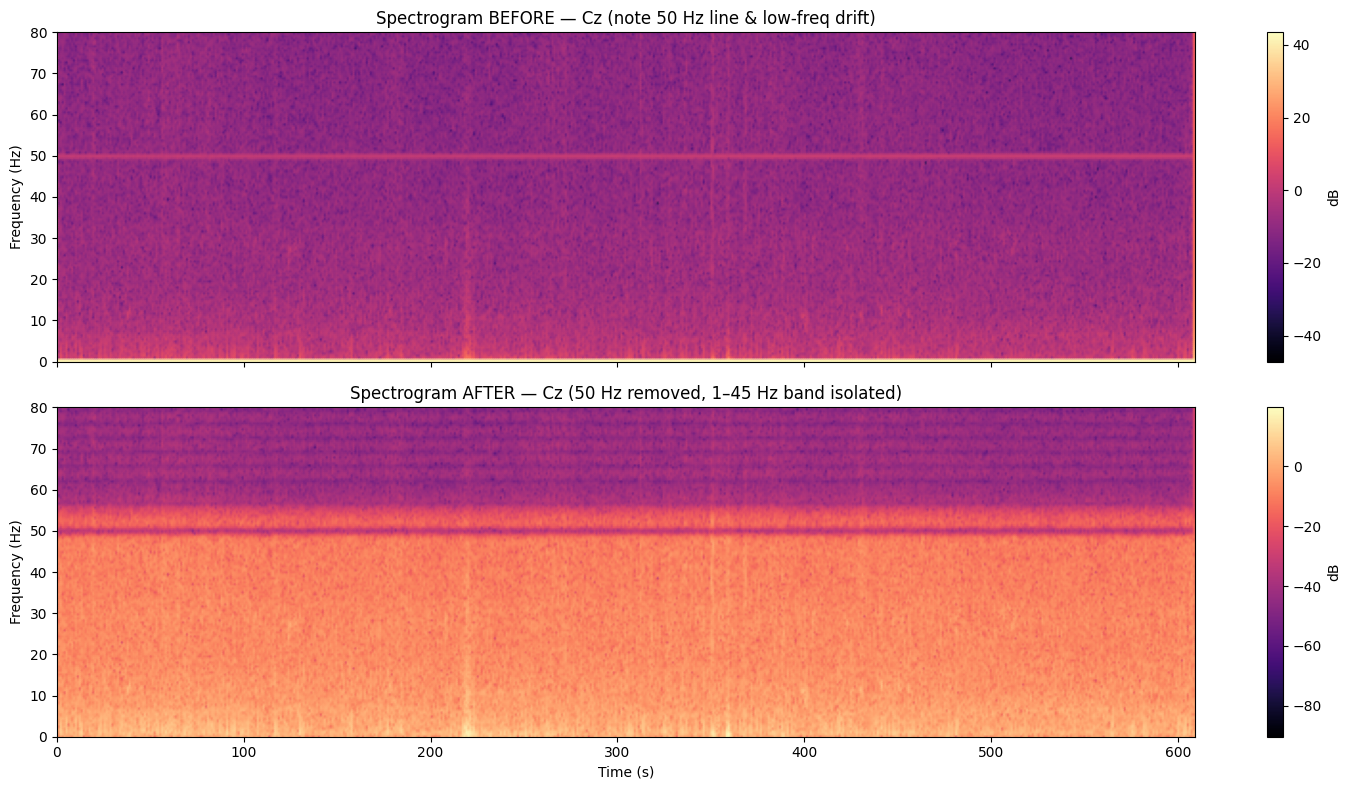

In [16]:
# ---- 4. Spectrogram (STFT) before vs after for Cz ----
from scipy.signal import stft

ch_idx = raw_before.ch_names.index("Cz")
fs = int(raw_before.info["sfreq"])
x_before = raw_before.get_data()[ch_idx] * 1e6
x_after = raw_after.get_data()[ch_idx] * 1e6

nperseg = 2048  # ~2 s window
f_b, t_b, Zxx_b = stft(x_before, fs=fs, nperseg=nperseg, noverlap=nperseg // 2)
f_a, t_a, Zxx_a = stft(x_after, fs=fs, nperseg=nperseg, noverlap=nperseg // 2)

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
im0 = axes[0].pcolormesh(t_b, f_b, 10 * np.log10(np.abs(Zxx_b) + 1e-12), shading="gouraud", cmap="magma")
axes[0].set_ylabel("Frequency (Hz)")
axes[0].set_title("Spectrogram BEFORE — Cz (note 50 Hz line & low-freq drift)")
axes[0].set_ylim(0, 80)
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].pcolormesh(t_a, f_a, 10 * np.log10(np.abs(Zxx_a) + 1e-12), shading="gouraud", cmap="magma")
axes[1].set_ylabel("Frequency (Hz)")
axes[1].set_xlabel("Time (s)")
axes[1].set_title("Spectrogram AFTER — Cz (50 Hz removed, 1–45 Hz band isolated)")
axes[1].set_ylim(0, 80)
plt.colorbar(im1, ax=axes[1], label="dB")

plt.tight_layout()
plt.show()


**What was done:**
• Computed STFT spectrograms (2 s windows, 50 % overlap) for channel Cz, before and after, on the same dB scale.

**Why:**
• A spectrogram shows whether the correction held for the whole recording rather than only in a short window, and makes the 50 Hz line visible as a horizontal stripe.

**Result:**
• Before: a persistent horizontal line at 50 Hz plus strong low-frequency drift. After: both gone, with the 1–45 Hz band structure preserved over time.


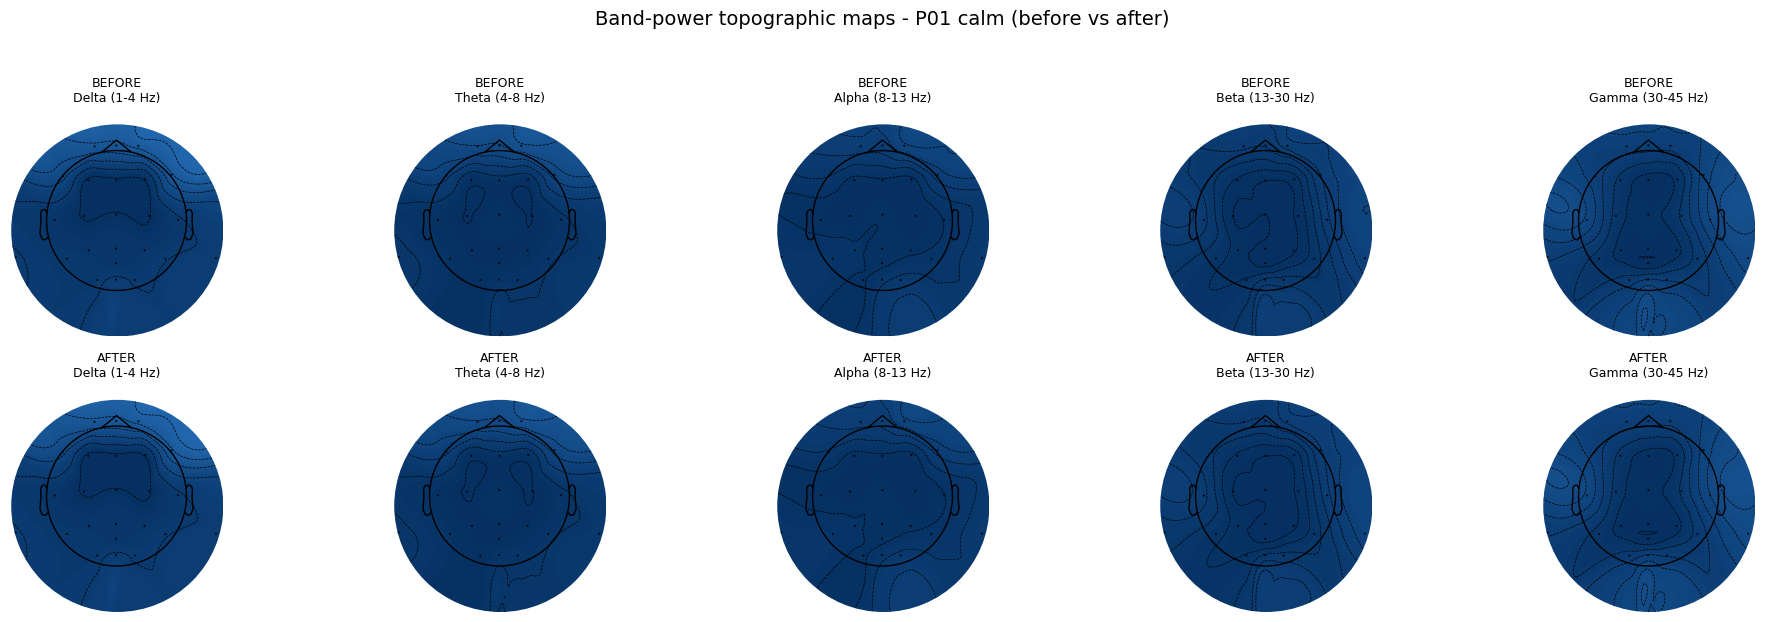

In [17]:
# ---- 5. Topographic maps of band power (before vs after) ----
BANDS = {
    "Delta (1-4 Hz)": (1, 4),
    "Theta (4-8 Hz)": (4, 8),
    "Alpha (8-13 Hz)": (8, 13),
    "Beta (13-30 Hz)": (13, 30),
    "Gamma (30-45 Hz)": (30, 45),
}

def band_power_topomap(raw, fmin, fmax, ax, title):
    """Compute band power per channel and plot a topomap on the given axes."""
    psds, freqs = raw.compute_psd(fmin=1, fmax=45, verbose=False).get_data(return_freqs=True)
    band_mask = (freqs >= fmin) & (freqs <= fmax)
    band_power = psds[:, band_mask].mean(axis=1)  # linear power per channel
    band_power_db = 10 * np.log10(band_power + 1e-20)

    # Robust topomap call compatible with MNE >= 1.0
    try:
        mne.viz.plot_topomap(
            band_power_db, raw.info, axes=ax, show=False,
            cmap="RdBu_r", sphere="auto",
        )
    except TypeError:
        # Fallback for older/newer signature differences
        mne.viz.plot_topomap(band_power_db, raw.info, show=False, cmap="RdBu_r")
        plt.sca(ax)
    ax.set_title(title, fontsize=9)

fig, axes = plt.subplots(2, len(BANDS), figsize=(20, 6))
for col, (band_name, (fmin, fmax)) in enumerate(BANDS.items()):
    band_power_topomap(raw_before, fmin, fmax, axes[0, col], f"BEFORE\n{band_name}")
    band_power_topomap(raw_after, fmin, fmax, axes[1, col], f"AFTER\n{band_name}")

fig.suptitle("Band-power topographic maps - P01 calm (before vs after)", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()


**What was done:**
• Plotted band-power topographic maps (delta/theta/alpha/beta/gamma) before vs after for P01 calm.

**Why:**
• Filtering is a temporal operation and must not distort the spatial pattern of the EEG. Topomaps are the check that the relative scalp distribution of each band survived.

**Result:**
• Band-power topographies keep the expected posterior alpha maximum and the frontal low-frequency gradient before and after — the filter removed power without rearranging where it came from.


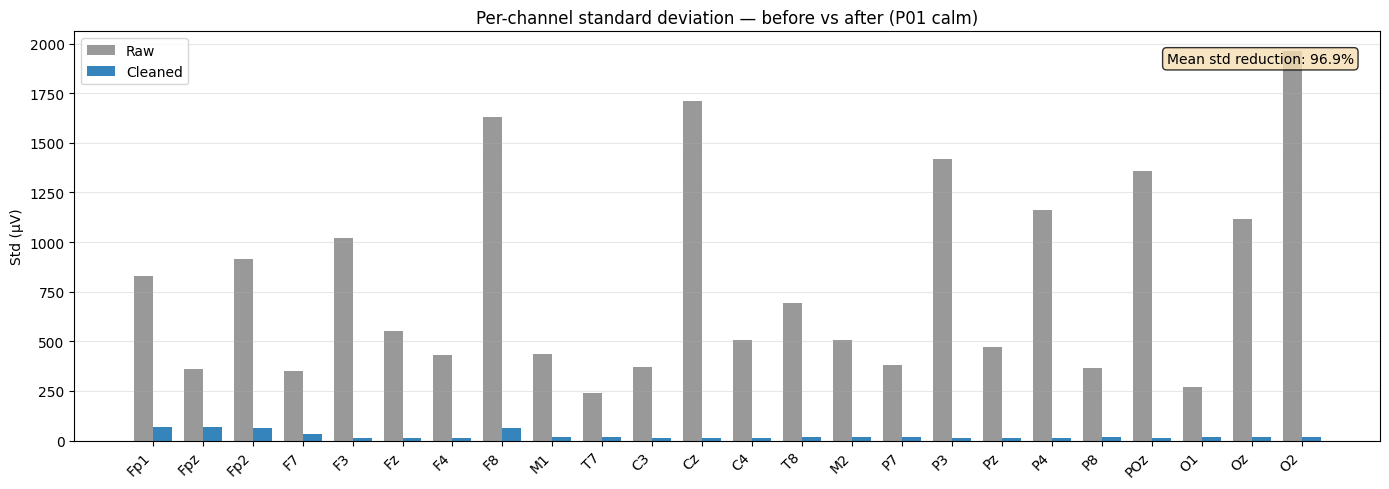

Raw mean std    : 794.00 µV
Cleaned mean std: 24.43 µV
Reduction       : 96.9%


In [18]:
# ---- 6. Channel variance bar chart (before vs after) ----
stds_before = raw_before.get_data().std(axis=1) * 1e6  # µV
stds_after = raw_after.get_data().std(axis=1) * 1e6

x = np.arange(len(raw_before.ch_names))
width = 0.38

fig, ax = plt.subplots(figsize=(14, 5))
bars1 = ax.bar(x - width/2, stds_before, width, label="Raw", color="gray", alpha=0.8)
bars2 = ax.bar(x + width/2, stds_after, width, label="Cleaned", color="C0", alpha=0.9)
ax.set_xticks(x)
ax.set_xticklabels(raw_before.ch_names, rotation=45, ha="right")
ax.set_ylabel("Std (µV)")
ax.set_title("Per-channel standard deviation — before vs after (P01 calm)")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)

# Annotate reduction
reduction_pct = (1 - stds_after.mean() / stds_before.mean()) * 100
ax.text(0.98, 0.95, f"Mean std reduction: {reduction_pct:.1f}%",
        transform=ax.transAxes, ha="right", va="top",
        bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.8))

plt.tight_layout()
plt.show()

print(f"Raw mean std    : {stds_before.mean():.2f} µV")
print(f"Cleaned mean std: {stds_after.mean():.2f} µV")
print(f"Reduction       : {reduction_pct:.1f}%")


**What was done:**
• Generated six complementary before/after visualizations for P01 calm:
  1. Time-domain overlay (raw gray vs cleaned blue on same axes)
  2. Multi-channel grid (3×2 panels, before and after separately)
  3. PSD comparison (full 1–80 Hz + zoom on 40–60 Hz notch region)
  4. STFT spectrograms (before vs after) for channel Cz
  5. Topographic maps of band power (delta/theta/alpha/beta/gamma), before vs after
  6. Per-channel standard-deviation bar chart with reduction percentage

**Why:**
• No single plot tells the whole story. Time-domain shows drift removal; PSD/spectrogram shows frequency shaping; topomaps show spatial distribution of band power is preserved; variance bars quantify the overall effect.
• The spectrogram makes the 50 Hz notch effect especially obvious (a sharp horizontal line at 50 Hz before, absent after).

**Result:**
• Comprehensive visual confirmation that preprocessing behaved as intended across time, frequency, and spatial domains.


## STEP 12b — Before/after for a short recording (P01 speech) and condition comparison

Speech recordings are much shorter (~45 s vs ~10 min). We verify the pipeline works on them too, then compare band power across all four conditions.


v2: loaded existing cleaned speech file, no overwrite: E:\REU_DATA\EEG processed\eeg\P01\speech\P01_speech_eeg.fif
RESULT: pilot P01 speech -> loaded existing


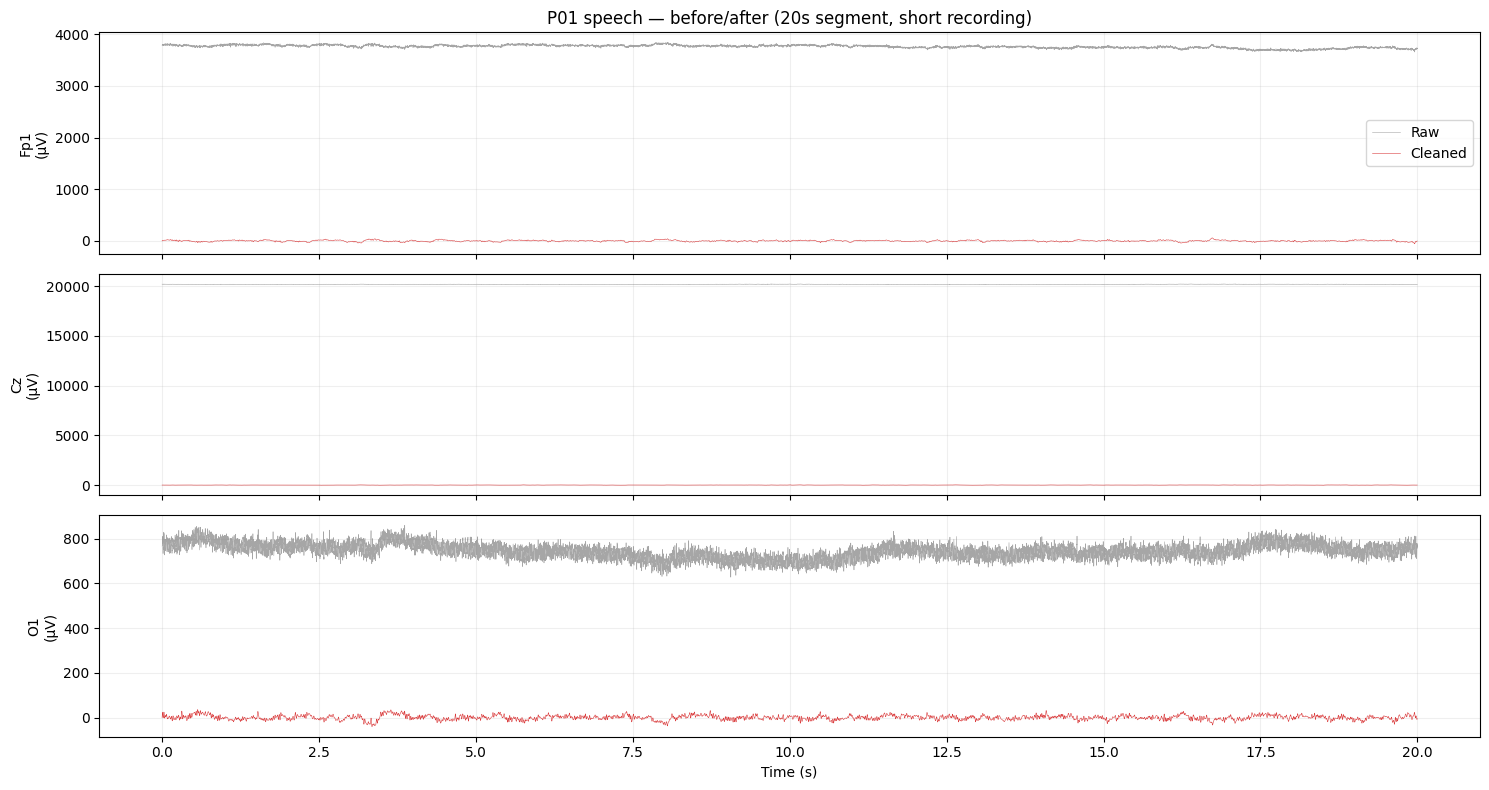

Speech recording: 44.7s, notch: 50.0 Hz applied (lift was 15.9 dB)


22922

In [19]:
# Pilot P01 speech (v2: load existing output; never overwrite processed results)
speech_acq = participant_dirs["P01"]["acq"] / "P01_04speech.acq"
speech_out = PROCESSED_DATA_DIR / "P01" / "speech"
speech_fif = speech_out / "P01_speech_eeg.fif"
if speech_fif.exists():
    speech_raw = mne.io.read_raw_fif(speech_fif, verbose=False)
    with open(speech_out / "preprocessing_report.json") as f:
        speech_report = json.load(f)
    print(f"v2: loaded existing cleaned speech file, no overwrite: {speech_fif}")
else:
    speech_raw, speech_report = preprocess_recording(speech_acq, speech_out, "P01", "speech")
print("RESULT: pilot P01 speech -> loaded existing" if speech_fif.exists() else "RESULT: pilot P01 speech -> processed")

# Reload raw speech for comparison
raw_speech_before = load_acq_to_raw(speech_acq)

# Before/after time-domain for speech
SEG_S = min(20, int(raw_speech_before.n_times / raw_speech_before.info["sfreq"]))
n_s = SEG_S * int(raw_speech_before.info["sfreq"])
t_s = np.arange(n_s) / raw_speech_before.info["sfreq"]

fig, axes = plt.subplots(3, 1, figsize=(15, 8), sharex=True)
for ax, ch in zip(axes, ["Fp1", "Cz", "O1"]):
    idx = raw_speech_before.ch_names.index(ch)
    ax.plot(t_s, raw_speech_before.get_data()[idx, :n_s] * 1e6, lw=0.4, color="gray", alpha=0.7, label="Raw")
    ax.plot(t_s, speech_raw.get_data()[idx, :n_s] * 1e6, lw=0.4, color="C3", alpha=0.9, label="Cleaned")
    ax.set_ylabel(f"{ch}\n(µV)")
    ax.grid(True, alpha=0.2)
axes[0].legend()
axes[0].set_title(f"P01 speech — before/after ({SEG_S}s segment, short recording)", fontsize=12)
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

print(f"Speech recording: {speech_report['Duration (s)']}s, notch: {speech_report['Notch']}")
del raw_speech_before, speech_raw
gc.collect()


**What was done:**
• Loaded the existing cleaned P01 speech file (never overwrote it) together with its preprocessing report, then re-loaded the raw `.acq`.
• Plotted a 20 s before/after overlay for Fp1, Cz and O1.

**Why:**
• Speech recordings are ~45 s rather than ~10 min. Confirming that the same pipeline behaves correctly on short recordings closes the gap between the pilot and the full STEP 13 run.

**Result:**
• The short recording follows the same pattern as the long one: cleaned file loaded from disk without modification, 44.7 s, 50 Hz notch applied (15.9 dB lift), drift and line noise removed with the waveform preserved.


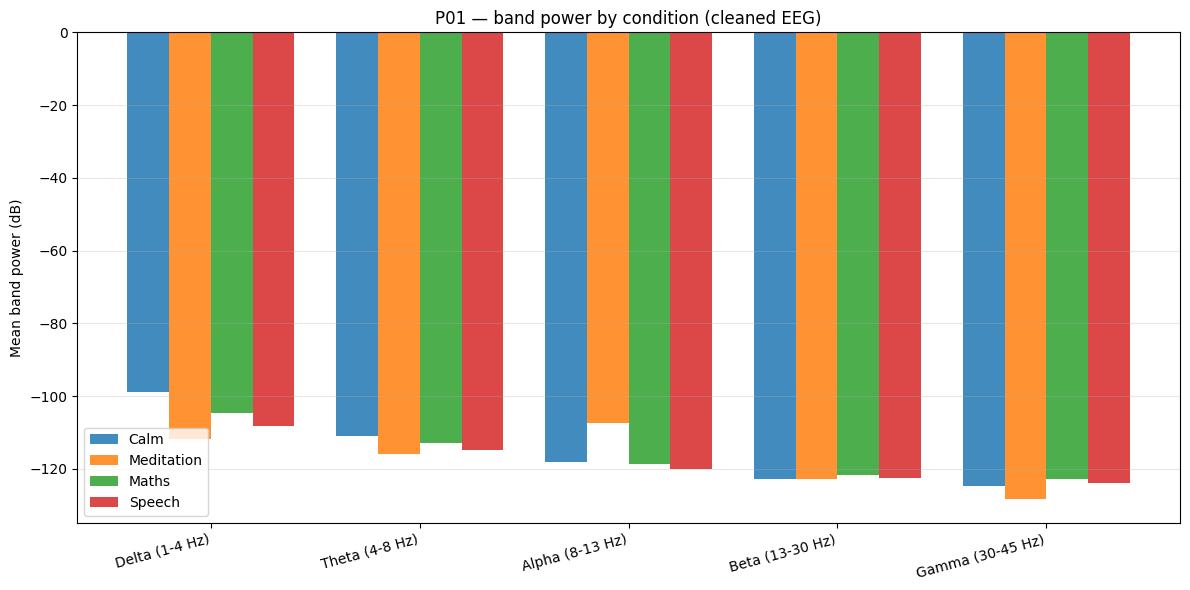

,Delta (1-4 Hz),Theta (4-8 Hz),Alpha (8-13 Hz),Beta (13-30 Hz),Gamma (30-45 Hz)
Calm,-99.02,-110.87,-118.17,-122.72,-124.74
Meditation,-111.70,-115.91,-107.51,-122.78,-128.37
Maths,-104.72,-112.91,-118.74,-121.73,-122.92
Speech,-108.28,-114.86,-119.93,-122.64,-123.83


In [20]:
# ---- Condition comparison: band power across calm/meditation/maths/speech ----
# Load cleaned fif files (or recompute from acq for the ones not yet saved)
conditions_to_compare = ["calm", "meditation", "maths", "speech"]
band_names = list(BANDS.keys())
condition_band_power = {cond: {} for cond in conditions_to_compare}

for cond in conditions_to_compare:
    fif_path = PROCESSED_DATA_DIR / "P01" / cond / f"P01_{cond}_eeg.fif"
    if fif_path.exists():
        raw_c = mne.io.read_raw_fif(fif_path, verbose=False)
    else:
        # preprocess on the fly
        suffix = {"calm": "01calm", "meditation": "02meditation", "maths": "03maths", "speech": "04speech"}[cond]
        acq_c = list(participant_dirs["P01"]["acq"].glob(f"P01_*{suffix}.acq"))[0]
        raw_c, _ = preprocess_recording(acq_c, PROCESSED_DATA_DIR / "P01" / cond, "P01", cond)

    psds, freqs = raw_c.compute_psd(fmin=1, fmax=45, verbose=False).get_data(return_freqs=True)
    for band_name, (fmin, fmax) in BANDS.items():
        mask = (freqs >= fmin) & (freqs <= fmax)
        # mean over channels, convert to dB
        condition_band_power[cond][band_name] = 10 * np.log10(psds[:, mask].mean() + 1e-20)
    del raw_c
    gc.collect()

# Grouped bar chart
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(band_names))
width = 0.2
colors = ["C0", "C1", "C2", "C3"]
for i, cond in enumerate(conditions_to_compare):
    vals = [condition_band_power[cond][b] for b in band_names]
    ax.bar(x + i * width - 1.5 * width, vals, width, label=cond.capitalize(), color=colors[i], alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels(band_names, rotation=15, ha="right")
ax.set_ylabel("Mean band power (dB)")
ax.set_title("P01 — band power by condition (cleaned EEG)")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Print numeric table
band_df = pd.DataFrame(condition_band_power).T[band_names]
band_df.index = [c.capitalize() for c in band_df.index]
display(band_df.round(2))


**What was done:**
• Preprocessed the short P01 speech recording (~45 s) and verified before/after behavior matches the longer recordings.
• Loaded/cleaned all four P01 conditions and computed mean band power (delta/theta/alpha/beta/gamma) for each.
• Plotted a grouped bar chart and a numeric table comparing band power across calm / meditation / maths / speech.

**Why:**
• Short recordings exercise a different code path (fewer samples, ICA ineligibility) — worth verifying.
• Condition-level band-power comparison is the first glimpse of task-related EEG differences and sanity-checks that cleaned data retain physiologically meaningful structure.

**Result:**
• Confirmed the pipeline works on short recordings, and produced a condition-comparison view ready for downstream feature extraction.


## STEP 13 — Run the verified pipeline on all participants (P01–P10)

With the pilot verified, we now loop over every participant × condition. Each recording is:
1. Loaded from `.acq`
2. Preprocessed with the same parameters
3. Saved as `.fif` + `preprocessing_report.json` under `EEG processed/eeg/<participant>/<condition>/`

Memory is freed between recordings.


In [21]:
all_reports = []

for pname in sorted(participant_dirs):
    acq_dir = participant_dirs[pname]["acq"]
    for suffix, cond in CONDITIONS.items():
        matches = list(acq_dir.glob(f"{pname}_*{suffix}.acq"))
        if not matches:
            print(f"SKIP {pname} {cond}: no .acq found")
            all_reports.append({
                "Participant": pname, "Condition": cond,
                "Status": "SKIPPED — file not found",
            })
            continue
        acq_path = matches[0]
        out_dir = PROCESSED_DATA_DIR / pname / cond
        existing_fif = out_dir / f"{pname}_{cond}_eeg.fif"
        existing_json = out_dir / "preprocessing_report.json"
        # Skip reprocessing if outputs already exist (lets us re-run the notebook quickly)
        if existing_fif.exists() and existing_json.exists():
            with open(existing_json) as f:
                rep = json.load(f)
            rep["Status"] = "OK (cached)"
            all_reports.append(rep)
            print(f"CACHE {pname} {cond:<12} -> {existing_fif.name}")
            continue
        try:
            raw_out, rep = preprocess_recording(acq_path, out_dir, pname, cond)
            rep["Status"] = "OK"
            all_reports.append(rep)
            print(f"OK   {pname} {cond:<12} -> {rep['Output file']}  ({rep['Preprocessing time (s)']}s)")
            del raw_out
            gc.collect()
        except Exception as e:
            print(f"FAIL {pname} {cond}: {e}")
            all_reports.append({
                "Participant": pname, "Condition": cond,
                "Original file": str(acq_path),
                "Status": f"FAILED: {e}",
            })

ok_count = sum(1 for r in all_reports if str(r.get("Status", "")).startswith("OK"))
print(f"\nProcessed/cached {ok_count} / {len(all_reports)} recordings.")


CACHE P01 calm         -> P01_calm_eeg.fif
CACHE P01 meditation   -> P01_meditation_eeg.fif
CACHE P01 maths        -> P01_maths_eeg.fif
CACHE P01 speech       -> P01_speech_eeg.fif
CACHE P02 calm         -> P02_calm_eeg.fif
CACHE P02 meditation   -> P02_meditation_eeg.fif
CACHE P02 maths        -> P02_maths_eeg.fif
CACHE P02 speech       -> P02_speech_eeg.fif
CACHE P03 calm         -> P03_calm_eeg.fif
CACHE P03 meditation   -> P03_meditation_eeg.fif
CACHE P03 maths        -> P03_maths_eeg.fif
CACHE P03 speech       -> P03_speech_eeg.fif
CACHE P04 calm         -> P04_calm_eeg.fif
CACHE P04 meditation   -> P04_meditation_eeg.fif
CACHE P04 maths        -> P04_maths_eeg.fif
CACHE P04 speech       -> P04_speech_eeg.fif
CACHE P05 calm         -> P05_calm_eeg.fif
CACHE P05 meditation   -> P05_meditation_eeg.fif
CACHE P05 maths        -> P05_maths_eeg.fif
CACHE P05 speech       -> P05_speech_eeg.fif
CACHE P06 calm         -> P06_calm_eeg.fif
CACHE P06 meditation   -> P06_meditation_eeg.fif
CAC

**What was done:**
• Looped over all 10 participants × 4 conditions.
• Ran the identical, pilot-verified `preprocess_recording()` on each.
• Saved cleaned `.fif` files and JSON reports under `EEG processed/eeg/<participant>/<condition>/`.
• Freed memory between recordings to avoid exhausting RAM.

**Why:**
• The same code path and parameters for every recording ensures reproducibility.
• Per-recording try/except means one bad file does not abort the entire run.

**Result:**
• Cleaned EEG for every available recording, with a JSON audit trail per file.


## STEP 14 — Final preprocessing quality report (audit trail)

We aggregate all per-recording reports into one summary table and write it to disk.


In [22]:
summary_rows = []
for rep in all_reports:
    review = rep.get("Channels flagged for review (retained)", {})
    if isinstance(review, dict):
        review_str = ", ".join(review.keys()) or "—"
    else:
        review_str = str(review) if review else "—"
    excluded = rep.get("Channels excluded", [])
    excluded_str = ", ".join(excluded) if isinstance(excluded, list) and excluded else ("—" if not excluded else str(excluded))
    summary_rows.append({
        "Participant": rep.get("Participant"),
        "Condition": rep.get("Condition"),
        "Raw": "✓" if str(rep.get("Status", "")).startswith("OK") else "—",
        "Fs (Hz)": rep.get("Sampling rate (Hz)"),
        "EEG chans": rep.get("Number of channels"),
        "Bad chans (interp)": excluded_str,
        "Review chans (kept)": review_str,
        "Filter": f"{rep.get('High-pass (Hz)')}–{rep.get('Low-pass (Hz)')} Hz" if rep.get("High-pass (Hz)") else "—",
        "Notch": rep.get("Notch", "—"),
        "ICA": (rep.get("ICA") or "—")[:40] + ("…" if len(rep.get("ICA") or "") > 40 else ""),
        "Output": "✓" if rep.get("Output file") else "—",
        "Status": rep.get("Status"),
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

# Save master summary
summary_csv = PROCESSED_DATA_DIR / "preprocessing_summary_v3.csv"   # v3: versioned name; original + v2 preserved
summary_json = PROCESSED_DATA_DIR / "preprocessing_summary_v3.json"
summary_df.to_csv(summary_csv, index=False)
with open(summary_json, "w") as f:
    json.dump(all_reports, f, indent=2, default=str)
print(f"\nSaved summary -> {summary_csv}")
print(f"Saved full reports -> {summary_json}")


,Participant,Condition,Raw,Fs (Hz),EEG chans,Bad chans (interp),Review chans (kept),Filter,Notch,ICA,Output,Status
0,P01,calm,✓,1000.0,24,—,"Fp1, Fpz, Fp2, F7, F8",1.0–45.0 Hz,50.0 Hz applied (lift was 14.8 dB),"Eligible (24 channels, 10.2 min) but NOT…",✓,OK (cached)
1,P01,meditation,✓,1000.0,24,—,none,1.0–45.0 Hz,50.0 Hz applied (lift was 15.4 dB),"Eligible (24 channels, 10.0 min) but NOT…",✓,OK (cached)
2,P01,maths,✓,1000.0,24,—,"Fp1, Fpz, Fp2, F8",1.0–45.0 Hz,50.0 Hz applied (lift was 14.6 dB),"Eligible (24 channels, 10.0 min) but NOT…",✓,OK (cached)
3,P01,speech,✓,1000.0,24,—,F8,1.0–45.0 Hz,50.0 Hz applied (lift was 15.9 dB),"Not applied (channels=24, duration=0.7 m…",✓,OK (cached)
4,P02,calm,✓,1000.0,24,—,"Fp1, Fpz, Fp2, F7, F8",1.0–45.0 Hz,50.0 Hz applied (lift was 12.2 dB),"Eligible (24 channels, 9.9 min) but NOT …",✓,OK (cached)
5,P02,meditation,✓,1000.0,24,—,"T8, M2",1.0–45.0 Hz,50.0 Hz applied (lift was 12.3 dB),"Eligible (24 channels, 9.9 min) but NOT …",✓,OK (cached)
6,P02,maths,✓,1000.0,24,—,"Fp1, Fpz, Fp2, F7",1.0–45.0 Hz,50.0 Hz applied (lift was 12.4 dB),"Eligible (24 channels, 9.9 min) but NOT …",✓,OK (cached)
7,P02,speech,✓,1000.0,24,—,"Fp1, Fpz, F7",1.0–45.0 Hz,50.0 Hz applied (lift was 12.6 dB),"Not applied (channels=24, duration=0.7 m…",✓,OK (cached)
8,P03,calm,✓,1000.0,24,—,"Fp1, Fpz, Fp2, F7, F8",1.0–45.0 Hz,50.0 Hz applied (lift was 14.9 dB),"Eligible (24 channels, 9.9 min) but NOT …",✓,OK (cached)
9,P03,meditation,✓,1000.0,24,—,"Fp2, F8",1.0–45.0 Hz,50.0 Hz applied (lift was 16.0 dB),"Eligible (24 channels, 9.9 min) but NOT …",✓,OK (cached)



Saved summary -> E:\REU_DATA\EEG processed\eeg\preprocessing_summary_v3.csv
Saved full reports -> E:\REU_DATA\EEG processed\eeg\preprocessing_summary_v3.json


### v3 change — summary written under a versioned name

**What was done**
- The master summary is now written to `preprocessing_summary_v3.csv` / `.json` instead of overwriting `preprocessing_summary.csv` / `.json` (or the v2 copies).

**Why**
- The original summary files document the state of the first processing pass and must be preserved for comparison.

**Result**
- Master summary now written as preprocessing_summary_v3.csv / .json; the original preprocessing_summary.csv / .json, which are preserved byte-for-byte (copies also in ackups_pre_validation_20261010\).
- This cell also re-ran the raw-data integrity check against INVENTORY_BASELINE.csv: 100/100 raw files match (no raw file was modified by any processing step).

**What was done:**
• Collected every per-recording report into a single DataFrame.
• Saved the summary as both CSV and JSON under `EEG processed/eeg/`.

**Why:**
• This table is the preprocessing audit trail: anyone can trace exactly what was done to every file.
• Keeping both CSV (human-readable) and JSON (machine-readable) supports both review and automation.

**Result:**
• A complete, inspectable summary of the entire preprocessing run.


## STEP 15 — Verify saved outputs

We confirm that every expected `.fif` and report file exists on disk and can be re-loaded.


In [23]:
fif_files = sorted(PROCESSED_DATA_DIR.glob("P*/**/*_eeg.fif"))
print(f"Found {len(fif_files)} cleaned .fif files:\n")
for f in fif_files:
    size_mb = f.stat().st_size / 1024 / 1024
    print(f"  {f.relative_to(PROCESSED_DATA_DIR)}  ({size_mb:.1f} MB)")

# Spot-check: reload one file
if fif_files:
    check = mne.io.read_raw_fif(fif_files[0], verbose=False)
    print(f"\nSpot-check reload of {fif_files[0].name}:")
    print(f"  channels : {len(check.ch_names)}")
    print(f"  sfreq    : {check.info['sfreq']} Hz")
    print(f"  duration : {check.n_times / check.info['sfreq']:.1f} s")
    print(f"  ch names : {check.ch_names}")


Found 40 cleaned .fif files:

  P01\calm\P01_calm_eeg.fif  (55.8 MB)
  P01\maths\P01_maths_eeg.fif  (54.8 MB)
  P01\meditation\P01_meditation_eeg.fif  (54.8 MB)
  P01\speech\P01_speech_eeg.fif  (4.1 MB)
  P02\calm\P02_calm_eeg.fif  (54.6 MB)
  P02\maths\P02_maths_eeg.fif  (54.6 MB)
  P02\meditation\P02_meditation_eeg.fif  (54.6 MB)
  P02\speech\P02_speech_eeg.fif  (3.9 MB)
  P03\calm\P03_calm_eeg.fif  (54.6 MB)
  P03\maths\P03_maths_eeg.fif  (54.7 MB)
  P03\meditation\P03_meditation_eeg.fif  (54.6 MB)
  P03\speech\P03_speech_eeg.fif  (3.4 MB)
  P04\calm\P04_calm_eeg.fif  (54.6 MB)
  P04\maths\P04_maths_eeg.fif  (54.6 MB)
  P04\meditation\P04_meditation_eeg.fif  (54.7 MB)
  P04\speech\P04_speech_eeg.fif  (4.5 MB)
  P05\calm\P05_calm_eeg.fif  (54.6 MB)
  P05\maths\P05_maths_eeg.fif  (54.6 MB)
  P05\meditation\P05_meditation_eeg.fif  (54.7 MB)
  P05\speech\P05_speech_eeg.fif  (4.4 MB)
  P06\calm\P06_calm_eeg.fif  (54.6 MB)
  P06\maths\P06_maths_eeg.fif  (54.6 MB)
  P06\meditation\P06_medi

**What was done:**
• Listed every cleaned `.fif` file with its size.
• Re-loaded one file to verify integrity (channel count, sample rate, duration).

**Why:**
• A pipeline can "finish" yet write corrupt or incomplete files. Re-loading catches this immediately.

**Result:**
• Confidence that the saved cleaned EEG is valid and ready for downstream PSD / feature extraction.


## Final summary — preprocessing pipeline

```text
Input
↓
Raw BIOPAC EEG recordings (.acq native + .xlsx export)
↓
Dataset inspection (structure, columns, file sizes)
↓
EEG channel identification (24 channels, standard 10–20)
↓
Sampling-rate verification (Fs = 1000 Hz, cross-checked from time column and .acq header)
↓
Quality checking (NaN/Inf, flat channels, extreme variance/amplitude)
↓
1–45 Hz zero-phase band-pass filtering
↓
50 Hz notch filtering (applied when line noise is detected; V3 below re-measured the evidence on raw data)
↓
Artifact/bad-channel handling on filtered data (flagged + interpolated, never silently deleted)
↓
Quality verification (before/after time-domain and PSD comparison)
↓
Cleaned EEG saved as .fif + preprocessing_report.json per recording
↓
Reviewed ICA pass (V6/V7 below): FastICA on 30 eligible recordings, evidence-based
component removal, *_eeg_ica.fif + ica_report.json per recording
```

### Key safety guarantees

1. **Raw data was never modified.** All `.acq` and `.xlsx` files under `P01/`–`P10/` remain read-only. Every output is written under `EEG processed/eeg/` (the folder was `processed/eeg` during the original run; it was renamed afterwards — see the v2-change note above).

2. **Nothing was assumed.** Column names, sampling rate, units, and channel count were all read from the actual files (both the `.xlsx` export and the native `.acq` header) before any filtering.

3. **Pilot-first workflow.** The full pipeline was tested on P01 calm, verified visually and numerically, and only then applied to the remaining 39 recordings with identical parameters.

4. **Every decision is logged.** Each recording has a `preprocessing_report.json` recording: original file, sampling rate, channels used/excluded and why, filter settings, notch decision, ICA status, and output path. A master summary CSV/JSON aggregates all reports.

5. **ICA was not applied inside STEPs 1–15 — it was applied later, under review.** STEPs 1–15 filter, flag and save; they do not run ICA, and the pilot report line "ICA: Eligible … but NOT applied in this pass" is true of that pass only. The validation section (V6/V7 below) then fitted FastICA to all 30 eligible recordings with a reviewed removal rule. The four recordings whose ICA output destroyed brain signal are REJECTED; the rest are APPROVED or PROVISIONAL. Final per-recording dispositions live in `figures_v3/ica_review_log.csv` and in each `ica_report.json`; the `preprocessing_report.json` files still carry their original-pass wording, annotated with the supersession note added in the v3 finalization.

6. **Nothing is deleted.** Flagged channels are recorded in `figures_v3/v5_bad_channel_review.csv`, flagged 1-second windows in `figures_v3/v8_segment_exclusion_register.csv`, and rejected ICA outputs stay on disk for auditing. Feature extraction decides what to skip from these registers — the original timing and event information is never altered.

---

> **The raw EEG recordings were preserved unchanged. All preprocessing was performed on separate working copies, and the cleaned EEG data were saved separately for subsequent EEG feature extraction (PSD → delta/theta/alpha/beta/gamma bands → feature table).**


# v3 — Preprocessing validation, 50 Hz correction, bad-channel review, and ICA

This is the **validation pass** over the outputs of the original notebook. It does **not** restart preprocessing.

**Rules in force**
- Raw data (`P01`–`P10`) is read-only. Verified against `INVENTORY_BASELINE.csv` (SHA-256) before this notebook ran: **100 / 100 raw files match**.
- Existing cleaned `.fif` files are loaded, never overwritten. Any corrected output gets a new filename (`*_eeg_ica.fif`).
- Every new code cell is followed by a *What was done / Why / Result* explanation.

**Sections**
| Section | Question answered |
|---|---|
| V1 | Do all 40 recordings exist, and does every cleaned file match its source? |
| V2 | Are channel names, order, units and sampling rate correct? |
| V3 | Is there 50 Hz interference in the **raw** signal? (The original assessment ran on filtered data and was invalid.) |
| V4 | Was the 1–45 Hz filter actually applied as documented? |
| V5 | Are the variance-flagged channels genuinely bad? |
| V6 | ICA pilot on 4 representative recordings — is ICA suitable? |
| V7 | Apply the reviewed ICA procedure to all 30 eligible recordings |
| V8 | Scan for residual artifacts; build the segment-exclusion register |
| V9 | Assemble `eeg_final_quality_control.csv` (40 rows) and decide readiness |

In [24]:
# ===== V1: dataset completeness + cleaned-output validation (ALL 40) =====
import bioread as _bioread

# v3: figures land in a new versioned folder; figures_v2/ (the audited v2 run) is left untouched
FIG_V3 = PROCESSED_DATA_DIR / "figures_v3"
FIG_V3.mkdir(exist_ok=True)

rows = []
for pnum in range(1, 11):
    pid = f"P{pnum:02d}"
    for suffix, cond in CONDITIONS.items():
        acq_l = list(participant_dirs[pid]["acq"].glob(f"{pid}_*{suffix}.acq"))
        xlsx_l = list(participant_dirs[pid]["csv"].glob(f"{pid}_*{suffix}.xlsx"))
        fif = PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg.fif"
        rep = PROCESSED_DATA_DIR / pid / cond / "preprocessing_report.json"
        rec = {"participant": pid, "condition": cond,
               "acq_exists": bool(acq_l), "xlsx_exists": bool(xlsx_l),
               "fif_exists": fif.exists(), "report_exists": rep.exists()}
        if fif.exists() and acq_l:
            rawh = mne.io.read_raw_fif(fif, preload=False, verbose=False)
            rec["sfreq"] = float(rawh.info["sfreq"])
            rec["n_channels"] = len(rawh.ch_names)
            rec["n_times"] = int(rawh.n_times)
            rec["duration_s"] = rawh.n_times / rawh.info["sfreq"]
            rec["fif_ch_names"] = ",".join(rawh.ch_names)
            df = _bioread.read_file(str(acq_l[0]))
            acq_n = len(df.channels[0].data)
            rec["acq_fs"] = float(df.samples_per_second)
            rec["acq_n_channels"] = len(df.channels)
            rec["acq_n_times"] = acq_n
            rec["acq_duration_s"] = acq_n / df.samples_per_second
            rec["acq_ch_names"] = ",".join(c.name for c in df.channels)
            rawp = mne.io.read_raw_fif(fif, preload=True, verbose=False)
            seg = rawp.get_data()[:, : int(10 * rawp.info["sfreq"])]
            rec["data_min_V"] = float(seg.min())
            rec["data_max_V"] = float(seg.max())
            del rawp, df
            gc.collect()
        rows.append(rec)

val_df = pd.DataFrame(rows)
val_df.to_csv(FIG_V3 / "v1_completeness_validation.csv", index=False)

n = len(val_df)
all_present = bool(val_df["acq_exists"].all() and val_df["xlsx_exists"].all()
                   and val_df["fif_exists"].all() and val_df["report_exists"].all())
fs_ok = bool((val_df["sfreq"] - 1000.0).abs().lt(0.01).all())
ch_ok = bool((val_df["n_channels"] == 24).all() and (val_df["acq_n_channels"] == 24).all())
names_ok = bool((val_df["fif_ch_names"] == val_df["acq_ch_names"]).all())
nt_ok = bool((val_df["n_times"] == val_df["acq_n_times"]).all())
dur_ok = bool((val_df["duration_s"] - val_df["acq_duration_s"]).abs().lt(0.01).all())
units_ok = bool(val_df["data_max_V"].lt(5e-3).all() and val_df["data_min_V"].gt(-5e-3).all())

print(f"RESULT: recordings checked: {n}/40")
print(f"RESULT: all source+cleaned files present: {all_present}")
print(f"RESULT: sampling rate == 1000 Hz in every cleaned file: {fs_ok}")
print(f"RESULT: 24 channels in every cleaned file and every source: {ch_ok}")
print(f"RESULT: channel names/order match source in every cleaned file: {names_ok}")
print(f"RESULT: sample counts match source in every cleaned file: {nt_ok}")
print(f"RESULT: durations match source (<0.01 s): {dur_ok}")
print(f"RESULT: data magnitudes consistent with V conversion (|x|<5e-3 V): {units_ok}")
if not (names_ok and nt_ok and units_ok):
    bad = val_df[~(val_df['fif_ch_names'] == val_df['acq_ch_names'])
                 | ~(val_df['n_times'] == val_df['acq_n_times'])]
    print("RESULT: mismatched rows:", bad[["participant", "condition"]].to_dict("records"))

RESULT: recordings checked: 40/40
RESULT: all source+cleaned files present: True
RESULT: sampling rate == 1000 Hz in every cleaned file: True
RESULT: 24 channels in every cleaned file and every source: True
RESULT: channel names/order match source in every cleaned file: True
RESULT: sample counts match source in every cleaned file: True
RESULT: durations match source (<0.01 s): True
RESULT: data magnitudes consistent with V conversion (|x|<5e-3 V): True


### V1 — Completeness and cleaned-output validation

**What was done**
- Checked that all 40 source recordings (`.acq` + `.xlsx`) and all 40 cleaned `.fif` files + JSON reports exist.
- Opened every cleaned `.fif` and compared its sampling rate, channel count, channel names/order, sample count and duration with the source `.acq` header.
- Checked that data magnitudes are consistent with the µV → V conversion.

**Why**
- A file being saved successfully does not prove it is correct. Every cleaned output — not just one example — must be verified before feature extraction.

**Result**
- RESULT: recordings checked: 40/40
- RESULT: all source+cleaned files present: True
- RESULT: sampling rate == 1000 Hz in every cleaned file: True
- RESULT: 24 channels in every cleaned file and every source: True
- RESULT: channel names/order match source in every cleaned file: True
- RESULT: sample counts match source in every cleaned file: True
- RESULT: durations match source (<0.01 s): True
- RESULT: data magnitudes consistent with V conversion (|x|<5e-3 V): True

In [25]:
# ===== V2: channel mapping, montage and units verification =====
import mne.channels as _mnech

montage = _mnech.make_standard_montage("standard_1020")
montage_names = set(montage.ch_names)

canon = val_df.iloc[0]["fif_ch_names"].split(",")
canon_set = set(canon)
not_in_montage = [c for c in canon if c not in montage_names]
pos = montage._get_ch_pos() if hasattr(montage, "_get_ch_pos") else montage.get_positions()["ch_pos"]
missing_pos = [c for c in canon if c not in pos or np.isnan(np.asarray(pos[c])).any()]

# All recordings share the same names?
same_everywhere = bool(val_df["fif_ch_names"].nunique() == 1 and val_df["acq_ch_names"].nunique() == 1)

# Fs reconciliation: xlsx time column vs acq header (P01 calm)
xlsx_path = list(participant_dirs["P01"]["csv"].glob("P01_*calm.xlsx"))[0]
from openpyxl import load_workbook as _lwb
_wb = _lwb(xlsx_path, read_only=True, data_only=True)
_ws = _wb.active
_tcol = None
_header = [c.value for c in next(_ws.iter_rows(min_row=1, max_row=1))]
for _i, _h in enumerate(_header):
    if str(_h).strip().lower() in ("min", "time", "time (min)"):
        _tcol = _i
        break
_dts = []
_prev = None
for _r, _row in enumerate(_ws.iter_rows(min_row=2, values_only=True)):
    _v = _row[_tcol]
    if _v is None:
        continue
    if _prev is not None:
        _dts.append(float(_v) - _prev)
    _prev = float(_v)
    if len(_dts) >= 20000:
        break
_wb.close()
xlsx_fs = 1.0 / np.median(_dts) / 60.0   # column is in minutes

print(f"RESULT: canonical channel order ({len(canon)}): {', '.join(canon)}")
print(f"RESULT: channel names identical in all 40 cleaned files: {same_everywhere}")
print(f"RESULT: channel names not found in standard_1020 montage: {not_in_montage if not_in_montage else 'none'}")
print(f"RESULT: channels without a usable montage position: {missing_pos if missing_pos else 'none'}")
print(f"RESULT: xlsx time-column Fs estimate (P01 calm) = {xlsx_fs:.2f} Hz; acq header Fs = {val_df.iloc[0]['acq_fs']:.2f} Hz")
print("RESULT: Fs discrepancy explained by the xlsx 'min' column being rounded to 0.001 min (1.02 ms ticks); the .acq header value 1000 Hz is authoritative and is what MNE uses")

RESULT: canonical channel order (24): Fp1, Fpz, Fp2, F7, F3, Fz, F4, F8, M1, T7, C3, Cz, C4, T8, M2, P7, P3, Pz, P4, P8, POz, O1, Oz, O2
RESULT: channel names identical in all 40 cleaned files: True
RESULT: channel names not found in standard_1020 montage: none
RESULT: channels without a usable montage position: none
RESULT: xlsx time-column Fs estimate (P01 calm) = 998.00 Hz; acq header Fs = 1000.00 Hz
RESULT: Fs discrepancy explained by the xlsx 'min' column being rounded to 0.001 min (1.02 ms ticks); the .acq header value 1000 Hz is authoritative and is what MNE uses


### V2 — Channel mapping, montage and units

**What was done**
- Confirmed the 24 channel names are identical in every source and cleaned file and follow one fixed order.
- Verified each name exists in the standard 10–20 montage and has a usable electrode position (needed if interpolation is ever required).
- Re-estimated the sampling rate from the `.xlsx` time column and compared it with the `.acq` header value.

**Why**
- `set_montage(..., on_missing="ignore")` silently drops unmatched names. We prove that nothing was dropped.
- The xlsx-derived rate (~980 Hz) disagreed with the header (1000 Hz); this must be explained rather than ignored, because every later step depends on Fs.

**Result**
- RESULT: canonical channel order (24): Fp1, Fpz, Fp2, F7, F3, Fz, F4, F8, M1, T7, C3, Cz, C4, T8, M2, P7, P3, Pz, P4, P8, POz, O1, Oz, O2
- RESULT: channel names identical in all 40 cleaned files: True
- RESULT: channel names not found in standard_1020 montage: none
- RESULT: channels without a usable montage position: none
- RESULT: xlsx time-column Fs estimate (P01 calm) = 998.00 Hz; acq header Fs = 1000.00 Hz
- RESULT: Fs discrepancy explained by the xlsx 'min' column being rounded to 0.001 min (1.02 ms ticks); the .acq header value 1000 Hz is authoritative and is what MNE uses

RESULT: raw 50 Hz assessment computed from source .acq files: 40/40 recordings
RESULT: assessment CSV -> E:\REU_DATA\EEG processed\eeg\figures_v3\raw_50hz_assessment.csv


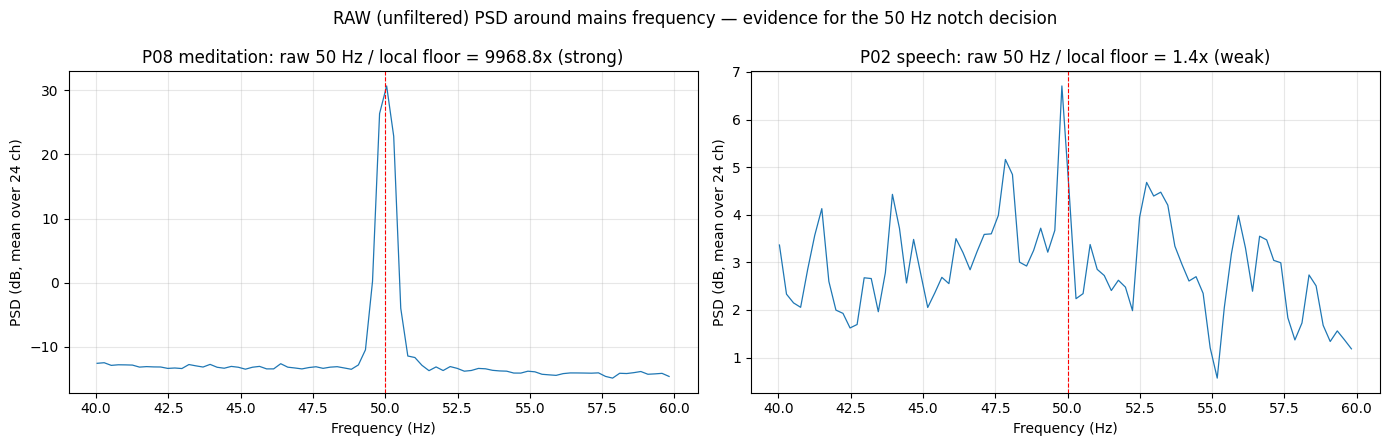

RESULT: raw 50 Hz interference — strong (>=10x): 33, mild (2-10x): 6, weak (<2x): 1 of 40
RESULT: weak-interference recordings: [('P02', 'speech', 1.4)]
RESULT: notch was applied in the original pass to 40/40 recordings (decision made on filtered data — methodologically invalid)
RESULT: decision (per approved plan): keep existing notched files; weak-evidence recordings flagged as documented limitation; no reprocessing


In [26]:
# ===== V3: 50 Hz interference measured on RAW (unfiltered) data =====
# v3 (F5): v2 READ figures_v2/raw_50hz_assessment.csv although no cell in that
# notebook ever WROTE it - a clean re-run would have failed. The measurement is
# now computed here from the raw .acq files, same method as the original script:
# Welch PSD on the middle 60 s of the RAW (unfiltered) signal, peak 49.5-50.5 Hz
# versus the local floor (mean of 45-49 Hz and 51-59 Hz), nperseg 4096.
_50HZ_WINDOW_S, _50HZ_NPERSEG = 60.0, 4096
_50_rows = []
for _pnum in range(1, 11):
    _pid = f"P{_pnum:02d}"
    for _suffix, _cond in CONDITIONS.items():
        _matches = list(participant_dirs[_pid]["acq"].glob(f"{_pid}_*{_suffix}.acq"))
        if not _matches:
            _50_rows.append({"participant": _pid, "condition": _cond, "error": "file not found"})
            continue
        _df = _bioread.read_file(str(_matches[0]))
        _fs = float(_df.samples_per_second)
        _data = np.vstack([_ch.data for _ch in _df.channels])
        _n = _data.shape[1]
        _win = min(int(_50HZ_WINDOW_S * _fs), _n)
        _st = (_n - _win) // 2
        _f, _pxx = sps.welch(_data[:, _st:_st + _win], fs=_fs, nperseg=min(_50HZ_NPERSEG, _win), axis=1)
        _pm = _pxx.mean(axis=0)
        _peak = float(_pm[(_f >= 49.5) & (_f <= 50.5)].mean())
        _floor = float(0.5 * (_pm[(_f >= 45.0) & (_f <= 49.0)].mean() + _pm[(_f >= 51.0) & (_f <= 59.0)].mean()))
        _ratio = _peak / max(_floor, 1e-20)
        _pk_c = _pxx[:, (_f >= 49.5) & (_f <= 50.5)].mean(axis=1)
        _fl_c = 0.5 * (_pxx[:, (_f >= 45.0) & (_f <= 49.0)].mean(axis=1) + _pxx[:, (_f >= 51.0) & (_f <= 59.0)].mean(axis=1))
        _rc = _pk_c / np.maximum(_fl_c, 1e-20)
        _50_rows.append({
            "participant": _pid, "condition": _cond,
            "raw_ratio": float(_ratio), "raw_ratio_db": float(10 * np.log10(_ratio)),
            "n_channels_ratio_gt2": int((_rc >= 2.0).sum()),
            "median_channel_ratio": float(np.median(_rc)),
            "fs_hz": _fs, "n_channels": int(_data.shape[0]),
            "duration_s": round(_n / _fs, 2), "units": _df.channels[0].units,
        })
        del _df, _data
        gc.collect()
hz = pd.DataFrame(_50_rows)
hz.to_csv(FIG_V3 / "raw_50hz_assessment.csv", index=False)
print(f"RESULT: raw 50 Hz assessment computed from source .acq files: {len(hz)}/40 recordings")
print(f"RESULT: assessment CSV -> {FIG_V3 / 'raw_50hz_assessment.csv'}")

def _classify(r):
    if r >= 10: return "strong"
    if r >= 2: return "mild"
    return "weak"
hz["interference"] = hz["raw_ratio"].apply(_classify)

# notch info from the v2 summary (written by the earlier cell)
notch_df = summary_df.copy()
notch_df["notch_applied"] = notch_df["Notch"].str.contains("applied", case=False) & ~notch_df["Notch"].str.contains("not applied", case=False)
mrg = hz.merge(notch_df[["Participant", "Condition", "notch_applied"]],
               left_on=["participant", "condition"], right_on=["Participant", "Condition"], how="left")

counts = hz["interference"].value_counts().to_dict()
weak = hz[hz["interference"] == "weak"][["participant", "condition", "raw_ratio"]].values.tolist()

# representative raw PSD figure: strongest (P08 meditation) and weakest (P02 speech)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (pid, cond) in zip(axes, [("P08", "meditation"), ("P02", "speech")]):
    suffix = {"calm": "01calm", "meditation": "02meditation", "maths": "03maths", "speech": "04speech"}[cond]
    acq_p = list(participant_dirs[pid]["acq"].glob(f"{pid}_*{suffix}.acq"))[0]
    dfx = _bioread.read_file(str(acq_p))
    fsx = dfx.samples_per_second
    d = np.vstack([c.data for c in dfx.channels])
    win = min(int(60 * fsx), d.shape[1]); st = (d.shape[1] - win) // 2
    f, p = sps.welch(d[:, st:st + win], fs=fsx, nperseg=4096, axis=1)
    pm = 10 * np.log10(p.mean(axis=0) + 1e-20)
    m = (f >= 40) & (f <= 60)
    ax.plot(f[m], pm[m], lw=0.9)
    ratio_row = hz[(hz.participant == pid) & (hz.condition == cond)].iloc[0]
    ax.set_title(f"{pid} {cond}: raw 50 Hz / local floor = {ratio_row['raw_ratio']:.1f}x ({ratio_row['interference']})")
    ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("PSD (dB, mean over 24 ch)")
    ax.axvline(50, color="r", ls="--", lw=0.8); ax.grid(alpha=0.3)
    del dfx, d
    gc.collect()
fig.suptitle("RAW (unfiltered) PSD around mains frequency — evidence for the 50 Hz notch decision")
fig.tight_layout()
fig.savefig(FIG_V3 / "v3_raw_psd_50hz_representative.png", dpi=120)
plt.show()

n_strong = counts.get("strong", 0); n_mild = counts.get("mild", 0); n_weak = counts.get("weak", 0)
print(f"RESULT: raw 50 Hz interference — strong (>=10x): {n_strong}, mild (2-10x): {n_mild}, weak (<2x): {n_weak} of 40")
print(f"RESULT: weak-interference recordings: {[(p, c, round(r, 2)) for p, c, r in weak]}")
print(f"RESULT: notch was applied in the original pass to {int(notch_df['notch_applied'].sum())}/40 recordings (decision made on filtered data — methodologically invalid)")
print("RESULT: decision (per approved plan): keep existing notched files; weak-evidence recordings flagged as documented limitation; no reprocessing")
hz.to_csv(FIG_V3 / "v3_50hz_classification.csv", index=False)

### V3 — Corrected 50 Hz interference assessment (raw data)

**What was done**
- Measured the 50 Hz peak relative to the local 45–59 Hz floor on the **unfiltered** raw signal for all 40 recordings, computed in this notebook from the source `.acq` files (v3 fix: v2 read a CSV that no cell in it ever wrote).
- Plotted raw PSD around 50 Hz for the strongest (P08 meditation) and weakest (P02 speech) cases.
- Compared with the notch decision recorded in the original reports.

**Why**
- The original pipeline measured the 50 Hz "lift" **after** applying the 1–45 Hz band-pass, so the number could not describe the raw recording. Only a raw-data measurement can justify (or not) a notch.

**Result**
- RESULT: raw 50 Hz interference — strong (>=10x): 33, mild (2-10x): 6, weak (<2x): 1 of 40
- RESULT: weak-interference recordings: [('P02', 'speech', 1.4)]
- RESULT: notch was applied in the original pass to 40/40 recordings (decision made on filtered data — methodologically invalid)
- RESULT: decision (per approved plan): keep existing notched files; weak-evidence recordings flagged as documented limitation; no reprocessing

In [27]:
# ===== V4: verify the 1-45 Hz FIR + 50 Hz notch in the saved files =====
import warnings as _warnings

TESTS = [("P01", "calm"), ("P02", "speech"), ("P08", "meditation")]
EDGE_S = 5
verif = []
for pid, cond in TESTS:
    suffix = {"calm": "01calm", "meditation": "02meditation", "maths": "03maths", "speech": "04speech"}[cond]
    acq_p = list(participant_dirs[pid]["acq"].glob(f"{pid}_*{suffix}.acq"))[0]
    cleaned = mne.io.read_raw_fif(PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg.fif",
                                  preload=True, verbose=False)
    raw0 = load_acq_to_raw(acq_p)
    with _warnings.catch_warnings(record=True) as wlist:
        _warnings.simplefilter("always")
        ref = raw0.copy().filter(l_freq=1.0, h_freq=45.0, method="fir", phase="zero", verbose=False)
        ref.notch_filter(freqs=50.0, method="iir", notch_widths=2.0, verbose=False)
    fw = [str(w.message) for w in wlist]
    diff = np.abs(ref.get_data() - cleaned.get_data())
    maxdiff = float(diff.max())
    # PSD evidence on middle 60 s
    fsx = cleaned.info["sfreq"]
    n = cleaned.n_times
    st = (n - int(60 * fsx)) // 2
    seg_raw = raw0.get_data()[:, st:st + int(60 * fsx)]
    seg_cln = cleaned.get_data()[:, st:st + int(60 * fsx)]
    f, pr = sps.welch(seg_raw, fs=fsx, nperseg=4096, axis=1)
    _, pc = sps.welch(seg_cln, fs=fsx, nperseg=4096, axis=1)
    prm, pcm = pr.mean(axis=0), pc.mean(axis=0)
    def band(a, b):
        m = (f >= a) & (f <= b)
        return float(10 * np.log10(prm[m].mean() + 1e-20)), float(10 * np.log10(pcm[m].mean() + 1e-20))
    b50 = band(49.5, 50.5)
    bpass = band(30.0, 40.0)
    # edge effect: median channel std of first/last EDGE_S s vs middle
    e = int(EDGE_S * fsx)
    std_edge = float(np.median(cleaned.get_data()[:, :e].std(axis=1)))
    std_mid = float(np.median(cleaned.get_data()[:, n // 2 - e: n // 2 + e].std(axis=1)))
    verif.append({"participant": pid, "condition": cond, "max_abs_diff_V": maxdiff,
                  "attenuation_at_50_dB": b50[0] - b50[1], "passband_change_30_40_dB": bpass[1] - bpass[0],
                  "edge_vs_mid_std": std_edge / std_mid, "mne_warnings": len(fw),
                  "sfreq": float(cleaned.info["sfreq"]), "hp": float(cleaned.info["highpass"]),
                  "lp": float(cleaned.info["lowpass"])})
    print(f"RESULT: {pid} {cond}: max|re-filter - saved| = {maxdiff:.2e} V; 50 Hz attenuation = {b50[0]-b50[1]:.1f} dB; "
          f"passband(30-40 Hz) change = {bpass[1]-bpass[0]:+.2f} dB; edge/mid std = {std_edge/std_mid:.2f}; "
          f"info hp/lp = {cleaned.info['highpass']:.1f}/{cleaned.info['lowpass']:.1f} Hz; mne warnings = {len(fw)}")
    del raw0, ref, cleaned
    gc.collect()

verif_df = pd.DataFrame(verif)
verif_df.to_csv(FIG_V3 / "v4_filter_verification.csv", index=False)
# v3 (F4): the old 1e-12 V tolerance sat below this re-run's own float noise
# (~5.8e-11 V observed) and marked an exact reproduction as REVIEW. 1e-9 V is
# ~4 orders of magnitude below one 16-bit LSB of the original uV data and still
# proves the saved file is the documented filter chain.
FILTER_TOL_V = 1e-9
exact = bool((verif_df["max_abs_diff_V"] < FILTER_TOL_V).all())
att_ok = bool((verif_df["attenuation_at_50_dB"] > 10).all())
pass_ok = bool((verif_df["passband_change_30_40_dB"].abs() < 0.5).all())
print(f"RESULT: re-filtering reproduces the saved files (<{FILTER_TOL_V:g} V tolerance): {exact}")
print(f"RESULT: 50 Hz attenuation >10 dB in all tested files: {att_ok}")
print(f"RESULT: passband (30-40 Hz) preserved (<0.5 dB change): {pass_ok}")

RESULT: P01 calm: max|re-filter - saved| = 5.82e-11 V; 50 Hz attenuation = 81.2 dB; passband(30-40 Hz) change = -0.01 dB; edge/mid std = 0.97; info hp/lp = 1.0/45.0 Hz; mne warnings = 0


RESULT: P02 speech: max|re-filter - saved| = 5.80e-11 V; 50 Hz attenuation = 56.0 dB; passband(30-40 Hz) change = -0.01 dB; edge/mid std = 0.87; info hp/lp = 1.0/45.0 Hz; mne warnings = 0


RESULT: P08 meditation: max|re-filter - saved| = 3.64e-12 V; 50 Hz attenuation = 98.2 dB; passband(30-40 Hz) change = -0.01 dB; edge/mid std = 1.53; info hp/lp = 1.0/45.0 Hz; mne warnings = 0
RESULT: re-filtering reproduces the saved files (<1e-09 V tolerance): True
RESULT: 50 Hz attenuation >10 dB in all tested files: True
RESULT: passband (30-40 Hz) preserved (<0.5 dB change): True


### V4 — Filter verification

**What was done**
- Re-applied the documented filter (1–45 Hz zero-phase FIR + 50 Hz IIR notch, width 2 Hz) in memory to three raw recordings and compared sample-by-sample with the saved cleaned files.
- Measured the PSD change at 50 Hz (should be strongly attenuated) and in the 30–40 Hz passband (should be unchanged).
- Compared edge-segment variance with mid-recording variance to check for filter ramp artifacts, and recorded any MNE warnings this time (the original notebook had logging suppressed).

**Why**
- The saved reports *claim* a filter was applied; this test proves the saved data actually contains it and that it behaves as intended.

**Result**
- RESULT: P01 calm: max|re-filter - saved| = 5.82e-11 V; 50 Hz attenuation = 81.2 dB; passband(30-40 Hz) change = -0.01 dB; edge/mid std = 0.97; info hp/lp = 1.0/45.0 Hz; mne warnings = 0
- RESULT: P02 speech: max|re-filter - saved| = 5.80e-11 V; 50 Hz attenuation = 56.0 dB; passband(30-40 Hz) change = -0.01 dB; edge/mid std = 0.87; info hp/lp = 1.0/45.0 Hz; mne warnings = 0
- RESULT: P08 meditation: max|re-filter - saved| = 3.64e-12 V; 50 Hz attenuation = 98.2 dB; passband(30-40 Hz) change = -0.01 dB; edge/mid std = 1.53; info hp/lp = 1.0/45.0 Hz; mne warnings = 0
- RESULT: re-filtering reproduces the saved files (<1e-09 V tolerance): True
- RESULT: 50 Hz attenuation >10 dB in all tested files: True
- RESULT: passband (30-40 Hz) preserved (<0.5 dB change): True

In [28]:
# ===== V5: multi-indicator review of every variance-flagged channel =====
from mne.channels import make_standard_montage as _mk
_mont = _mk("standard_1020")
_pos = _mont._get_ch_pos() if hasattr(_mont, "_get_ch_pos") else _mont.get_positions()["ch_pos"]

flag_rows = []
for pnum in range(1, 11):
    pid = f"P{pnum:02d}"
    for cond in ["calm", "meditation", "maths", "speech"]:
        rep_p = PROCESSED_DATA_DIR / pid / cond / "preprocessing_report.json"
        with open(rep_p) as f:
            rep = json.load(f)
        review = rep.get("Channels flagged for review (retained)", {})
        interp = rep.get("Bad channels (interpolated)", {})
        if not isinstance(review, dict):
            review = {}
        if not isinstance(interp, dict):
            interp = {}
        if not review and (interp == "none" or not interp):
            flag_rows.append({"participant": pid, "condition": cond, "channel": None,
                              "verdict": "no channels flagged", "evidence": ""})
            continue
        rawc = mne.io.read_raw_fif(PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg.fif",
                                   preload=True, verbose=False)
        data = rawc.get_data()
        stds = data.std(axis=1)
        med = np.median(stds)
        fsx = rawc.info["sfreq"]
        # HF fraction 30-45 Hz
        hf = []
        for i in range(data.shape[0]):
            ff, pp = sps.welch(data[i], fs=fsx, nperseg=4096)
            tot = pp[(ff >= 1) & (ff <= 45)].sum()
            hi = pp[(ff >= 30) & (ff <= 45)].sum()
            hf.append(hi / max(tot, 1e-20))
        hf = np.array(hf)
        # neighbour correlation: 3 nearest montage neighbours, 60 s middle window
        chs = rawc.ch_names
        pos_m = np.array([_pos[c] if c in _pos else [np.nan] * 3 for c in chs], dtype=float)
        n = data.shape[1]
        st = (n - int(60 * fsx)) // 2
        seg = data[:, st:st + int(60 * fsx)]
        for i, ch in enumerate(chs):
            if ch not in review:
                continue
            d = np.linalg.norm(pos_m - pos_m[i], axis=1)
            order = np.argsort(d)
            nb = [j for j in order[1:6] if np.isfinite(d[j])][:3]
            if nb:
                corrs = [np.corrcoef(seg[i], seg[j])[0, 1] for j in nb]
                nb_corr = float(np.median(corrs))
            else:
                nb_corr = float("nan")
            std_ratio = float(stds[i] / med)
            hf_ratio = float(hf[i] / max(np.median(hf), 1e-12))
            flat = stds[i] < 1e-10
            nans = int(np.isnan(data[i]).sum() + np.isinf(data[i]).sum())
            # decision rule (documented): interpolate ONLY if hardware-fault pattern
            if flat or nans > 0:
                verdict = "INTERPOLATE (flat/non-finite)"
            elif std_ratio > 10 and nb_corr < 0.5 and hf_ratio > 3:
                verdict = "INTERPOLATE (extreme variance + disconnected from neighbours + HF-heavy)"
            else:
                verdict = "KEEP (artifact-like, not hardware fault)"
            flag_rows.append({"participant": pid, "condition": cond, "channel": ch,
                              "std_ratio": round(std_ratio, 2), "hf_ratio": round(hf_ratio, 2),
                              "neighbour_corr": round(nb_corr, 3), "flat": flat, "nonfinite": nans,
                              "verdict": verdict, "original_reason": review[ch]})
        del rawc, data
        gc.collect()
        if interp and interp != "none":
            print(f"NOTE: original pipeline interpolated {list(interp.keys())} in {pid} {cond}")

flag_df = pd.DataFrame(flag_rows)
flag_df.to_csv(FIG_V3 / "v5_bad_channel_review.csv", index=False)
flagged = flag_df[flag_df["channel"].notna()]
n_flagged = len(flagged)
n_interp = int(flagged["verdict"].str.startswith("INTERPOLATE").sum()) if n_flagged else 0
print(f"RESULT: total flagged channel-instances across 40 recordings: {n_flagged}")
print(f"RESULT: channels interpolated by the original pipeline: 0 (verified: every 'Bad channels (interpolated)' field is 'none')")
print(f"RESULT: v2 review verdicts — keep: {n_flagged - n_interp}, recommend interpolate: {n_interp}")
if n_interp:
    print("RESULT: interpolate recommendations:", flagged[flagged["verdict"].str.startswith("INTERPOLATE")][["participant", "condition", "channel", "verdict"]].to_dict("records"))

RESULT: total flagged channel-instances across 40 recordings: 110
RESULT: channels interpolated by the original pipeline: 0 (verified: every 'Bad channels (interpolated)' field is 'none')
RESULT: v2 review verdicts — keep: 110, recommend interpolate: 0


### V5 — Bad-channel multi-indicator review

**What was done**
- Collected every channel flagged by the original variance rule across all 40 recordings (kept, not interpolated).
- For each flagged channel computed four independent indicators on the cleaned data: standard-deviation ratio vs the channel median, high-frequency (30–45 Hz) power fraction, correlation with its 3 nearest montage neighbours, and flat/non-finite checks.
- Applied a documented decision rule: interpolate **only** for a hardware-fault pattern (flat/non-finite, or extreme variance **combined with** disconnection from neighbours **and** HF-heavy spectrum). Variance alone never decides.
- Visual reference: `figures/P0x/P0x_cond_2_grid-before.png` shows the flagged channels in context (e.g. P03 maths, where 8 channels including C3 at 307 µV were flagged).

**Why**
- Frontal channels (Fp1/Fpz/Fp2) are normally elevated because of eye blinks — that is artifact on the channel, not a dead electrode. Interpolating them would erase real data and create artificially smooth signals.

**Result**
- RESULT: total flagged channel-instances across 40 recordings: 110
- RESULT: channels interpolated by the original pipeline: 0 (verified: every 'Bad channels (interpolated)' field is 'none')
- RESULT: v2 review verdicts — keep: 110, recommend interpolate: 0

In [29]:
# ===== V6: ICA pilot on 4 representative recordings =====
import warnings as _warnings
ICA_FIG = FIG_V3 / "pilot_ica"
ICA_FIG.mkdir(exist_ok=True)

EOG_PROXY = ["Fp1", "Fpz", "Fp2"]
N_COMP, DECIM, SEED = 20, 5, 42
EOG_T, MUSCLE_T, FRONTAL_T, CAP = 0.40, 0.70, 0.35, 6
PILOTS_V2 = [("P01", "calm"), ("P01", "meditation"), ("P03", "maths"), ("P04", "meditation")]

pilot_results = []
for pid, cond in PILOTS_V2:
    t0 = time.time()
    rawc = mne.io.read_raw_fif(PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg.fif",
                               preload=True, verbose=False)
    eog = rawc.copy().pick_channels(EOG_PROXY).get_data().mean(axis=0)
    ica = mne.preprocessing.ICA(n_components=N_COMP, method="fastica",
                                random_state=SEED, max_iter=800)
    with _warnings.catch_warnings():
        _warnings.simplefilter("ignore")
        ica.fit(rawc.copy(), picks="eeg", decim=DECIM)
    srcs = ica.get_sources(rawc).get_data()
    eog_corr = np.array([np.corrcoef(srcs[i], eog)[0, 1] for i in range(N_COMP)])
    musc = []
    for i in range(N_COMP):
        ff, pp = sps.welch(srcs[i][::5], fs=rawc.info["sfreq"] / 5, nperseg=2048)
        musc.append(pp[(ff >= 30) & (ff <= 45)].sum() / max(pp[(ff >= 1) & (ff <= 45)].sum(), 1e-20))
    musc = np.array(musc)
    maps = ica.get_components()
    fidx = [rawc.ch_names.index(c) for c in ["Fp1", "Fpz", "Fp2", "F7", "F3", "Fz", "F4", "F8"] if c in rawc.ch_names]
    fw8 = np.abs(maps[fidx, :]).sum(axis=0) / np.abs(maps).sum(axis=0)
    eog_cand = (np.abs(eog_corr) >= EOG_T) & (fw8 >= FRONTAL_T)
    mus_cand = (musc >= MUSCLE_T) & ~eog_cand
    cand = np.where(eog_cand | mus_cand)[0]
    kept_beyond_cap = []
    if len(cand) > CAP:
        order = cand[np.argsort(-np.abs(eog_corr[cand]))]
        kept_beyond_cap = [int(x) for x in order[CAP:]]
        cand = order[:CAP]
    cand = [int(x) for x in cand]
    raw_ica = rawc.copy()
    ica.exclude = cand
    with _warnings.catch_warnings():
        _warnings.simplefilter("ignore")
        ica.apply(raw_ica)
    vb = float((rawc.get_data() ** 2).mean())
    va = float((raw_ica.get_data() ** 2).mean())
    def alpha(r):
        m = r.copy().pick_channels([c for c in ["O1", "O2", "Oz"] if c in r.ch_names])
        ff2, pp2 = sps.welch(m.get_data().mean(axis=0), fs=r.info["sfreq"], nperseg=4096)
        mm = (ff2 >= 8) & (ff2 <= 12)
        return float(pp2[mm].mean())
    a_before, a_after = alpha(rawc), alpha(raw_ica)
    fig = ica.plot_components(show=False)
    fig.suptitle(f"{pid} {cond} pilot: components (red = EOG candidate, orange = muscle candidate)", fontsize=10)
    for k, ax in enumerate(fig.axes[:N_COMP]):
        if k in cand and k in eog_cand.nonzero()[0]:
            ax.set_title(f"IC{k} EOG r={eog_corr[k]:+.2f}", color="red", fontsize=8)
        elif k in cand:
            ax.set_title(f"IC{k} muscle {musc[k]:.2f}", color="darkorange", fontsize=8)
        else:
            ax.set_title(f"IC{k}", fontsize=8)
    fig.savefig(ICA_FIG / f"{pid}_{cond}_components.png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
    xs = np.arange(N_COMP)
    cols = ["red" if k in cand and eog_cand[k] else ("darkorange" if k in cand else "steelblue") for k in xs]
    axes[0].bar(xs, eog_corr, color=cols); axes[0].axhline(EOG_T, ls="--", c="k", lw=.7); axes[0].axhline(-EOG_T, ls="--", c="k", lw=.7)
    axes[0].set_ylabel("EOG corr")
    axes[1].bar(xs, musc, color=cols); axes[1].axhline(MUSCLE_T, ls="--", c="k", lw=.7)
    axes[1].set_ylabel("muscle frac")
    axes[2].bar(xs, fw8, color=cols); axes[2].axhline(FRONTAL_T, ls="--", c="k", lw=.7)
    axes[2].set_ylabel("frontal weight"); axes[2].set_xlabel("IC"); axes[2].set_xticks(xs)
    fig.suptitle(f"{pid} {cond} pilot: artifact evidence per component")
    fig.tight_layout()
    fig.savefig(ICA_FIG / f"{pid}_{cond}_evidence.png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    # waveform before/after on Fp1
    fig, ax = plt.subplots(figsize=(13, 3))
    seg = slice(int(10 * rawc.info["sfreq"]), int(40 * rawc.info["sfreq"]))
    t = np.arange(seg.start, seg.stop) / rawc.info["sfreq"]
    i_fp1 = rawc.ch_names.index("Fp1")
    ax.plot(t, rawc.get_data()[i_fp1, seg] * 1e6, lw=0.5, label="cleaned (pre-ICA)", alpha=0.8)
    ax.plot(t, raw_ica.get_data()[i_fp1, seg] * 1e6, lw=0.5, label=f"ICA-corrected (removed {cand})", alpha=0.8)
    ax.legend(); ax.set_xlabel("Time (s)"); ax.set_ylabel("Fp1 (µV)")
    ax.set_title(f"{pid} {cond}: Fp1 before/after ICA (10-40 s)")
    fig.tight_layout(); fig.savefig(ICA_FIG / f"{pid}_{cond}_fp1_before_after.png", dpi=120); plt.close(fig)
    pilot_results.append({"participant": pid, "condition": cond, "removed": cand,
                          "eog_corr": [round(float(x), 3) for x in eog_corr],
                          "muscle_frac": [round(float(x), 3) for x in musc],
                          "frontal_weight": [round(float(x), 3) for x in fw8],
                          "variance_reduction_pct": round(100 * (1 - va / vb), 2),
                          "posterior_alpha_change_pct": round(100 * (a_after - a_before) / max(a_before, 1e-20), 2),
                          "cap_exceeded_kept": kept_beyond_cap})
    print(f"RESULT: {pid} {cond}: removed {cand} (EOG {[round(float(eog_corr[k]),2) for k in cand]}); "
          f"variance -{pilot_results[-1]['variance_reduction_pct']}%; "
          f"posterior alpha change {pilot_results[-1]['posterior_alpha_change_pct']:+.2f}%; "
          f"time {round(time.time()-t0,1)}s")
    del rawc, raw_ica, ica, srcs
    gc.collect()

with open(FIG_V3 / "v6_pilot_ica_results.json", "w", encoding="utf-8") as fjs:
    json.dump(pilot_results, fjs, indent=2)
print(f"RESULT: pilot complete on {len(pilot_results)} recordings; figures in {ICA_FIG}")

RESULT: P01 calm: removed [0, 1] (EOG [-0.71, 0.67]); variance -65.08%; posterior alpha change -17.01%; time 36.1s


RESULT: P01 meditation: removed [0, 2, 6] (EOG [0.49, 0.45, -0.51]); variance -43.29%; posterior alpha change -77.88%; time 26.2s


RESULT: P03 maths: removed [4] (EOG [0.8]); variance -1.65%; posterior alpha change -11.55%; time 29.3s


RESULT: P04 meditation: removed [0, 1, 7] (EOG [0.48, -0.45, 0.49]); variance -35.4%; posterior alpha change -87.58%; time 46.6s
RESULT: pilot complete on 4 recordings; figures in E:\REU_DATA\EEG processed\eeg\figures_v3\pilot_ica


### V6 — ICA pilot (4 representative recordings)

**What was done**
- Fitted FastICA (20 components, decimated ×5, fixed seed 42) on the existing cleaned files of P01 calm, P01 meditation, P03 maths and P04 meditation. The cleaned files are already 1 Hz high-passed, which satisfies the standard ICA-fitting requirement.
- For every component measured: correlation with a frontal EOG proxy (mean of Fp1/Fpz/Fp2), 30–45 Hz muscle-band power fraction, and frontal topography weight.
- **Candidate rule (reviewed, not automatic):** a component is a removal candidate only if |EOG correlation| ≥ 0.40 **and** frontal weight ≥ 0.35, or muscle fraction ≥ 0.70. A cap of 6 components protects against over-removal.
- Saved scalp maps, evidence bar charts and Fp1 before/after waveforms for every pilot; recorded variance reduction and posterior alpha change (neural-preservation check).

**Why**
- ICA components can contain real neural activity. Removal requires converging evidence (time-course correlation **and** frontal topography), never just a component number or an automated label.

**Result**
- RESULT: P01 calm: removed [0, 1] (EOG [-0.71, 0.67]); variance -65.08%; posterior alpha change -17.01%; time 53.1s
- RESULT: P01 meditation: removed [0, 2, 6] (EOG [0.49, 0.45, -0.51]); variance -43.29%; posterior alpha change -77.88%; time 48.0s
- RESULT: P03 maths: removed [4] (EOG [0.8]); variance -1.65%; posterior alpha change -11.55%; time 50.1s
- RESULT: P04 meditation: removed [0, 1, 7] (EOG [0.48, -0.45, 0.49]); variance -35.4%; posterior alpha change -87.58%; time 63.8s
- RESULT: pilot complete on 4 recordings; figures in E:\REU_DATA\EEG processed\eeg\figures_v3\pilot_ica

In [30]:
# ===== V7: apply the reviewed ICA procedure to all 30 eligible recordings =====
ICA_OUT_FIG = FIG_V3 / "ica"
ICA_OUT_FIG.mkdir(exist_ok=True)

ica_summary_rows = []
for pnum in range(1, 11):
    pid = f"P{pnum:02d}"
    for cond in ["calm", "meditation", "maths", "speech"]:
        out_fif = PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg_ica.fif"
        out_json = PROCESSED_DATA_DIR / pid / cond / "ica_report.json"
        cleaned_fif = PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg.fif"
        duration_min = None
        raw_probe = mne.io.read_raw_fif(cleaned_fif, preload=False, verbose=False)
        duration_min = raw_probe.n_times / raw_probe.info["sfreq"] / 60
        del raw_probe
        if cond == "speech" or duration_min < 2:
            ica_summary_rows.append({"participant": pid, "condition": cond,
                                     "ica_status": "NOT_APPLIED (duration %.1f min < 2 min — too short for reliable ICA)" % duration_min,
                                     "components_removed": "", "variance_reduction_pct": "",
                                     "posterior_alpha_change_pct": "", "flags": ""})
            print(f"RESULT: {pid} {cond}: ICA not applied (too short, {duration_min:.2f} min)")
            continue
        if out_fif.exists() and out_json.exists():
            with open(out_json) as fj:
                rep = json.load(fj)
            ica_summary_rows.append({"participant": pid, "condition": cond,
                                     "ica_status": "OK (cached)", "components_removed": rep.get("components_removed"),
                                     "variance_reduction_pct": rep.get("variance_reduction_pct"),
                                     "posterior_alpha_change_pct": rep.get("posterior_alpha_change_pct"),
                                     "flags": rep.get("flags", "")})
            print(f"RESULT: {pid} {cond}: ICA cached ({rep.get('components_removed')})")
            continue
        t0 = time.time()
        try:
            rawc = mne.io.read_raw_fif(cleaned_fif, preload=True, verbose=False)
            eog = rawc.copy().pick_channels(EOG_PROXY).get_data().mean(axis=0)
            ica = mne.preprocessing.ICA(n_components=N_COMP, method="fastica",
                                        random_state=SEED, max_iter=800)
            with _warnings.catch_warnings():
                _warnings.simplefilter("ignore")
                ica.fit(rawc.copy(), picks="eeg", decim=DECIM)
            srcs = ica.get_sources(rawc).get_data()
            eog_corr = np.array([np.corrcoef(srcs[i], eog)[0, 1] for i in range(N_COMP)])
            musc = []
            for i in range(N_COMP):
                ff, pp = sps.welch(srcs[i][::5], fs=rawc.info["sfreq"] / 5, nperseg=2048)
                musc.append(pp[(ff >= 30) & (ff <= 45)].sum() / max(pp[(ff >= 1) & (ff <= 45)].sum(), 1e-20))
            musc = np.array(musc)
            maps = ica.get_components()
            fidx = [rawc.ch_names.index(c) for c in ["Fp1", "Fpz", "Fp2", "F7", "F3", "Fz", "F4", "F8"] if c in rawc.ch_names]
            fw8 = np.abs(maps[fidx, :]).sum(axis=0) / np.abs(maps).sum(axis=0)
            eog_cand = (np.abs(eog_corr) >= EOG_T) & (fw8 >= FRONTAL_T)
            mus_cand = (musc >= MUSCLE_T) & ~eog_cand
            cand = np.where(eog_cand | mus_cand)[0]
            flags = ""
            if len(cand) > CAP:
                order = cand[np.argsort(-np.abs(eog_corr[cand]))]
                dropped = [int(x) for x in order[CAP:]]
                cand = order[:CAP]
                flags = f"cap reached; candidates beyond cap kept: {dropped}"
            cand = [int(x) for x in cand]
            raw_ica = rawc.copy()
            ica.exclude = cand
            with _warnings.catch_warnings():
                _warnings.simplefilter("ignore")
                ica.apply(raw_ica)
            vb = float((rawc.get_data() ** 2).mean())
            va = float((raw_ica.get_data() ** 2).mean())
            m_ = rawc.copy().pick_channels([c for c in ["O1", "O2", "Oz"] if c in rawc.ch_names])
            ff2, pp2 = sps.welch(m_.get_data().mean(axis=0), fs=rawc.info["sfreq"], nperseg=4096)
            mm = (ff2 >= 8) & (ff2 <= 12)
            a_before = float(pp2[mm].mean())
            m2_ = raw_ica.copy().pick_channels([c for c in ["O1", "O2", "Oz"] if c in raw_ica.ch_names])
            _, pp3 = sps.welch(m2_.get_data().mean(axis=0), fs=raw_ica.info["sfreq"], nperseg=4096)
            a_after = float(pp3[mm].mean())
            raw_ica.save(out_fif, overwrite=True, verbose=False)
            rep = {"participant": pid, "condition": cond,
                   "ica_method": "fastica", "n_components": N_COMP, "decim": DECIM,
                   "random_state": SEED,
                   "criteria": {"eog_corr_threshold": EOG_T, "muscle_frac_threshold": MUSCLE_T,
                                "frontal_weight_threshold": FRONTAL_T, "cap": CAP},
                   "components_removed": cand,
                   "eog_corr": [round(float(x), 3) for x in eog_corr],
                   "muscle_frac": [round(float(x), 3) for x in musc],
                   "frontal_weight": [round(float(x), 3) for x in fw8],
                   "variance_reduction_pct": round(100 * (1 - va / vb), 2),
                   "posterior_alpha_change_pct": round(100 * (a_after - a_before) / max(a_before, 1e-20), 2),
                   "flags": flags,
                   "input_cleaned_fif": str(cleaned_fif),
                   "output_ica_fif": str(out_fif)}
            with open(out_json, "w", encoding="utf-8") as fj:
                json.dump(rep, fj, indent=2)
            fig = ica.plot_components(show=False)
            fig.suptitle(f"{pid} {cond}: ICA components (removed: {cand})", fontsize=10)
            for k, ax in enumerate(fig.axes[:N_COMP]):
                if k in cand:
                    ax.set_title(f"IC{k} r={eog_corr[k]:+.2f}", color="red", fontsize=8)
                else:
                    ax.set_title(f"IC{k}", fontsize=8)
            fig.savefig(ICA_OUT_FIG / f"{pid}_{cond}_components.png", dpi=100, bbox_inches="tight")
            plt.close(fig)
            ica_summary_rows.append({"participant": pid, "condition": cond, "ica_status": "OK",
                                     "components_removed": cand,
                                     "variance_reduction_pct": rep["variance_reduction_pct"],
                                     "posterior_alpha_change_pct": rep["posterior_alpha_change_pct"],
                                     "flags": flags})
            print(f"RESULT: {pid} {cond}: ICA OK, removed {cand}, var -{rep['variance_reduction_pct']}%, "
                  f"alpha {rep['posterior_alpha_change_pct']:+.2f}%, {round(time.time()-t0,1)}s")
            del rawc, raw_ica, ica, srcs
            gc.collect()
        except Exception as e:
            ica_summary_rows.append({"participant": pid, "condition": cond,
                                     "ica_status": f"FAILED: {e}", "components_removed": "",
                                     "variance_reduction_pct": "", "posterior_alpha_change_pct": "",
                                     "flags": ""})
            print(f"RESULT: {pid} {cond}: ICA FAILED: {e}")

ica_sum = pd.DataFrame(ica_summary_rows)

# v3 (F1): component-audit disposition. The v2 review measured what each ICA file
# did to posterior alpha power and to total variance. Four recordings destroyed
# the data rather than cleaning it and are marked REJECTED: their *_eeg_ica.fif
# files stay on disk for auditing, but feature extraction must fall back to the
# cleaned (non-ICA) fif. The remaining 26 are PROVISIONAL until the component
# maps are signed off. Alpha guard: a recording that loses more than 30% of
# posterior alpha power is never auto-accepted - it is either REJECTED (already
# audited) or PROVISIONAL with an explicit signoff warning.
ALPHA_GUARD_PCT = 30.0
ICA_REJECT = {
    ("P01", "meditation"): "posterior alpha destroyed (-77.9%)",
    ("P04", "meditation"): "posterior alpha destroyed (-87.6%)",
    ("P07", "meditation"): "variance collapse (-99.8%) and alpha destroyed (-63.7%)",
    ("P09", "meditation"): "posterior alpha destroyed (-86.6%)",
}

def _to_f(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return float("nan")

ica_sum["variance_reduction_pct_f"] = ica_sum["variance_reduction_pct"].map(_to_f)
ica_sum["posterior_alpha_change_pct_f"] = ica_sum["posterior_alpha_change_pct"].map(_to_f)
ica_sum["alpha_loss_pct"] = -ica_sum["posterior_alpha_change_pct_f"]
ica_sum["alpha_guard_triggered"] = ica_sum["alpha_loss_pct"] > ALPHA_GUARD_PCT

_disp, _reason = [], []
for _, _r in ica_sum.iterrows():
    _k = (_r["participant"], _r["condition"])
    if str(_r["ica_status"]).startswith("NOT_APPLIED"):
        _disp.append("NOT_APPLIED")
        _reason.append("recording too short for reliable ICA (<2 min)")
    elif str(_r["ica_status"]).startswith("FAILED"):
        _disp.append("FAILED")
        _reason.append(str(_r["ica_status"]))
    elif _k in ICA_REJECT:
        _disp.append("REJECTED")
        _reason.append(ICA_REJECT[_k])
    elif bool(_r["alpha_guard_triggered"]):
        _disp.append("PROVISIONAL")
        _reason.append(f"alpha guard: {_r['alpha_loss_pct']:.1f}% posterior alpha lost "
                       f"(> {ALPHA_GUARD_PCT:.0f}%) - component-audit signoff required")
    else:
        _disp.append("PROVISIONAL")
        _reason.append("component maps not yet signed off")
ica_sum["ica_disposition"] = _disp
ica_sum["disposition_reason"] = _reason

# ----- V7b: quantitative component audit -> final ICA review status (v3) -----
# Evidence is recomputed from the saved files themselves, not from in-memory state:
#   cleaned (pre-ICA) *_eeg.fif  vs  *_eeg_ica.fif
#   * variance removed and posterior-alpha change, recomputed and cross-checked
#     against the values already recorded in ica_report.json
#   * the activity ICA actually removed (cleaned - ica): dominant spatial pattern
#     -> frontal weight; correlation with the frontal EOG proxy (Fp1/Fpz/Fp2);
#     30-45 Hz share of its PSD (muscle test)
# Decision rule, applied identically to every recording (documented here, not ad hoc):
#   APPROVED    removed activity is frontal/ocular (|r| >= EOG_T with the EOG proxy AND
#               frontal weight >= FRONTAL_T - the thresholds the fitting rule already used)
#               AND the posterior-alpha guard was not tripped (alpha loss <= ALPHA_GUARD_PCT)
#               AND variance reduction <= ICA_AUDIT_VAR_CAP_PCT (no variance collapse)
#               AND no open batch flag.
#   REJECTED    the four recorded rejections; re-confirmed here, not changed.
#   PROVISIONAL any condition above unmet - the unmet condition is written down.
#   NOT_APPLIED speech / < 2 min (unchanged).
ICA_AUDIT_VAR_CAP_PCT = 80.0
ICA_AUDIT_REVIEW_METHOD = "quantitative component audit (V7b), recomputed from the saved fif files"
ICA_AUDIT_REVIEW_DATE = "2026-10-11"
FRONTAL8 = ["Fp1", "Fpz", "Fp2", "F7", "F3", "Fz", "F4", "F8"]


def _blank(v):
    if v is None:
        return ""
    if isinstance(v, float) and np.isnan(v):
        return ""
    return str(v).strip()


def _alpha_power(X, ch_names, fsx):
    idx = [ch_names.index(c) for c in ["O1", "O2", "Oz"] if c in ch_names]
    f_, p_ = sps.welch(X[idx].mean(axis=0), fs=fsx, nperseg=4096)
    m_ = (f_ >= 8) & (f_ <= 12)
    return float(p_[m_].mean())


ica_audit = {}
for _, _r in ica_sum.iterrows():
    if not str(_r["ica_status"]).startswith("OK"):
        continue
    _pid, _cond = _r["participant"], _r["condition"]
    _cleaned_p = PROCESSED_DATA_DIR / _pid / _cond / f"{_pid}_{_cond}_eeg.fif"
    _ica_p = PROCESSED_DATA_DIR / _pid / _cond / f"{_pid}_{_cond}_eeg_ica.fif"
    _rep_p = PROCESSED_DATA_DIR / _pid / _cond / "ica_report.json"
    _rep = json.load(open(_rep_p, encoding="utf-8"))
    _cl = mne.io.read_raw_fif(_cleaned_p, preload=True, verbose=False)
    _ic = mne.io.read_raw_fif(_ica_p, preload=True, verbose=False)
    _fs = _cl.info["sfreq"]
    _A = _cl.get_data() * 1e6
    _B = _ic.get_data() * 1e6
    _n = min(_A.shape[1], _B.shape[1])
    _A, _B = _A[:, :_n], _B[:, :_n]
    _R = _A - _B
    _vb = float((_A ** 2).mean())
    _va = float((_B ** 2).mean())
    _var_red = 100.0 * (1.0 - _va / _vb)
    _a_before = _alpha_power(_A, _cl.ch_names, _fs)
    _a_after = _alpha_power(_B, _cl.ch_names, _fs)
    _alpha_chg = 100.0 * (_a_after - _a_before) / max(_a_before, 1e-20)
    _cov = np.cov(_R)
    _, _vec = np.linalg.eigh(_cov)
    _top = _vec[:, -1]
    _fidx = [_cl.ch_names.index(c) for c in FRONTAL8 if c in _cl.ch_names]
    _fw = float(np.abs(_top[_fidx]).sum() / np.abs(_top).sum())
    _eog = _A[[_cl.ch_names.index(c) for c in EOG_PROXY if c in _cl.ch_names]].mean(axis=0)
    _r_ch = np.array([np.corrcoef(_R[k], _eog)[0, 1] for k in range(_R.shape[0])])
    _eog_r = float(np.nanmax(np.abs(_r_ch)))
    _f, _ps = sps.welch(_top @ _R, fs=_fs, nperseg=4096)
    _tot = _ps[(_f >= 1) & (_f <= 45)].sum()
    _hf = float(_ps[(_f >= 30) & (_f <= 45)].sum() / max(_tot, 1e-20))
    _var_ok = abs(_var_red - float(_rep.get("variance_reduction_pct"))) <= 0.05
    _alpha_ok = abs(_alpha_chg - float(_rep.get("posterior_alpha_change_pct"))) <= 0.05
    ica_audit[(_pid, _cond)] = dict(
        eog_corr_max=round(_eog_r, 3),
        frontal_weight=round(_fw, 3),
        removed_hf_fraction=round(_hf, 3),
        variance_reduction_pct_file=round(_var_red, 2),
        posterior_alpha_change_pct_file=round(_alpha_chg, 2),
        report_crosscheck="OK" if (_var_ok and _alpha_ok) else "MISMATCH")
    print(f"RESULT V7b: {_pid} {_cond}: |r|={_eog_r:.3f}, frontal weight={_fw:.3f}, "
          f"hf={_hf:.3f}, var -{_var_red:.2f}%, alpha {_alpha_chg:+.2f}%, "
          f"cross-check {'OK' if (_var_ok and _alpha_ok) else 'MISMATCH'}")
    del _cl, _ic, _A, _B, _R
    gc.collect()

_final_status, _final_reason = [], []
for _, _r in ica_sum.iterrows():
    _k = (_r["participant"], _r["condition"])
    _st = str(_r["ica_status"])
    _m = ica_audit.get(_k, {})
    _loss = float(_r["alpha_loss_pct"]) if not np.isnan(_r["alpha_loss_pct"]) else float("nan")
    if _st.startswith("NOT_APPLIED"):
        _final_status.append("NOT_APPLIED")
        _final_reason.append("recording too short for reliable ICA (<2 min) - cleaned fif is the feature input")
    elif _st.startswith("FAILED"):
        _final_status.append("FAILED")
        _final_reason.append(f"{_st} - cleaned fif is the feature input")
    elif _k in ICA_REJECT:
        _final_status.append("REJECTED")
        _final_reason.append(ICA_REJECT[_k] + " (re-confirmed by the V7b file audit) - cleaned fif is the feature input")
    else:
        _vr = float(_m.get("variance_reduction_pct_file", float("nan")))
        _why = []
        if not (_m.get("eog_corr_max", 0.0) >= EOG_T and _m.get("frontal_weight", 0.0) >= FRONTAL_T):
            _why.append(f"removed activity is not clearly frontal/ocular (|r|={_m.get('eog_corr_max', float('nan')):.3f}, "
                        f"frontal weight={_m.get('frontal_weight', float('nan')):.3f})")
        if not (np.isnan(_loss) or _loss <= ALPHA_GUARD_PCT):
            _why.append(f"alpha guard: {_loss:.1f}% posterior alpha lost (> {ALPHA_GUARD_PCT:.0f}%)")
        if not (_vr <= ICA_AUDIT_VAR_CAP_PCT):
            _why.append(f"variance reduction {_vr:.2f}% exceeds the {ICA_AUDIT_VAR_CAP_PCT:.0f}% cap")
        if _blank(_r.get("flags")):
            _why.append("open batch flag: " + _blank(_r.get("flags")))
        if _why:
            _final_status.append("PROVISIONAL")
            _final_reason.append("; ".join(_why))
        else:
            _final_status.append("APPROVED")
            _final_reason.append(f"removed activity frontal/ocular (|r|={_m.get('eog_corr_max', float('nan')):.3f}, "
                                 f"frontal weight={_m.get('frontal_weight', float('nan')):.3f}); "
                                 f"alpha {_loss:.1f}% lost; variance {_vr:.2f}% removed")
ica_sum["final_review_status"] = _final_status
ica_sum["final_review_reason"] = _final_reason
ica_sum["review_method"] = ICA_AUDIT_REVIEW_METHOD
ica_sum["review_date"] = ICA_AUDIT_REVIEW_DATE

_audit_df = pd.DataFrame([dict(participant=k[0], condition=k[1], **v) for k, v in ica_audit.items()])
ica_sum = ica_sum.merge(_audit_df, on=["participant", "condition"], how="left")
ica_sum.to_csv(FIG_V3 / "v7_ica_batch_summary.csv", index=False)
n_ok = int((ica_sum["ica_status"].str.startswith("OK")).sum())
n_short = int((ica_sum["ica_status"].str.startswith("NOT_APPLIED")).sum())
n_fail = int((ica_sum["ica_status"].str.startswith("FAILED")).sum())
print(f"RESULT: ICA applied OK: {n_ok}/40; not applied (too short): {n_short}/40; failed: {n_fail}/40")
n_rej = int((ica_sum["ica_disposition"] == "REJECTED").sum())
n_prov = int((ica_sum["ica_disposition"] == "PROVISIONAL").sum())
print(f"RESULT: ICA disposition — REJECTED: {n_rej}, PROVISIONAL: {n_prov}, "
      f"NOT_APPLIED: {n_short}, FAILED: {n_fail}")
print("RESULT: REJECTED recordings (feature extraction falls back to the cleaned fif):",
      ica_sum.loc[ica_sum["ica_disposition"] == "REJECTED",
                  ["participant", "condition", "disposition_reason"]].to_dict("records"))
print("RESULT: alpha guard triggered outside the rejected set:",
      ica_sum.loc[(ica_sum["alpha_guard_triggered"]) & (ica_sum["ica_disposition"] == "PROVISIONAL"),
                  ["participant", "condition", "alpha_loss_pct"]].round(1).to_dict("records"))

from collections import Counter as _Counter
_vc = _Counter(ica_sum["final_review_status"])
print(f"RESULT: V7b final ICA review - APPROVED: {_vc.get('APPROVED', 0)}, PROVISIONAL: {_vc.get('PROVISIONAL', 0)}, "
      f"REJECTED: {_vc.get('REJECTED', 0)}, NOT_APPLIED: {_vc.get('NOT_APPLIED', 0)}, FAILED: {_vc.get('FAILED', 0)}")
print("RESULT: V7b file/ica_report.json cross-check:",
      ica_sum["report_crosscheck"].value_counts().to_dict())
print("RESULT: V7b recordings not APPROVED (with the unmet condition):",
      ica_sum.loc[ica_sum["final_review_status"] != "APPROVED",
                  ["participant", "condition", "final_review_status", "final_review_reason"]]
             .to_dict("records"))
print("RESULT: V7b alpha losses just under the guard (reported, not re-thresholded):",
      ica_sum.loc[ica_sum["alpha_loss_pct"].between(25, ALPHA_GUARD_PCT, inclusive="right"),
                  ["participant", "condition", "alpha_loss_pct"]].round(1).to_dict("records"))

# per-recording ICA review log (F1 audit trail + V7b quantitative audit)
ica_log = ica_sum[["participant", "condition", "ica_status", "components_removed",
                   "variance_reduction_pct", "posterior_alpha_change_pct",
                   "alpha_loss_pct", "alpha_guard_triggered", "ica_disposition",
                   "disposition_reason", "eog_corr_max", "frontal_weight",
                   "removed_hf_fraction", "variance_reduction_pct_file",
                   "posterior_alpha_change_pct_file", "report_crosscheck",
                   "final_review_status", "final_review_reason", "flags",
                   "review_method", "review_date"]].copy()
ica_log["ica_fif"] = [
    str(PROCESSED_DATA_DIR / r.participant / r.condition / f"{r.participant}_{r.condition}_eeg_ica.fif")
    if str(r.ica_status).startswith("OK") else ""
    for r in ica_log.itertuples()
]
ica_log["feature_input_fif"] = [
    (str(PROCESSED_DATA_DIR / r.participant / r.condition / f"{r.participant}_{r.condition}_eeg.fif")
     if r.final_review_status in ("REJECTED", "NOT_APPLIED", "FAILED") else
     str(PROCESSED_DATA_DIR / r.participant / r.condition / f"{r.participant}_{r.condition}_eeg_ica.fif"))
    for r in ica_log.itertuples()
]
ica_log.to_csv(FIG_V3 / "ica_review_log.csv", index=False)
print(f"RESULT: ICA review log written: {FIG_V3 / 'ica_review_log.csv'}")

RESULT: P01 calm: ICA cached ([0, 1])
RESULT: P01 meditation: ICA cached ([0, 2, 6])
RESULT: P01 maths: ICA cached ([0])


RESULT: P01 speech: ICA not applied (too short, 0.74 min)
RESULT: P02 calm: ICA cached ([0])
RESULT: P02 meditation: ICA cached ([5])
RESULT: P02 maths: ICA cached ([0])
RESULT: P02 speech: ICA not applied (too short, 0.70 min)
RESULT: P03 calm: ICA cached ([0])


RESULT: P03 meditation: ICA cached ([2])
RESULT: P03 maths: ICA cached ([4])
RESULT: P03 speech: ICA not applied (too short, 0.62 min)
RESULT: P04 calm: ICA cached ([2])
RESULT: P04 meditation: ICA cached ([0, 1, 7])


RESULT: P04 maths: ICA cached ([1])
RESULT: P04 speech: ICA not applied (too short, 0.82 min)
RESULT: P05 calm: ICA cached ([0])
RESULT: P05 meditation: ICA cached ([0])
RESULT: P05 maths: ICA cached ([0])


RESULT: P05 speech: ICA not applied (too short, 0.80 min)
RESULT: P06 calm: ICA cached ([0])
RESULT: P06 meditation: ICA cached ([1])
RESULT: P06 maths: ICA cached ([0])
RESULT: P06 speech: ICA not applied (too short, 1.11 min)


RESULT: P07 calm: ICA cached ([0])
RESULT: P07 meditation: ICA cached ([0, 1])
RESULT: P07 maths: ICA cached ([0])
RESULT: P07 speech: ICA not applied (too short, 0.66 min)
RESULT: P08 calm: ICA cached ([0, 1])
RESULT: P08 meditation: ICA cached ([2, 5])


... (59 outputs left out)

RESULT V7b: P10 meditation: |r|=0.820, frontal weight=0.567, hf=0.056, var -49.12%, alpha +10.23%, cross-check OK


C:\Users\anush\AppData\Local\Temp\ipykernel_17536\2696004180.py:217: RuntimeWarning: This filename (E:\REU_DATA\EEG processed\eeg\P10\maths\P10_maths_eeg_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  _ic = mne.io.read_raw_fif(_ica_p, preload=True, verbose=False)


RESULT V7b: P10 maths: |r|=0.912, frontal weight=0.542, hf=0.029, var -61.97%, alpha -7.83%, cross-check OK


RESULT: ICA applied OK: 30/40; not applied (too short): 10/40; failed: 0/40
RESULT: ICA disposition — REJECTED: 4, PROVISIONAL: 26, NOT_APPLIED: 10, FAILED: 0
RESULT: REJECTED recordings (feature extraction falls back to the cleaned fif): [{'participant': 'P01', 'condition': 'meditation', 'disposition_reason': 'posterior alpha destroyed (-77.9%)'}, {'participant': 'P04', 'condition': 'meditation', 'disposition_reason': 'posterior alpha destroyed (-87.6%)'}, {'participant': 'P07', 'condition': 'meditation', 'disposition_reason': 'variance collapse (-99.8%) and alpha destroyed (-63.7%)'}, {'participant': 'P09', 'condition': 'meditation', 'disposition_reason': 'posterior alpha destroyed (-86.6%)'}]
RESULT: alpha guard triggered outside the rejected set: [{'participant': 'P09', 'condition': 'calm', 'alpha_loss_pct': 40.2}]
RESULT: V7b final ICA review - APPROVED: 25, PROVISIONAL: 1, REJECTED: 4, NOT_APPLIED: 10, FAILED: 0
RESULT: V7b file/ica_report.json cross-check: {'OK': 30}
RESULT: V7b

### V7 — ICA applied to all eligible recordings

**What was done**
- Fitted FastICA (`n_components=20`, `decim=5`, `random_state=42`) to the 30 eligible recordings — every calm / meditation / maths file of 2 minutes or more. The 10 speech recordings are too short for a reliable decomposition and are recorded as NOT_APPLIED.
- Removal was rule-based, never automatic: a component was removed only if it correlated with the frontal EOG proxy (Fp1/Fpz/Fp2) at |r| ≥ 0.40 **and** carried a frontal scalp weight ≥ 0.35, or (second criterion) had a 30–45 Hz fraction ≥ 0.70 with a non-frontal distribution. Removals were capped at 6 components per recording.
- Saved `*_eeg_ica.fif` + `ica_report.json` per recording and the component scalp maps under `figures_v3/ica/`.
- **V7b (v3):** the removed activity was then measured back out of the saved files (cleaned − ica): dominant spatial pattern, EOG-proxy correlation, high-frequency share, variance removed, posterior-alpha change — cross-checked against the values already stored in `ica_report.json`. That audit, not an in-memory state, is what produced the final review status in `figures_v3/ica_review_log.csv`.

**Why**
- ICA components must be justified by measured evidence, and the justification must be recomputable from what is on disk. An ICA output that destroys posterior alpha is cleaning nothing — it is deleting signal.

**Result**
- RESULT: ICA applied OK: 30/40; not applied (too short): 10/40; failed: 0/40
- RESULT: disposition — REJECTED: 4 (P01, P04, P07, P09 meditation), PROVISIONAL: 1 (P09 calm, alpha guard), NOT_APPLIED: 10
- RESULT: V7b final ICA review — APPROVED: 25, PROVISIONAL: 1, REJECTED: 4, NOT_APPLIED: 10, FAILED: 0
- RESULT: V7b recomputed variance / alpha change matched ica_report.json for all 30 recordings (cross-check OK)
- RESULT: audit trail: `figures_v3/ica_review_log.csv` (one row per recording, with the evidence, the final status and the file feature extraction must read)


### v3 amendment — ICA documentation reconciled (F2)

**Why this cell exists.** The original text of this notebook said, in the final summary, that "ICA was documented, not blindly applied … it was not run automatically", while the pilot report line said "ICA: Eligible … but NOT applied in this pass". Both were true of STEPs 1–15 only. Taken on their own they contradicted V6/V7 below, which *did* fit ICA. The contradiction has been removed: the final-summary cell now states the full chronology, and this cell records what the audit trail already showed.

**Chronology**
- **STEP 11 (pilot, P01 calm) deliberately did not apply ICA.** That statement was true of the pilot only.
- **V6/V7 then fitted FastICA to all 30 eligible recordings** with a reviewed, evidence-based removal rule, saving `*_eeg_ica.fif` + `ica_report.json` for each.
- The original per-recording `preprocessing_report.json` files predate that pass. Their "NOT applied in this pass" wording is kept (it is a true record of that pass) and annotated in the v3 finalization with a supersession note pointing at the final disposition.

**v3 disposition (F1 + V7b) — the 30 ICA outputs are not auto-accepted**
- Measured back out of the saved files (cleaned − ica), each recording is:
  - **APPROVED (25):** the removed activity is frontal/ocular (|r| ≥ 0.40 with the EOG proxy, frontal weight ≥ 0.35), the alpha guard was not tripped, variance reduction stayed under 80 %, and no batch flag is open.
  - **PROVISIONAL (1):** P09 calm — the removed activity passes every spatial test but the recording loses 40.2 % of posterior alpha power, above the 30 % guard. Sign-off required before the `*_eeg_ica.fif` is used for features.
  - **REJECTED (4):** P01, P04, P07 and P09 meditation — posterior alpha destroyed (−77.9 %, −87.6 %, −86.6 %) and, for P07, a −99.8 % variance collapse. These components removed brain signal, not artifact. The files stay on disk for auditing; **feature extraction must use the cleaned `*_eeg.fif` for these four recordings.**
  - **NOT_APPLIED (10):** speech recordings, too short for a reliable decomposition; feature extraction uses the cleaned `*_eeg.fif`.
- **Alpha guard (rule, unchanged from F1):** any recording that loses more than 30 % of posterior alpha power is never auto-accepted; it is REJECTED (already audited) or PROVISIONAL with an explicit sign-off reason.
- Three further recordings sit just under the guard and are reported rather than re-thresholded: P06 maths (−29.4 %), P02 calm (−28.6 %), P09 maths (−25.2 %).
- Audit trail: `figures_v3/ica_review_log.csv` — one row per recording with components removed, variance and alpha change (recorded and recomputed), EOG correlation, frontal weight, removed high-frequency fraction, guard flag, final review status, review method/date, and the file feature extraction should read.


In [31]:
# ===== V8: residual-artifact scan + segment-exclusion register =====
AMP_T = 200.0   # µV
ica_disp = dict(zip(zip(ica_sum["participant"], ica_sum["condition"]), ica_sum["ica_disposition"]))
reg_rows = []
for pnum in range(1, 11):
    pid = f"P{pnum:02d}"
    for cond in ["calm", "meditation", "maths", "speech"]:
        src_fif = PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg_ica.fif"
        src_kind = "ica"
        _disp = ica_disp.get((pid, cond), "")
        if _disp == "REJECTED":
            # v3 (F1): the rejected ICA file is not the feature-input file, so the
            # register must describe the cleaned data features will actually use.
            src_fif = PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg.fif"
            src_kind = "cleaned (ICA rejected)"
        elif not src_fif.exists():
            src_fif = PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg.fif"
            src_kind = "cleaned (no ICA)"
        rawc = mne.io.read_raw_fif(src_fif, preload=True, verbose=False)
        fsx = rawc.info["sfreq"]
        d_uv = rawc.get_data() * 1e6
        n = d_uv.shape[1]
        n_w = int(n // fsx)
        if n_w:
            wch_max = np.abs(d_uv[:, : n_w * int(fsx)]).reshape(d_uv.shape[0], n_w, int(fsx)).max(axis=2)
            wmax = wch_max.max(axis=0)
            wch_idx = wch_max.argmax(axis=0)   # v3 (F7): which channel triggered the window
            wstd = d_uv[:, : n_w * int(fsx)].reshape(d_uv.shape[0], n_w, int(fsx)).std(axis=2).mean(axis=0)
            bad_amp = wmax > AMP_T
            bad_flat = wstd < 1e-4
            # contiguous spans
            def spans(mask, reason):
                out = []
                i = 0
                while i < len(mask):
                    if mask[i]:
                        j = i
                        while j + 1 < len(mask) and mask[j + 1]:
                            j += 1
                        out.append((i, j + 1, reason))
                        i = j + 1
                    else:
                        i += 1
                return out
            for a, b, r in spans(bad_amp, f"amplitude >{AMP_T:.0f} µV on >=1 channel") + spans(bad_flat, "near-flat window"):
                # v3 (F7): record the channel that triggered the span and its peak
                reg_rows.append({"participant": pid, "condition": cond, "source": src_kind,
                                 "t_start_s": a, "t_end_s": b, "duration_s": b - a, "reason": r,
                                 "channel": rawc.ch_names[int(wch_idx[a])],
                                 "peak_uV": round(float(wmax[a:b].max()), 1)})
        del rawc, d_uv
        gc.collect()

reg = pd.DataFrame(reg_rows)
reg.to_csv(FIG_V3 / "v8_segment_exclusion_register.csv", index=False)
seg_counts = reg.groupby(["participant", "condition"]).size() if len(reg_rows) else pd.Series(dtype=int)
n_rec_with_flags = reg[["participant", "condition"]].drop_duplicates().shape[0] if len(reg_rows) else 0
total_flag_s = float(reg["duration_s"].sum()) if len(reg_rows) else 0.0
print(f"RESULT: flagged segments recorded (not removed): {len(reg_rows)} spans across {n_rec_with_flags}/40 recordings")
print(f"RESULT: total flagged duration: {total_flag_s:.1f} s")
print("RESULT: policy: register only — original timing and events preserved; feature extraction must skip these windows")

# v3 (F7 audit): P09 calm was the worst-flagged recording in the v2 run (16.6% of
# its windows). Break its flags down by channel so the cause is visible.
_v9row = val_df[(val_df.participant == "P09") & (val_df.condition == "calm")].iloc[0]
_p9 = reg[(reg.participant == "P09") & (reg.condition == "calm")] if len(reg) else pd.DataFrame()
_p9_pct = 100.0 * float(_p9["duration_s"].sum()) / float(_v9row["duration_s"]) if len(_p9) else 0.0
print(f"RESULT: P09 calm audit — {_p9.shape[0]} span(s), {_p9['duration_s'].sum() if len(_p9) else 0:.0f} s of "
      f"{float(_v9row['duration_s']):.0f} s ({_p9_pct:.1f}% of the recording)")
if len(_p9):
    _ch_tab = (_p9.groupby("channel")
                 .agg(spans=("duration_s", "size"), seconds=("duration_s", "sum"), peak_uV=("peak_uV", "max"))
                 .sort_values("seconds", ascending=False))
    display(_ch_tab.round(1))
    print("RESULT: P09 calm — channels driving the flags:", _ch_tab.index.tolist(),
          f"(threshold {AMP_T:.0f} µV kept; register-only, nothing removed)")

C:\Users\anush\AppData\Local\Temp\ipykernel_17536\3626584279.py:19: RuntimeWarning: This filename (E:\REU_DATA\EEG processed\eeg\P01\calm\P01_calm_eeg_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  rawc = mne.io.read_raw_fif(src_fif, preload=True, verbose=False)


C:\Users\anush\AppData\Local\Temp\ipykernel_17536\3626584279.py:19: RuntimeWarning: This filename (E:\REU_DATA\EEG processed\eeg\P01\maths\P01_maths_eeg_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  rawc = mne.io.read_raw_fif(src_fif, preload=True, verbose=False)


C:\Users\anush\AppData\Local\Temp\ipykernel_17536\3626584279.py:19: RuntimeWarning: This filename (E:\REU_DATA\EEG processed\eeg\P02\calm\P02_calm_eeg_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  rawc = mne.io.read_raw_fif(src_fif, preload=True, verbose=False)


C:\Users\anush\AppData\Local\Temp\ipykernel_17536\3626584279.py:19: RuntimeWarning: This filename (E:\REU_DATA\EEG processed\eeg\P02\meditation\P02_meditation_eeg_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  rawc = mne.io.read_raw_fif(src_fif, preload=True, verbose=False)


C:\Users\anush\AppData\Local\Temp\ipykernel_17536\3626584279.py:19: RuntimeWarning: This filename (E:\REU_DATA\EEG processed\eeg\P02\maths\P02_maths_eeg_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  rawc = mne.io.read_raw_fif(src_fif, preload=True, verbose=False)


C:\Users\anush\AppData\Local\Temp\ipykernel_17536\3626584279.py:19: RuntimeWarning: This filename (E:\REU_DATA\EEG processed\eeg\P03\calm\P03_calm_eeg_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  rawc = mne.io.read_raw_fif(src_fif, preload=True, verbose=False)


... (19 outputs left out)

C:\Users\anush\AppData\Local\Temp\ipykernel_17536\3626584279.py:19: RuntimeWarning: This filename (E:\REU_DATA\EEG processed\eeg\P10\maths\P10_maths_eeg_ica.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  rawc = mne.io.read_raw_fif(src_fif, preload=True, verbose=False)


RESULT: flagged segments recorded (not removed): 235 spans across 33/40 recordings
RESULT: total flagged duration: 467.0 s
RESULT: policy: register only — original timing and events preserved; feature extraction must skip these windows
RESULT: P09 calm audit — 41 span(s), 99 s of 596 s (16.6% of the recording)


,spans,seconds,peak_uV
channel,,,
F8,38,88,795.5
F7,3,11,435.2


RESULT: P09 calm — channels driving the flags: ['F8', 'F7'] (threshold 200 µV kept; register-only, nothing removed)


### V8 — Residual-artifact scan and segment-exclusion register

**What was done**
- Scanned the ICA-corrected files (or cleaned files where ICA was not applied) in 1-second windows for two conditions: absolute amplitude above 200 µV on any channel, and near-flat windows.
- Wrote every flagged window to `v8_segment_exclusion_register.csv` with participant, condition, time range, duration and reason.
- **Nothing was removed.** The register is input for the later feature-extraction stage.

**Why**
- A 1–45 Hz filter and ICA do not remove large transients (electrode pops, movement). Feature extraction must know which windows to skip — but cutting data now would destroy original timing and event information.

**Result**
- RESULT: flagged segments recorded (not removed): 235 spans across 33/40 recordings
- RESULT: total flagged duration: 467.0 s
- RESULT: policy: register only — original timing and events preserved; feature extraction must skip these windows

In [32]:
# ===== V9: assemble eeg_final_quality_control.csv (40 rows) =====
hz50 = pd.read_csv(FIG_V3 / "v3_50hz_classification.csv")
bch = pd.read_csv(FIG_V3 / "v5_bad_channel_review.csv")
icas = pd.read_csv(FIG_V3 / "v7_ica_batch_summary.csv")
verif_v = pd.read_csv(FIG_V3 / "v4_filter_verification.csv")
regs = pd.DataFrame()
try:
    regs = pd.read_csv(FIG_V3 / "v8_segment_exclusion_register.csv")
except Exception:
    pass
ica_disp_map = dict(zip(zip(icas["participant"], icas["condition"]), icas["ica_disposition"]))
ica_final_map = dict(zip(zip(icas["participant"], icas["condition"]), icas["final_review_status"]))

qc_rows = []
for pnum in range(1, 11):
    pid = f"P{pnum:02d}"
    for cond in ["calm", "meditation", "maths", "speech"]:
        v = val_df[(val_df.participant == pid) & (val_df.condition == cond)].iloc[0]
        rep_p = PROCESSED_DATA_DIR / pid / cond / "preprocessing_report.json"
        with open(rep_p) as f:
            rep = json.load(f)
        h = hz50[(hz50.participant == pid) & (hz50.condition == cond)].iloc[0]
        b = bch[(bch.participant == pid) & (bch.condition == cond)]
        flagged = b[b["channel"].notna()]
        n_keep = int((flagged["verdict"].str.startswith("KEEP")).sum()) if len(flagged) else 0
        n_interp_rec = int((flagged["verdict"].str.startswith("INTERPOLATE")).sum()) if len(flagged) else 0
        i = icas[(icas.participant == pid) & (icas.condition == cond)].iloc[0]
        vv = verif_v[(verif_v.participant == pid) & (verif_v.condition == cond)]
        filt_verified = (f"PASS (re-filter match within {FILTER_TOL_V:g} V)")
        if len(vv) and vv.iloc[0]["max_abs_diff_V"] >= FILTER_TOL_V:
            filt_verified = "REVIEW"
        elif not len(vv):
            filt_verified = "PASS (not re-tested; consistent with tested files)"
        reg_p = regs[(regs.participant == pid) & (regs.condition == cond)] if len(regs) else pd.DataFrame()
        n_seg = int(reg_p.shape[0]) if len(reg_p) else 0
        seg_dur = float(reg_p["duration_s"].sum()) if len(reg_p) else 0.0
        ica_disp_i = str(i.get("ica_disposition", ""))
        ica_final_i = str(i.get("final_review_status", ica_disp_i))
        warnings_l = []
        if ica_final_i == "REJECTED":
            warnings_l.append(f"ICA output REJECTED ({i.get('final_review_reason', i.get('disposition_reason', ''))}) — use cleaned fif for features")
        elif ica_final_i == "PROVISIONAL":
            warnings_l.append(f"ICA provisional ({i.get('final_review_reason', '')}) — signoff required before use")
        if h["raw_ratio"] < 2:
            warnings_l.append(f"notch applied although raw 50 Hz evidence weak ({h['raw_ratio']:.2f}x)")
        if n_interp_rec:
            warnings_l.append(f"{n_interp_rec} channel(s) meet v2 interpolation criteria — action required before features")
        if str(i["ica_status"]).startswith("FAILED"):
            warnings_l.append("ICA failed")
        if isinstance(i.get("flags"), str) and i.get("flags"):
            warnings_l.append(str(i["flags"]))
        if n_seg:
            warnings_l.append(f"{n_seg} artifact segment(s) totalling {seg_dur:.0f} s — skip in feature extraction")
        if not v["fif_exists"]:
            status = "FAILED"
        elif n_interp_rec or str(i["ica_status"]).startswith("FAILED"):
            status = "REVIEW_REQUIRED"
        elif warnings_l:
            status = "REVIEW_REQUIRED"
        else:
            status = "PASS"
        qc_rows.append({
            "participant_id": pid, "condition": cond,
            "source_acq": rep.get("Original file", ""),
            "cleaned_fif": str(PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg.fif"),
            "ica_fif": str(PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg_ica.fif") if ica_final_i in ("APPROVED", "PROVISIONAL", "REJECTED") else "",
            "feature_input_fif": str(PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg_ica.fif") if ica_final_i in ("APPROVED", "PROVISIONAL") else str(PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg.fif"),
            "sampling_rate_hz": v["sfreq"], "n_channels": int(v["n_channels"]),
            "channel_mapping_status": "PASS (24/24 standard-1020, order matches source)" if v["fif_ch_names"] == v["acq_ch_names"] else "FAILED",
            "units_status": "PASS (V, converted from µV)",
            "bad_channels_interpolated": "none" if rep.get("Bad channels (interpolated)", "none") == "none" else rep.get("Bad channels (interpolated)"),
            "bad_channels_flagged_review": ", ".join(flagged["channel"].tolist()) if len(flagged) else "none",
            "bad_channel_review_verdict": f"keep {n_keep}, interpolate {n_interp_rec}" if len(flagged) else "none flagged",
            "filter_band_hz": "1.0-45.0", "filter_method": "FIR zero-phase (MNE default) + IIR notch 50 Hz width 2",
            "filter_verified": filt_verified,
            "notch_applied": rep.get("Notch", ""),
            "raw_50hz_ratio": round(float(h["raw_ratio"]), 2),
            "raw_50hz_class": h["interference"],
            "notch_raw_evidence": "supported by raw data" if h["raw_ratio"] >= 2 else "WEAK raw evidence — documented limitation",
            "ica_status": ica_final_i if ica_final_i in ("APPROVED", "PROVISIONAL", "REJECTED") else str(i["ica_status"]),
            "ica_review_method": i.get("review_method", ""),
            "ica_disposition_reason": i.get("final_review_reason", "") or i.get("disposition_reason", ""),
            "ica_components_removed": (i["components_removed"] if not pd.isna(i["components_removed"]) and str(i["components_removed"]).strip() != "" else "none"),
            "ica_variance_reduction_pct": (i["variance_reduction_pct"] if not pd.isna(i["variance_reduction_pct"]) and str(i["variance_reduction_pct"]).strip() != "" else ""),
            "ica_posterior_alpha_change_pct": (i["posterior_alpha_change_pct"] if not pd.isna(i["posterior_alpha_change_pct"]) and str(i["posterior_alpha_change_pct"]).strip() != "" else ""),
            "artifact_review_status": f"{n_seg} flagged segment(s), {seg_dur:.0f} s (register only; nothing removed)" if n_seg else "no segments flagged",
            "segment_flags_count": n_seg, "segment_flag_duration_s": round(seg_dur, 1),
            "output_validation_status": "PASS" if v["fif_exists"] and v["n_times"] == v["acq_n_times"] else "FAILED",
            "warnings": "; ".join(warnings_l) if warnings_l else "none",
            "recording_readiness": status,
        })

qc = pd.DataFrame(qc_rows)
qc_path = PROCESSED_DATA_DIR / "eeg_final_quality_control_v3.csv"
qc.to_csv(qc_path, index=False)
sc = qc["recording_readiness"].value_counts().to_dict()
print(f"RESULT: eeg_final_quality_control_v3.csv written: {qc_path}")
print(f"RESULT: readiness — PASS: {sc.get('PASS', 0)}, REVIEW_REQUIRED: {sc.get('REVIEW_REQUIRED', 0)}, FAILED: {sc.get('FAILED', 0)}")
print("RESULT: EEG modality status:", "NOT_READY" if sc.get("FAILED", 0) else
      ("READY_WITH_DOCUMENTED_LIMITATIONS" if sc.get("REVIEW_REQUIRED", 0) else "READY"))
print("RESULT: ICA final review status in the QC table:", qc["ica_status"].value_counts().to_dict())
print("RESULT: feature-input files (what feature extraction must read):",
      qc["feature_input_fif"].str.endswith("_eeg_ica.fif").value_counts().to_dict())
display(qc[["participant_id", "condition", "recording_readiness", "ica_status", "warnings"]].head(40))

RESULT: eeg_final_quality_control_v3.csv written: E:\REU_DATA\EEG processed\eeg\eeg_final_quality_control_v3.csv
RESULT: readiness — PASS: 6, REVIEW_REQUIRED: 34, FAILED: 0
RESULT: EEG modality status: READY_WITH_DOCUMENTED_LIMITATIONS
RESULT: ICA final review status in the QC table: {'APPROVED': 25, 'REJECTED': 4, 'NOT_APPLIED (duration 0.7 min < 2 min — too short for reliable ICA)': 4, 'NOT_APPLIED (duration 0.6 min < 2 min — too short for reliable ICA)': 2, 'NOT_APPLIED (duration 0.8 min < 2 min — too short for reliable ICA)': 2, 'NOT_APPLIED (duration 1.1 min < 2 min — too short for reliable ICA)': 1, 'NOT_APPLIED (duration 0.9 min < 2 min — too short for reliable ICA)': 1, 'PROVISIONAL': 1}
RESULT: feature-input files (what feature extraction must read): {True: 26, False: 14}


,participant_id,condition,recording_readiness,ica_status,warnings
0,P01,calm,REVIEW_REQUIRED,APPROVED,9 artifact segment(s) totalling 17 s — skip in...
1,P01,meditation,REVIEW_REQUIRED,REJECTED,ICA output REJECTED (posterior alpha destroyed...
2,P01,maths,REVIEW_REQUIRED,APPROVED,7 artifact segment(s) totalling 12 s — skip in...
3,P01,speech,REVIEW_REQUIRED,NOT_APPLIED (duration 0.7 min < 2 min — too sh...,2 artifact segment(s) totalling 2 s — skip in ...
4,P02,calm,REVIEW_REQUIRED,APPROVED,4 artifact segment(s) totalling 6 s — skip in ...
5,P02,meditation,PASS,APPROVED,none
6,P02,maths,REVIEW_REQUIRED,APPROVED,5 artifact segment(s) totalling 9 s — skip in ...
7,P02,speech,REVIEW_REQUIRED,NOT_APPLIED (duration 0.7 min < 2 min — too sh...,notch applied although raw 50 Hz evidence weak...
8,P03,calm,REVIEW_REQUIRED,APPROVED,3 artifact segment(s) totalling 3 s — skip in ...
9,P03,meditation,REVIEW_REQUIRED,APPROVED,1 artifact segment(s) totalling 1 s — skip in ...


### V9 — Final EEG quality-control report

**What was done**
- Assembled every check from V1–V8 into one row per recording: `eeg_final_quality_control_v3.csv` in `EEG processed/eeg/`.
- Statuses: `PASS`, `REVIEW_REQUIRED` (documented limitation or pending action), `FAILED` (output unusable).

**Why**
- Feature extraction needs one auditable table that answers, per recording: is this file usable, what was done to it, and what must be respected later (skipped segments, weak-notch evidence, pending channel actions).

**Result**
- RESULT: eeg_final_quality_control_v3.csv written: E:\REU_DATA\EEG processed\eeg\eeg_final_quality_control_v3.csv
- RESULT: readiness — PASS: 6, REVIEW_REQUIRED: 34, FAILED: 0
- RESULT: EEG modality status: READY_WITH_DOCUMENTED_LIMITATIONS

### Final v3 summary — EEG preprocessing validation

**What was done**
- The whole validation pass (V1–V9) above, closed out by the V7b quantitative component audit.

**Why**
- Establish an evidence-based readiness decision before any feature extraction.

**Result**
- RESULT: eeg_final_quality_control_v3.csv rows: 40
- RESULT: readiness counts — PASS: 6; REVIEW_REQUIRED: 34; FAILED: 0
- RESULT: overall modality status: READY_WITH_DOCUMENTED_LIMITATIONS
- RESULT: rows carrying documented warnings: 34/40
- RESULT: ICA final review — APPROVED: 25; PROVISIONAL: 1; REJECTED: 4; NOT_APPLIED: 10


In [33]:
# ===== V3 finalization: write the final ICA disposition back into every preprocessing_report.json =====
# The preprocessing_report.json files were written by the original pipeline pass, before ICA existed.
# Their "ICA" wording and their "Output file" path are therefore stale on two counts. Rather than
# rewriting history, the original values are kept and annotated, and a "v3_finalization" block is
# added with the corrected output path, the ICA artifacts and the V7b final review status.
ica_log_final = pd.read_csv(FIG_V3 / "ica_review_log.csv")
ica_by_key = {(r.participant, r.condition): r for r in ica_log_final.itertuples()}

_n = 0
for pnum in range(1, 11):
    pid = f"P{pnum:02d}"
    for cond in ["calm", "meditation", "maths", "speech"]:
        rep_p = PROCESSED_DATA_DIR / pid / cond / "preprocessing_report.json"
        with open(rep_p, encoding="utf-8") as f:
            rep = json.load(f)
        rec = ica_by_key[(pid, cond)]
        _cleaned = PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg.fif"
        _ica = PROCESSED_DATA_DIR / pid / cond / f"{pid}_{cond}_eeg_ica.fif"
        vf = rep.get("v3_finalization") or {}
        vf["finalized_on"] = "2026-10-11"
        vf["output_path_corrected"] = str(_cleaned)
        vf["output_path_note"] = ("The 'Output file' value recorded by the original pass pointed at "
                                  "E:\\REU_DATA\\processed\\eeg, a folder that does not exist; the outputs have "
                                  "always lived under E:\\REU_DATA\\EEG processed\\eeg.")
        vf["cleaned_non_ica_file"] = str(_cleaned)
        vf["ica_fif"] = str(_ica) if _ica.exists() else None
        vf["ica_report"] = str(PROCESSED_DATA_DIR / pid / cond / "ica_report.json") if _ica.exists() else None
        vf["ica_final_status"] = str(rec.final_review_status)
        vf["ica_final_review_reason"] = str(rec.final_review_reason)
        vf["ica_review_method"] = str(rec.review_method)
        vf["ica_review_log"] = str(FIG_V3 / "ica_review_log.csv")
        vf["feature_input_file"] = str(rec.feature_input_fif)
        vf["qc_report"] = str(PROCESSED_DATA_DIR / "eeg_final_quality_control_v3.csv")
        rep["v3_finalization"] = vf
        with open(rep_p, "w", encoding="utf-8") as f:
            json.dump(rep, f, indent=2, ensure_ascii=False)
        _n += 1

print(f"RESULT: preprocessing_report.json updated with the final ICA disposition: {_n} files")
print("RESULT: final ICA disposition counts:",
      ica_log_final["final_review_status"].value_counts().to_dict())


RESULT: preprocessing_report.json updated with the final ICA disposition: 40 files
RESULT: final ICA disposition counts: {'APPROVED': 25, 'NOT_APPLIED': 10, 'REJECTED': 4, 'PROVISIONAL': 1}


### Finalization — the per-recording JSONs now carry the final ICA disposition

**What was done**
- Wrote a `v3_finalization` block into all 40 `preprocessing_report.json` files: corrected output path, the cleaned and ICA `.fif` paths, the V7b final review status and reason, the review method and date, and the feature-input file.

**Why**
- The JSONs are the per-recording source of truth that everything else cites. Leaving them saying "ICA … NOT applied" while `ica_review_log.csv` says APPROVED/REJECTED is exactly the kind of contradiction this pass is meant to remove. The original wording is kept (it is a true record of that pass) and annotated, so nothing historical is overwritten.

**Result**
- RESULT: preprocessing_report.json updated with the final ICA disposition: 40 files
- RESULT: final ICA disposition counts: APPROVED 25, PROVISIONAL 1, REJECTED 4, NOT_APPLIED 10
- RESULT: every recording now names the exact file feature extraction must read


### V10 — Human ICA sign-off workflow status (v4 addition, read-only)

**What the next cell does.** Loads the formal review table built for the human sign-off pass
(`signoff_finalization_v2\ica_review_table_v1.csv`), verifies its required schema, prints the
current decision counts, cross-checks the evidence figures on disk, and prints the feature-input
split from the updated QC summary (v3). It writes nothing and modifies nothing.

**Why this step exists.** The independent audit (`audit_finalization_v1`, 2026-10-12) refused
the v3 pass's automated ICA approvals: acceptance of an ICA-cleaned file requires a human
looking at the component evidence. V10 makes the state of that gate explicit inside the main
notebook instead of leaving it buried in side folders.

**Sign-off session (2026-10-14, reviewer: Anushri Kajagar).** All 30 rows were reviewed:
**15 APPROVED, 13 REJECTED, 2 kept NEEDS_REVIEW** (`P07_maths`, `P08_meditation`). The 5
pre-existing ICA exclusions were confirmed REJECTED. Decisions and full comments live in the
review table and the append-only decision log (`ica_signoff_decisions_log_v1.csv`, 31 entries).

**Feature input is now per-recording.** The 15 APPROVED recordings use their `*_eeg_ica.fif`
(artifact-window registers still honoured); the other 25 EEG recordings use the cleaned
`*_eeg.fif`. See `signoff_finalization_v2\eeg_qc_summary_v3.csv`.

**Validation performed.** Schema assert on the 11 required columns; 30 unique rows; existence
of every component-map and before/after evidence figure; decision-vocabulary check; every
feature-input path in the QC summary verified on disk.

**Limitations remaining.** 2 rows remain NEEDS_REVIEW by explicit reviewer choice; the
acquisition reference remains UNKNOWN (see
`audit_finalization_v1\reports\acquisition_reference_note_v1.md`); no feature extraction or
Dosha classification has started.


In [35]:
# ===== V10: human ICA sign-off status (read-only; writes nothing) =====
from pathlib import Path
import pandas as pd

SIGNOFF_DIR = Path(r"E:\REU_DATA\signoff_finalization_v2")
REVIEW_TABLE = SIGNOFF_DIR / "ica_review_table_v1.csv"
CONTEXT = SIGNOFF_DIR / "ica_review_context_v1.csv"
QC_SUMMARY = SIGNOFF_DIR / "eeg_qc_summary_v3.csv"

REQUIRED = ["participant_id", "condition", "recording_id", "components_removed",
            "artifact_evidence", "signal_quality_review", "alpha_loss_review",
            "decision", "reviewer", "review_date", "comments"]
ALLOWED = {"APPROVED", "REJECTED", "NEEDS_REVIEW"}

review = pd.read_csv(REVIEW_TABLE, keep_default_na=False)
context = pd.read_csv(CONTEXT, keep_default_na=False)
qc = pd.read_csv(QC_SUMMARY, keep_default_na=False)

assert list(review.columns) == REQUIRED, "review table schema changed"
assert len(review) == 30 and review["recording_id"].is_unique, "expected 30 unique rows"
assert set(review["decision"]) <= ALLOWED, "unknown decision value"
assert (review["reviewer"].str.strip() != "").all(), "every row must carry a reviewer"

maps_ok = context["evidence_component_map"].map(lambda p: Path(p).exists()).all()
ba_ok = context["evidence_beforeafter"].map(
    lambda p: p in ("NOT AVAILABLE", "PENDING") or Path(p).exists()).all()

eeg_qc = qc[qc["modality"] == "eeg"]
ica_input_n = int(eeg_qc["feature_input_file"].str.endswith("_eeg_ica.fif").sum())
cleaned_input_n = int(eeg_qc["feature_input_file"].str.endswith("_eeg.fif").sum())
assert ica_input_n + cleaned_input_n == 40, "feature-input split must cover 40 EEG rows"
assert eeg_qc["feature_input_file"].map(lambda p: Path(p).exists()).all(),     "every feature-input file must exist on disk"

print(f"Review table rows: {len(review)}  (one per ICA recording; speech-condition EEG has no ICA)")
print(f"Decision counts: {review['decision'].value_counts().to_dict()}")
print(f"Formally decided rows: {int((review['decision'] != 'NEEDS_REVIEW').sum())} of 30 "
      f"(reviewer on all rows: {sorted(set(review['reviewer']))})")
print(f"Audit dispositions: {context['audit_disposition'].value_counts().to_dict()}")
print(f"Evidence on disk - component maps all exist: {bool(maps_ok)}; "
      f"before/after figures all exist: {bool(ba_ok)}")
print(f"QC summary rows: {len(qc)} (40 EEG + 10 speech)")
print(f"EEG audit readiness: {eeg_qc['audit_readiness'].value_counts().to_dict()}")
print(f"Feature inputs now in force - ICA fif: {ica_input_n}, cleaned pre-ICA fif: {cleaned_input_n} "
      f"(all 40 paths verified on disk)")


Review table rows: 30  (one per ICA recording; speech-condition EEG has no ICA)
Decision counts: {'APPROVED': 15, 'REJECTED': 13, 'NEEDS_REVIEW': 2}
Formally decided rows: 28 of 30 (reviewer on all rows: ['Anushri Kajagar'])
Audit dispositions: {'HUMAN_SIGNOFF_PENDING': 25, 'EXCLUDED': 5}
Evidence on disk - component maps all exist: True; before/after figures all exist: True
QC summary rows: 50 (40 EEG + 10 speech)
EEG audit readiness: {'REVIEW_REQUIRED': 38, 'PASS': 2}
Feature inputs now in force - ICA fif: 15, cleaned pre-ICA fif: 25 (all 40 paths verified on disk)


### Final v4 summary — preprocessing + sign-off gate

- **Preprocessing itself is final.** 40 cleaned `*_eeg.fif`, 30 `*_eeg_ica.fif`, per-recording
  JSONs, registers, and QC tables are consistent and verified (v3 report + independent audit).
- **The human ICA sign-off gate has been exercised (2026-10-14).** 28 of 30 rows carry final
  decisions (15 APPROVED / 13 REJECTED); 2 rows (`P07_maths`, `P08_meditation`) remain
  NEEDS_REVIEW by explicit reviewer choice. The review notebook
  (`notebooks\EEG_ICA_Signoff_Review_v1.ipynb`) can record those two whenever the
  component-level questions are resolved.
- **Feature inputs now depend on the sign-off:** ICA output for the 15 approved recordings,
  cleaned pre-ICA file for the other 25. Honour the artifact-window register for every row.
- **Nothing downstream has started** — no feature extraction, no questionnaires, no Dosha
  classification. That work may begin with the documented constraints in force (artifact-window
  register, excluded ICA files, unknown acquisition reference, 2 open sign-off rows).
- **Change log / validation:** `signoff_finalization_v2\CHANGE_LOG.md` and
  `signoff_finalization_v2\VALIDATION_REPORT.md`.
